# Trabajo Práctico Integrador: Decision Intelligence Capstone
## Efecto del cateterismo cardíaco derecho sobre la mortalidad de pacientes críticos

**Cátedra:** Estadística Avanzada y Modelos de Regresión (EAyMR 2026), Pontificia Universidad Católica Argentina
**Profesor:** Ivan Gonzalo Vilaboa
**Fecha de entrega:** 18 de noviembre de 2026

| Rol Scrum | Responsable |
|---|---|
| Project Lead & Scrum Master | Valentina Bolívar |
| Backend & Machine Learning / Causal Engineer | Valentina Bolívar |
| Frontend & UI/UX Engineer | Felicitas Paz |
| QA & Validation Engineer | Emilia Bedners |

## Planteamiento del problema

El cateterismo cardíaco derecho (*right heart catheterization*, RHC) es un procedimiento invasivo que mide de forma directa la función cardíaca de pacientes críticos. Su uso se extendió en las unidades de cuidados intensivos durante las décadas de 1970 y 1980 sin evidencia experimental de beneficio. Connors et al. (1996) analizaron 5.735 pacientes del estudio SUPPORT y concluyeron que el procedimiento se asociaba con mayor mortalidad, aun después de ajustar por gravedad.

El presente trabajo retoma esa pregunta desde dos perspectivas complementarias:

1. **Predictiva**, $P(Y \mid X)$: estimar el riesgo de muerte a 30 días de un paciente a partir de su perfil clínico al ingreso.
2. **Causal**, $P(Y \mid do(T = t))$: estimar cuánto cambia ese riesgo si la unidad decide aplicar RHC.

La distinción es central porque los pacientes más graves reciben RHC con mayor frecuencia y, a la vez, mueren más. Esta **confusión por indicación** hace que la diferencia de mortalidad observada entre tratados y no tratados no pueda interpretarse como efecto del procedimiento.

**Variables principales**

| Rol | Variable | Definición |
|---|---|---|
| Tratamiento $T$ | `rhc` | 1 si se aplicó RHC dentro de las 24 h de la admisión |
| Resultado $Y$ | `dth30` | 1 si el paciente murió dentro de los 30 días |
| Resultado continuo (Fase 2) | `log_los` | Logaritmo de los días de internación |
| Confusores $Z$ | demografía, diagnóstico, comorbilidades, scores de gravedad y fisiología del día 1 | Ver `data/README.md` |

## Índice

0. Configuración del entorno
1. **Fase 1.** Inferencia estadística clásica, auditoría de datos y ANOVA
2. **Fase 2.** Diagnóstico de Gauss-Markov, puntos influyentes y PCA sin fuga de datos
3. **Fase 3.** Torneo de modelos predictivos y calibración
4. **Fase 4.** Inferencia causal, Causal ML y ensayo crítico
5. Conclusiones ejecutivas
6. Referencias

## 0. Configuración del entorno

La celda siguiente detecta si el notebook se ejecuta en Google Colab. En ese caso descarga el repositorio, lo actualiza a la última versión de la rama indicada en `BRANCH` e instala las dependencias fijadas en `requirements.txt`. En una ejecución local usa el entorno virtual del proyecto. Todo el código reutilizable vive en `src/rhc`, de modo que el notebook, la web app y los tests comparten exactamente las mismas definiciones.

Para revisar un pull request antes de integrarlo, basta con reemplazar `BRANCH = "main"` por el nombre de la rama correspondiente.

**Primera ejecución en Colab:** si Colab ya tenía cargadas otras versiones de las librerías, la celda reinicia la sesión automáticamente después de instalarlas. En ese caso, basta con volver a elegir *Entorno de ejecución > Ejecutar todas*; la segunda ejecución corre completa.

In [1]:
import os
import subprocess
import sys
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Valentina-Bolivar/tp-integrador-rhc.git"
BRANCH = "main"  # para revisar un pull request, reemplazar por el nombre de su rama

if IN_COLAB:
    repo = Path("/content/repo")
    if not repo.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(repo)], check=True)
    # Actualiza siempre a la última versión de la rama, aunque el entorno ya tuviera una copia.
    subprocess.run(["git", "-C", str(repo), "fetch", "-q", "origin", BRANCH], check=True)
    subprocess.run(["git", "-C", str(repo), "reset", "-q", "--hard", "FETCH_HEAD"], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Si Colab ya tenía cargada otra versión de alguna librería, la sesión debe reiniciarse.
    from importlib.metadata import version
    stale = [m for m in ("numpy", "pandas", "scipy", "sklearn", "matplotlib")
             if m in sys.modules and sys.modules[m].__version__ != version("scikit-learn" if m == "sklearn" else m)]
    if stale:
        print(f"Se instalaron versiones nuevas de {', '.join(stale)}. La sesión se reinicia sola: "
              "cuando termine, volver a elegir Entorno de ejecución > Ejecutar todas.")
        os.kill(os.getpid(), 9)

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
# Descarta módulos del proyecto cargados en una ejecución anterior de la misma sesión.
for name in [m for m in sys.modules if m == "rhc" or m.startswith("rhc.")]:
    del sys.modules[name]
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd

from rhc import config as cfg
from rhc.data import load_frame, load_raw

np.random.seed(cfg.SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print(f"Raíz del proyecto: {ROOT.name} · Semilla global: {cfg.SEED}")

Raíz del proyecto: tp-integrador-rhc · Semilla global: 42


---
# Fase 1. Inferencia estadística clásica, auditoría de datos y ANOVA

Antes de entrenar cualquier modelo, esta fase caracteriza el proceso generador de los datos: qué valores son confiables, por qué faltan los que faltan, cómo se distribuyen las variables y qué diferencias entre grupos son estadísticamente sostenibles.

**Nivel de significación fijado a priori:** $\alpha = 0{,}05$ para todos los contrastes del trabajo.

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from rhc import plotting as viz
from rhc import inference as inf
from rhc.cleaning import (
    EXCLUDED_HIGH_MISSING, LEGITIMATE_ZEROS, SENTINEL_RULES,
    apply_sentinels, missingness_mechanism, missingness_table,
)

viz.set_style()
FIG = cfg.FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")

raw = load_raw()
df_raw = load_frame()
print(f"Dataset crudo: {raw.shape[0]:,} filas × {raw.shape[1]} columnas")
print(f"Tratados (RHC): {df_raw[cfg.TREATMENT].sum():,} · Controles: {(1 - df_raw[cfg.TREATMENT]).sum():,}")
print(f"Tipos en el CSV original: {raw.dtypes.astype(str).replace({'str': 'object'}).value_counts().to_dict()}")

Dataset crudo: 5,735 filas × 63 columnas
Tratados (RHC): 2,184 · Controles: 3,551
Tipos en el CSV original: {'int64': 21, 'object': 21, 'float64': 21}


## 1.1 Auditoría forense del dato

Un faltante no siempre aparece como celda vacía. En registros clínicos es frecuente que un valor no medido se cargue como **cero**, y que ese cero sea físicamente imposible. El equipo distingue tres situaciones:

| Situación | Ejemplo | Tratamiento |
|---|---|---|
| **Centinela** (cero o valor imposible que oculta un faltante) | peso de 0 kg, frecuencia cardíaca de 0 lpm | se recodifica como faltante |
| **Cero legítimo** (valor posible dentro de la escala) | escala de coma = 0 (sin coma), diuresis = 0 (anuria) | se conserva |
| **Faltante estructural** (la ausencia es una categoría) | sin diagnóstico secundario en `cat2` | se codifica como categoría propia |

La tabla siguiente aplica las reglas de centinela declaradas en `src/rhc/cleaning.py` y **cuantifica la distorsión** que esos valores introducían en la media y el desvío estándar.

In [3]:
df, audit = apply_sentinels(df_raw)
audit.drop(columns="regla").set_index("variable").round(2)

,casos,media_cruda,media_limpia,sesgo_media_%,desvío_crudo,desvío_limpio,justificación
variable,,,,,,,
wtkilo1,515,67.830,74.520,-8.980,29.060,20.710,Peso de 0 kg: dato no registrado codificado co...
hrt1,159,115.180,118.460,-2.770,41.240,36.890,Frecuencia cardíaca 0 lpm: no registrada (o pa...
meanbp1,80,78.520,79.630,-1.390,38.050,37.140,Presión arterial media 0 mmHg: no registrada
resp1,136,28.090,28.770,-2.370,14.080,13.540,Frecuencia respiratoria 0 rpm: no registrada
wblc1,4,15.650,15.660,-0.070,11.870,11.860,Leucocitos 0: incompatible con la vida
alb1,2,3.090,3.090,0.190,0.780,0.700,Albúmina > 10 g/dL: error de tipeo (rango fisi...


In [4]:
print("Ceros conservados por ser legítimos:")
for col, why in LEGITIMATE_ZEROS.items():
    print(f"  · {col:7s} ({(df[col] == 0).sum():>5,} casos): {why}")

row = df_raw[df_raw["dschdte"].isna()].iloc[0]
print(
    "\nRegistro inconsistente: el único paciente sin fecha de alta murió "
    f"{row.dthdte - row.sadmdte:.0f} días después de la admisión, pero su último contacto "
    f"fue a los {row.lstctdte - row.sadmdte:.0f} días. Su duración de internación queda como faltante."
)

Ceros conservados por ser legítimos:
  · scoma1  (3,105 casos): Escala de coma SUPPORT: 0 = paciente sin coma
  · urin1   (   60 casos): Diuresis 0 = anuria, cuadro clínico real
  · edu     (   31 casos): 0 años de educación formal: valor posible

Registro inconsistente: el único paciente sin fecha de alta murió 394 días después de la admisión, pero su último contacto fue a los 196 días. Su duración de internación queda como faltante.


**Interpretación.** El caso más grave es el peso: los 515 registros con 0 kg (9 % de la muestra) **subestimaban la media en 9 %** (67,8 kg frente a 74,5 kg) e **inflaban el desvío estándar en 40 %** (29,1 kg frente a 20,7 kg). Cualquier modelo ajustado sobre el dato crudo habría tratado a esos pacientes como extremadamente livianos. En frecuencia cardíaca, presión media y frecuencia respiratoria la distorsión es menor (entre 1 % y 3 % en la media), pero los ceros son igualmente imposibles en un paciente que ingresa con vida.

La Figura 1.1 separa los faltantes **explícitos** (celda vacía en el CSV) de los **ocultos** (centinelas detectados por la auditoría).

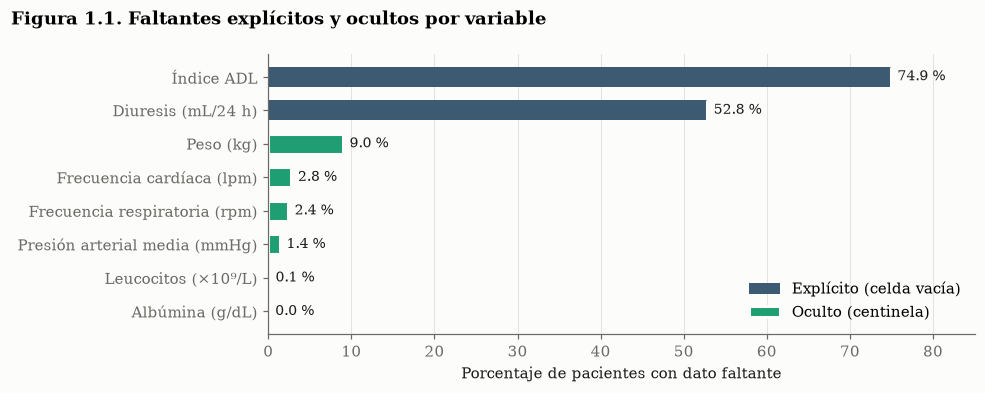

,explícito_%,total_%,oculto_%
adld3p,74.910,74.910,0.000
urin1,52.800,52.800,0.000
wtkilo1,0.000,8.980,8.980
hrt1,0.000,2.770,2.770
resp1,0.000,2.370,2.370
meanbp1,0.000,1.390,1.390
wblc1,0.000,0.070,0.070
alb1,0.000,0.030,0.030


In [5]:
miss = missingness_table(df_raw.drop(columns=["los", "log_los"]), df.drop(columns=["los", "log_los"]))
miss = miss.drop(index=["dthdte", "dschdte"], errors="ignore")  # fechas post-tratamiento

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(miss))[::-1]
ax.barh(y, miss["explícito_%"], color="#3d5a73", height=0.6, label="Explícito (celda vacía)")
ax.barh(y, miss["oculto_%"], left=miss["explícito_%"], color=viz.THIRD, height=0.6,
        label="Oculto (centinela)", edgecolor=viz.SURFACE, linewidth=2)
for yi, tot in zip(y, miss["total_%"]):
    ax.text(tot + 0.8, yi, f"{tot:.1f} %", va="center", fontsize=9, color=viz.INK)
ax.set_yticks(y, [cfg.LABELS.get(c, c) if c not in ("adld3p", "urin1") else
                  {"adld3p": "Índice ADL", "urin1": "Diuresis (mL/24 h)"}[c] for c in miss.index])
ax.set_xlabel("Porcentaje de pacientes con dato faltante")
ax.set_xlim(0, 85)
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
viz.figure_title(fig, "1.1", "Faltantes explícitos y ocultos por variable")
fig.tight_layout()
save(fig, "fig_1_1_faltantes")
plt.show()
miss.round(2)

## 1.2 Mecanismo de pérdida de datos: MCAR, MAR o MNAR

Sea $R_j$ el indicador de que la variable $X_j$ falta ($R_j = 1$). La clasificación de Rubin (1976) distingue:

- **MCAR** (*missing completely at random*): $P(R_j \mid X_{obs}, X_{mis}) = P(R_j)$. La pérdida no depende de nada.
- **MAR** (*missing at random*): $P(R_j \mid X_{obs}, X_{mis}) = P(R_j \mid X_{obs})$. Depende solo de variables observadas.
- **MNAR** (*missing not at random*): $P(R_j \mid X_{obs}, X_{mis})$ depende del propio valor no observado.

**Procedimiento.** Para cada variable se ajusta un modelo logit $R_j \sim Z + T$, con $Z$ = edad, APACHE, probabilidad de sobrevida, presión media, PaO₂/FiO₂, creatinina, orden de no reanimar, escala de coma e índice DASI. El test de razón de verosimilitud contrasta $H_0$: todos los coeficientes son nulos, que es la implicancia observable de MCAR; el estadístico sigue una $\chi^2$ con tantos grados de libertad como predictores. Rechazar $H_0$ descarta MCAR.

MNAR no puede demostrarse, porque el valor faltante es inobservable por definición. Como indicio se agrega el resultado $Y$ al logit: si $R_j$ se asocia con la mortalidad **aun condicionando en $Z$ y $T$**, la pérdida depende de información que $Z$ no captura.

In [6]:
Z_MISS = ["age", "aps1", "surv2md1", "meanbp1", "pafi1", "crea1", "dnr1", "scoma1", "das2d3pc"]
mech = pd.DataFrame([
    missingness_mechanism(df, col, [z for z in Z_MISS if z != col], cfg.TREATMENT, cfg.OUTCOME_BIN)
    for col in ["adld3p", "urin1", "wtkilo1", "hrt1", "resp1", "meanbp1"]
]).set_index("variable")
mech_show = mech.copy()
mech_show["p_MCAR"] = mech_show["p_MCAR"].map(inf.fmt_p)
mech_show["p_resultado | Z,T"] = mech_show["p_resultado | Z,T"].map(inf.fmt_p)
mech_show.round(2)

,faltante_%,"LR_chi2 (R~Z,T)",gl,p_MCAR,OR_tratamiento,"OR_resultado | Z,T","p_resultado | Z,T"
variable,,,,,,,
adld3p,74.910,"1,150.850",10,< 10⁻¹⁶,1.850,4.930,< 10⁻¹⁶
urin1,52.800,32.690,10,3.07 × 10⁻⁴,0.770,1.080,0.2430
wtkilo1,8.980,223.470,10,< 10⁻¹⁶,0.880,0.910,0.4208
hrt1,2.770,452.090,10,< 10⁻¹⁶,1.000,0.710,0.0726
resp1,2.370,366.520,10,< 10⁻¹⁶,0.680,0.600,0.0156
meanbp1,1.390,405.620,9,< 10⁻¹⁶,1.450,0.290,3.09 × 10⁻⁵


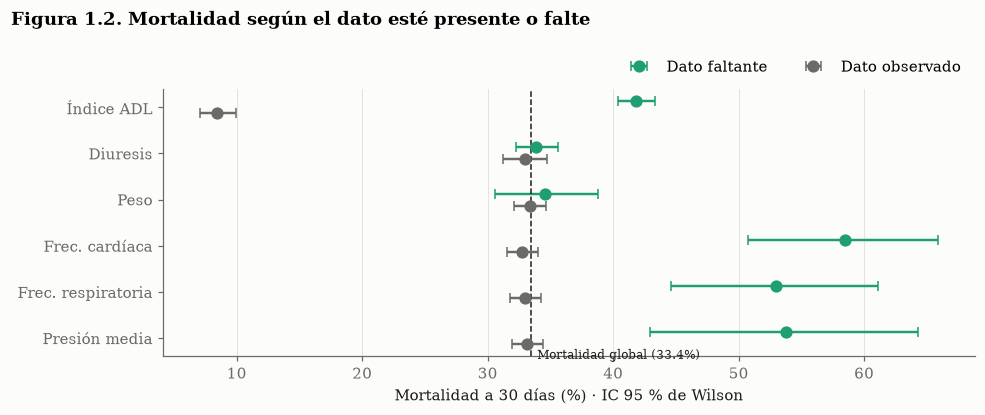

In [7]:
names = {"adld3p": "Índice ADL", "urin1": "Diuresis", "wtkilo1": "Peso",
         "hrt1": "Frec. cardíaca", "resp1": "Frec. respiratoria", "meanbp1": "Presión media"}
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, col in enumerate(list(names)[::-1]):
    for state, color, dy in [(True, viz.THIRD, 0.13), (False, viz.MUTED, -0.13)]:
        sub = df.loc[df[col].isna() == state, cfg.OUTCOME_BIN]
        lo, hi = inf.wilson_ci(sub.sum(), len(sub))
        ax.errorbar(sub.mean() * 100, i + dy, xerr=[[100 * (sub.mean() - lo)], [100 * (hi - sub.mean())]],
                    fmt="o", ms=7, color=color, capsize=3, lw=1.6,
                    label=("Dato faltante" if state else "Dato observado") if i == 0 else None)
ax.axvline(df[cfg.OUTCOME_BIN].mean() * 100, color=viz.INK, lw=1, ls="--")
ax.text(df[cfg.OUTCOME_BIN].mean() * 100 + 0.5, -0.45, f"Mortalidad global ({df[cfg.OUTCOME_BIN].mean():.1%})", fontsize=8, color=viz.INK)
ax.set_yticks(range(len(names)), list(names.values())[::-1])
ax.set_xlabel("Mortalidad a 30 días (%) · IC 95 % de Wilson")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.grid(axis="y", visible=False)
viz.figure_title(fig, "1.2", "Mortalidad según el dato esté presente o falte")
fig.tight_layout()
save(fig, "fig_1_2_mortalidad_faltantes")
plt.show()

**Interpretación y estrategia de imputación.** Se rechaza MCAR para las seis variables ($p < 0{,}001$ en todos los casos), de modo que **ninguna pérdida es completamente aleatoria** y eliminar filas incompletas (*listwise deletion*) sesgaría la muestra.

| Variable | Faltante | Diagnóstico | Evidencia | Estrategia |
|---|---|---|---|---|
| Índice ADL (`adld3p`) | 74,9 % | **MNAR probable** | Quienes no tienen el dato tienen 4,9 veces más chances de morir a 30 días aun ajustando por gravedad ($p < 10^{-49}$). El índice se relevaba con el paciente en los primeros días: falta justamente cuando el paciente no podía responder. | **Se excluye.** Imputarlo supondría MAR, y esa hipótesis es insostenible aquí. |
| Diuresis (`urin1`) | 52,8 % | **MAR** | La pérdida depende de $Z$ y de $T$ ($p = 0{,}0003$), pero no de $Y$ condicional en $Z$ ($p = 0{,}24$). | **Se excluye:** con más de la mitad imputada, la variable aportaría más ruido que información. |
| Peso (`wtkilo1`) | 9,0 % (oculto) | **MAR** | Depende de $Z$ ($p < 10^{-41}$) y no de $Y$ condicional en $Z$ ($p = 0{,}42$). | Mediana estimada solo en *train* + indicador de faltante. |
| Frecuencia cardíaca (`hrt1`) | 2,8 % (oculto) | **MAR** | Depende de $Z$ ($p < 10^{-90}$); asociación con $Y$ no significativa al 5 % ($p = 0{,}07$). | Mediana en *train* + indicador. |
| Frecuencia respiratoria y presión media (`resp1`, `meanbp1`) | 2,4 % y 1,4 % (oculto) | **MNAR posible** | Asociación con $Y$ aun condicionando en $Z$ ($p = 0{,}016$ y $p < 10^{-4}$). Sin ajustar, los pacientes con cero mueren más (53 %, Figura 1.2), pero su APACHE III medio es de 78 a 87 puntos frente a 54 del resto. Al condicionar en APACHE, la asociación se invierte (OR < 1): el cero ya está contabilizado dentro del score como un valor extremo, lo que sugiere que podría ser una **medición real** (paciente en paro cardiorrespiratorio) y no un faltante. | Mediana en *train* + **indicador**: el indicador preserva la información de que se registró un cero, sea faltante o paro. Se revisan en el análisis de sensibilidad de la Fase 4. |
| Diagnóstico secundario (`cat2`) | 79,1 % | **Estructural** | La ausencia significa "sin diagnóstico secundario". | Categoría propia. |

El **indicador de faltante** permite que los modelos aprovechen el carácter informativo de la pérdida (Figura 1.2) sin inventar el valor. La imputación por mediana se elige frente a la imputación iterativa porque afecta a menos del 10 % de cada variable, es transparente y se ajusta **exclusivamente sobre el conjunto de entrenamiento** dentro de los pipelines de las Fases 2 y 3, lo que evita la fuga de información del conjunto de prueba.

## 1.3 Análisis univariado: distribuciones y colas pesadas

La Figura 1.3 compara la distribución de las principales variables continuas entre pacientes con y sin RHC mediante estimaciones de densidad por núcleo (KDE).

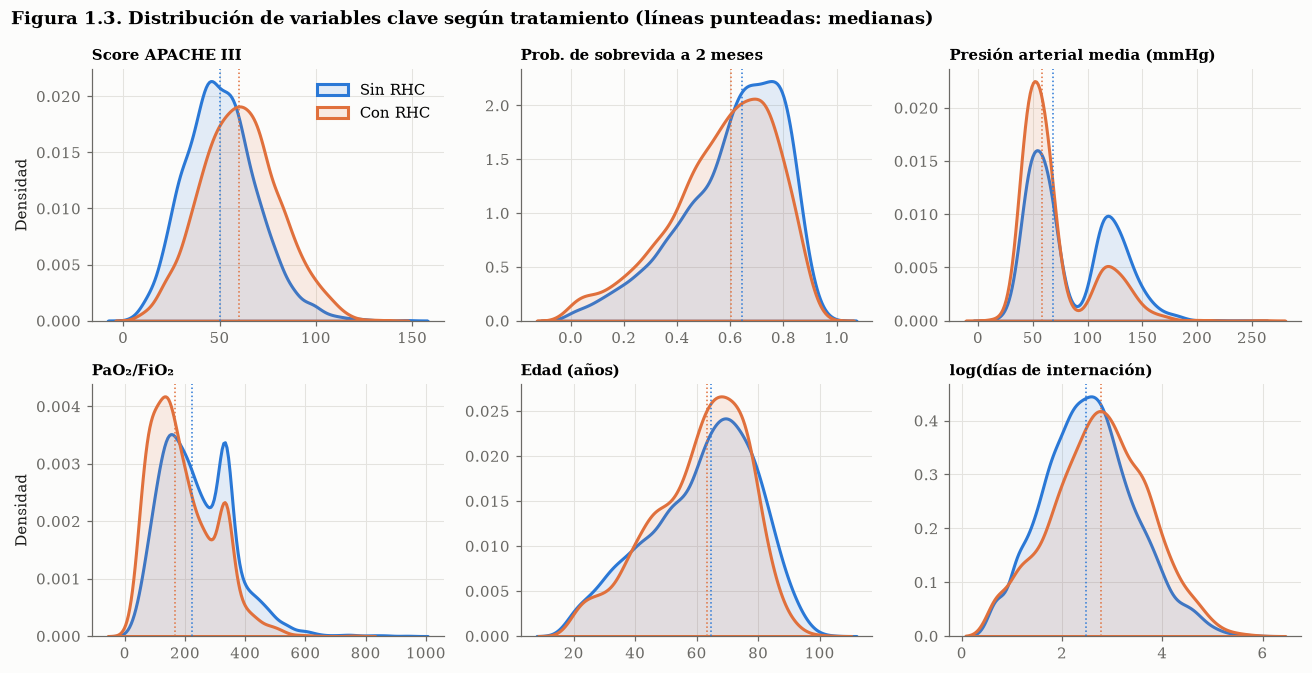

In [8]:
vars_kde = ["aps1", "surv2md1", "meanbp1", "pafi1", "age", "log_los"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, v in zip(axes.flat, vars_kde):
    for t, lab in [(0, "Sin RHC"), (1, "Con RHC")]:
        x = df.loc[df[cfg.TREATMENT] == t, v].dropna()
        sns.kdeplot(x, ax=ax, color=viz.GROUP_COLORS[t], lw=2, fill=True, alpha=0.12, label=lab)
        ax.axvline(x.median(), color=viz.GROUP_COLORS[t], lw=1, ls=":")
    ax.set_title({"surv2md1": "Prob. de sobrevida a 2 meses"}.get(v, cfg.LABELS[v]), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Densidad" if ax in axes[:, 0] else "")
axes[0, 0].legend(loc="upper right")
viz.figure_title(fig, "1.3", "Distribución de variables clave según tratamiento (líneas punteadas: medianas)")
fig.tight_layout()
save(fig, "fig_1_3_kde_tratamiento")
plt.show()

In [9]:
num_cols = cfg.NUMERIC_FEATURES + ["los"]
shape = pd.DataFrame({
    "n": df[num_cols].count(),
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "asimetría": df[num_cols].apply(lambda s: stats.skew(s.dropna())),
    "curtosis_exceso": df[num_cols].apply(lambda s: stats.kurtosis(s.dropna())),
}).sort_values("curtosis_exceso", ascending=False)
shape.round(2)

,n,media,mediana,asimetría,curtosis_exceso
bili1,5735,2.270,1.010,5.600,38.150
wblc1,5731,15.660,14.100,3.550,29.840
los,5734,21.490,14.000,3.910,25.270
crea1,5735,2.130,1.500,3.200,14.880
paco21,5735,38.750,37.000,2.170,9.180
wtkilo1,5220,74.520,72.200,1.210,3.830
ph1,5735,7.390,7.400,-1.220,3.480
pot1,5735,4.070,3.800,1.270,2.510
edu,5735,11.680,12.000,-0.090,1.960
sod1,5735,136.770,136.000,0.350,1.830


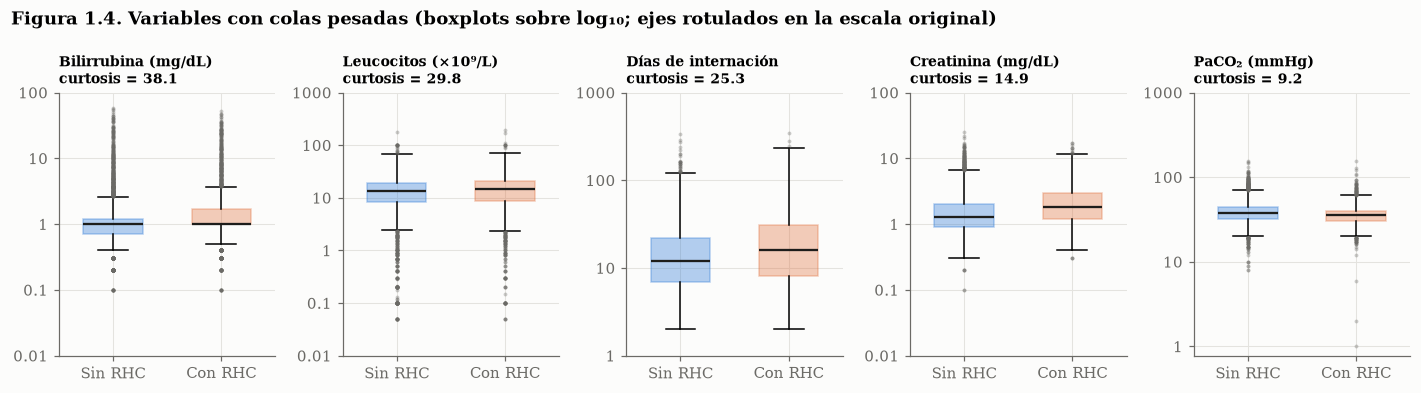

In [10]:
heavy = ["bili1", "wblc1", "los", "crea1", "paco21"]
fig, axes = plt.subplots(1, len(heavy), figsize=(13, 3.6))
for ax, v in zip(axes, heavy):
    data = [np.log10(df.loc[df[cfg.TREATMENT] == t, v].dropna()) for t in (0, 1)]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", ms=2.5, alpha=0.35, mec="none", mfc=viz.MUTED),
                    medianprops=dict(color=viz.INK, lw=1.5))
    for patch, t in zip(bp["boxes"], (0, 1)):
        patch.set(facecolor=viz.GROUP_COLORS[t], alpha=0.35, edgecolor=viz.GROUP_COLORS[t])
    ticks = np.arange(np.floor(min(d.min() for d in data)), np.ceil(max(d.max() for d in data)) + 1)
    ax.set_yticks(ticks, [f"{10 ** k:g}" for k in ticks])
    ax.set_xticks([1, 2], ["Sin RHC", "Con RHC"])
    ax.set_title(f"{cfg.LABELS[v]}\ncurtosis = {stats.kurtosis(df[v].dropna()):.1f}", fontsize=9)
viz.figure_title(fig, "1.4", "Variables con colas pesadas (boxplots sobre log₁₀; ejes rotulados en la escala original)")
fig.tight_layout()
save(fig, "fig_1_4_colas_pesadas")
plt.show()

**Interpretación.** La Figura 1.3 anticipa el problema central del trabajo: los pacientes con RHC llegan **más graves**. Su APACHE III está desplazado hacia la derecha, y su presión media y su índice PaO₂/FiO₂ (oxigenación), hacia la izquierda. Tratados y controles no son comparables al ingreso.

La tabla de forma y la Figura 1.4 documentan las **colas pesadas**: la bilirrubina (curtosis en exceso de 38), los leucocitos (30), los días de internación (25), la creatinina (15) y la PaCO₂ (9) se alejan marcadamente de la normal.

La auditoría también muestra cuánto puede fabricar un solo error. Sobre el dato crudo, la albúmina tenía una curtosis de 210; tras eliminar los dos valores imposibles (11 y 29 g/dL, probablemente 1,1 y 2,9 con la coma desplazada), la curtosis cae a 0,5. Esa "cola pesada" era un artefacto de tipeo, no una propiedad de la variable.

Dos consecuencias metodológicas se arrastran a las fases siguientes:

1. La duración de la internación se modela en **escala logarítmica**, que reduce la asimetría de 3,9 a 0,2 (Figura 1.3, panel inferior derecho).
2. Las asociaciones entre variables se miden también con **Spearman**, que es robusto a valores extremos (sección 1.4).

## 1.4 Análisis bivariado: Pearson frente a Spearman y confusión por diagnóstico

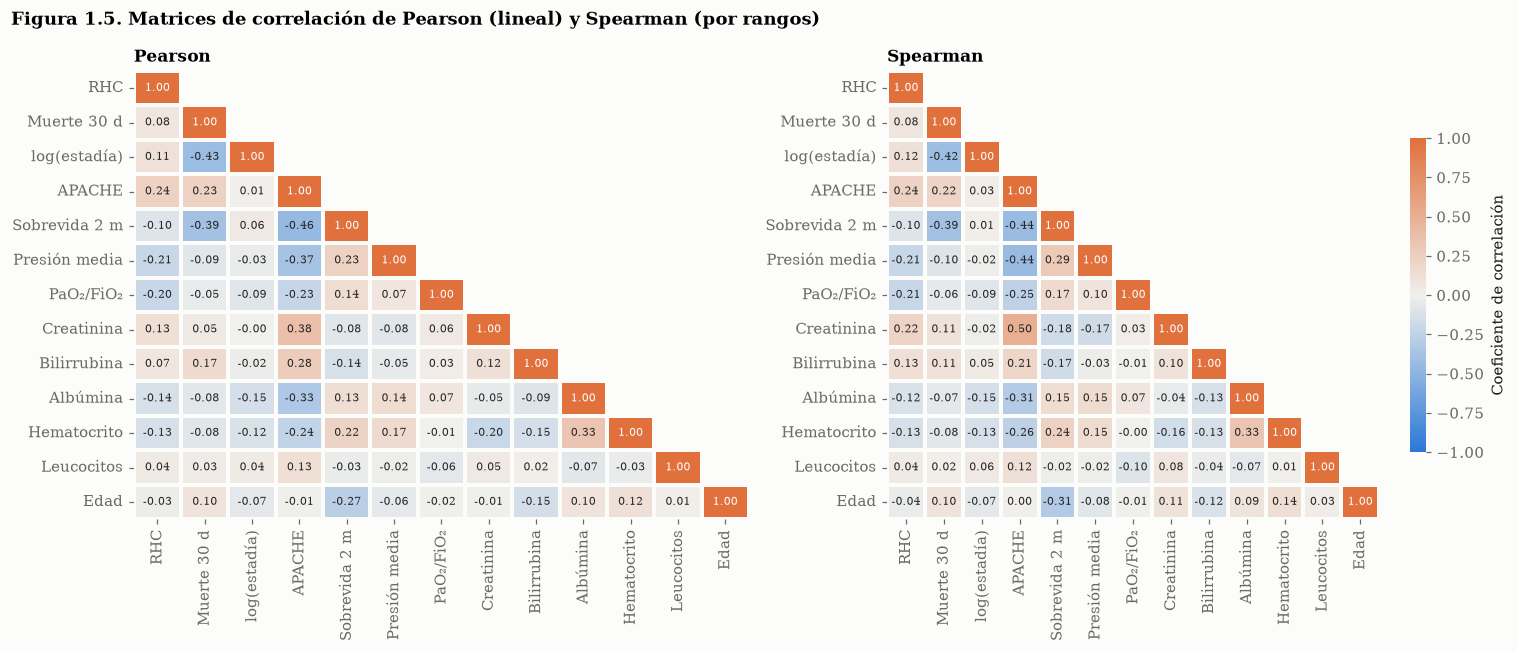

Mayores discrepancias |Spearman − Pearson|:
APACHE         Creatinina   0.122
Creatinina     Edad         0.117
Sobrevida 2 m  Creatinina   0.093
RHC            Creatinina   0.086
Presión media  Creatinina   0.082


In [11]:
corr_vars = ["rhc", "dth30", "log_los", "aps1", "surv2md1", "meanbp1", "pafi1",
             "crea1", "bili1", "alb1", "hema1", "wblc1", "age"]
short = {"rhc": "RHC", "dth30": "Muerte 30 d", "log_los": "log(estadía)", "aps1": "APACHE",
         "surv2md1": "Sobrevida 2 m", "meanbp1": "Presión media", "pafi1": "PaO₂/FiO₂",
         "crea1": "Creatinina", "bili1": "Bilirrubina", "alb1": "Albúmina",
         "hema1": "Hematocrito", "wblc1": "Leucocitos", "age": "Edad"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = df[corr_vars].corr(method=method).rename(index=short, columns=short)
    mask = np.triu(np.ones_like(c, dtype=bool), k=1)
    sns.heatmap(c, mask=mask, cmap=viz.DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=1.5, linecolor=viz.SURFACE, cbar=method == "spearman",
                cbar_kws={"shrink": 0.7, "label": "Coeficiente de correlación"}, ax=ax)
    ax.set_title(method.capitalize(), fontsize=11)
    ax.grid(False)
viz.figure_title(fig, "1.5", "Matrices de correlación de Pearson (lineal) y Spearman (por rangos)")
fig.tight_layout()
save(fig, "fig_1_5_correlaciones")
plt.show()

gap = (df[corr_vars].corr("spearman") - df[corr_vars].corr("pearson")).abs()
gap = gap.where(np.triu(np.ones_like(gap, dtype=bool), k=1)).stack().sort_values(ascending=False)
print("Mayores discrepancias |Spearman − Pearson|:")
print(gap.head(5).rename(index=short).round(3).to_string())

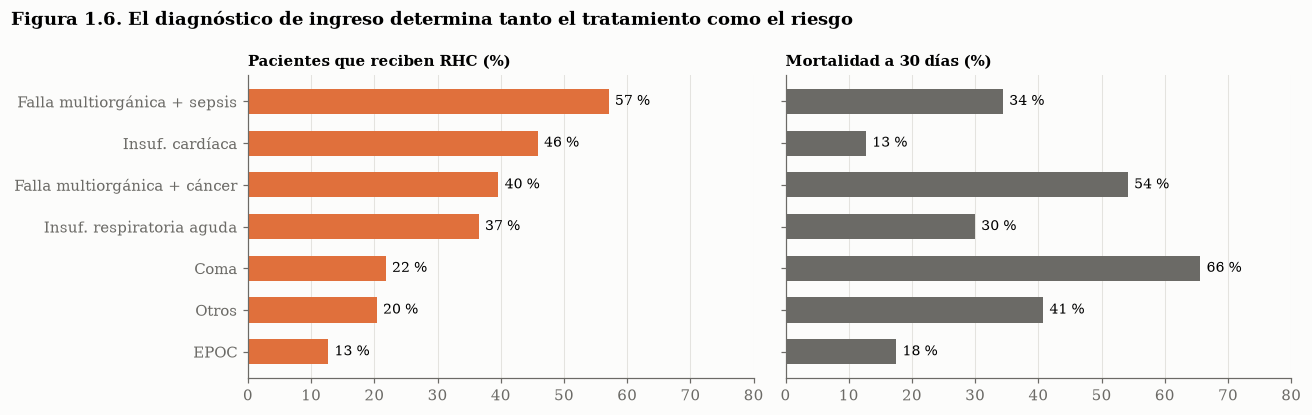

,n,tasa_RHC,mortalidad_30d,APACHE_medio
dx,,,,
EPOC,457,0.127,0.175,48.118
Otros,270,0.204,0.407,50.778
Coma,436,0.218,0.656,45.821
Insuf. respiratoria aguda,2490,0.365,0.300,53.847
Falla multiorgánica + cáncer,399,0.396,0.541,67.769
Insuf. cardíaca,456,0.458,0.127,39.443
Falla multiorgánica + sepsis,1227,0.570,0.344,64.169


In [12]:
# `dx` es el diagnóstico primario agrupado, definido en src/rhc/config.py (DX_MAP).
by_dx = df.groupby("dx", observed=True).agg(
    n=("rhc", "size"), tasa_RHC=("rhc", "mean"), mortalidad_30d=("dth30", "mean"),
    APACHE_medio=("aps1", "mean")).sort_values("tasa_RHC")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
yy = np.arange(len(by_dx))
axes[0].barh(yy, by_dx["tasa_RHC"] * 100, color=viz.RHC, height=0.6)
axes[1].barh(yy, by_dx["mortalidad_30d"] * 100, color=viz.MUTED, height=0.6)
for ax, col in zip(axes, ["tasa_RHC", "mortalidad_30d"]):
    for yi, v in zip(yy, by_dx[col]):
        ax.text(v * 100 + 1, yi, f"{v * 100:.0f} %", va="center", fontsize=9)
    ax.set_xlim(0, 80)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(yy, by_dx.index)
axes[0].set_title("Pacientes que reciben RHC (%)", fontsize=10)
axes[1].set_title("Mortalidad a 30 días (%)", fontsize=10)
viz.figure_title(fig, "1.6", "El diagnóstico de ingreso determina tanto el tratamiento como el riesgo")
fig.tight_layout()
save(fig, "fig_1_6_diagnostico")
plt.show()
by_dx.round(3)

**Interpretación.**

- **Pearson frente a Spearman.** Las discrepancias se concentran en las variables de colas pesadas (creatinina, bilirrubina): unos pocos valores extremos alteran el coeficiente de Pearson, mientras que Spearman, al trabajar con rangos, refleja mejor la asociación monótona.
- **Confusión por indicación.** El RHC se asocia con mayor gravedad (Spearman de 0,24 con APACHE, −0,21 con presión media y con PaO₂/FiO₂), y la gravedad se asocia con la mortalidad. Además, la Figura 1.6 muestra que el diagnóstico de ingreso condiciona ambas cosas: los pacientes con falla multiorgánica y sepsis reciben RHC con frecuencia mucho mayor que los pacientes en coma o con EPOC. El caso de la insuficiencia cardíaca es revelador: recibe RHC en el 46 % de los casos y, sin embargo, tiene la mortalidad más baja (13 %). El diagnóstico influye en el tratamiento por razones clínicas propias, no solo por gravedad. Es, por lo tanto, un **confusor** que debe incluirse en el conjunto de ajuste de la Fase 4.
- **Estadía y mortalidad.** La correlación entre log(estadía) y muerte a 30 días es fuertemente negativa (−0,42): quien muere temprano tiene, por construcción, una internación corta. Este **truncamiento por muerte** impide interpretar la duración de la internación como un indicador de mala evolución y se retoma en la Fase 4 al discutir colisionadores.
- **Multicolinealidad estructural.** El APACHE III es un score construido a partir de las variables fisiológicas del día 1, y la probabilidad de sobrevida a 2 meses es una predicción del modelo SUPPORT que también las incorpora. La colinealidad es, entonces, **estructural por diseño**: se cuantifica con VIF en la Fase 2.

## 1.5 Contrastes de hipótesis

Se plantean tres contrastes con relevancia directa para la decisión clínica. Todos son bilaterales, con $\alpha = 0{,}05$ fijado a priori.

| | Hipótesis | Pregunta de negocio | Estadístico elegido y justificación |
|---|---|---|---|
| **H1** | $H_0: \mu_{APACHE}^{RHC} = \mu_{APACHE}^{sin\,RHC}$ vs. $H_1: \neq$ | ¿Los pacientes tratados llegan más graves? (evidencia de confusión) | **t de Welch.** Con $n > 2.000$ por grupo, el TCL garantiza la normalidad aproximada de la media muestral; Welch no asume varianzas iguales. |
| **H2** | $H_0: p_{muerte}^{RHC} = p_{muerte}^{sin\,RHC}$ vs. $H_1: \neq$ | ¿Difiere la mortalidad a 30 días entre grupos? (efecto **ingenuo**) | **z de dos proporciones**, equivalente al $\chi^2$ de una tabla 2×2. Se cumple $n\hat p \geq 5$ y $n(1 - \hat p) \geq 5$. |
| **H3** | $H_0$: las distribuciones de días de internación son iguales vs. $H_1$: una está desplazada | ¿Los tratados consumen más días de cama? | **U de Mann-Whitney.** La curtosis de 25 desaconseja comparar medias; el test por rangos es robusto a las colas. |

Para cada contraste se reporta el estadístico, los grados de libertad, el $p$-valor exacto, el intervalo de confianza del 95 % para la diferencia y la magnitud del efecto.

In [13]:
t1 = df[cfg.TREATMENT] == 1
tests = pd.DataFrame({
    "H1 · APACHE III": inf.welch_test(df.loc[t1, "aps1"].to_numpy(), df.loc[~t1, "aps1"].to_numpy()),
    "H2 · Mortalidad 30 d": inf.two_proportions(df.loc[t1, "dth30"].to_numpy(), df.loc[~t1, "dth30"].to_numpy()),
    "H3 · Días de internación": inf.mann_whitney(df.loc[t1, "los"].dropna().to_numpy(),
                                                 df.loc[~t1, "los"].dropna().to_numpy()),
}).T
tests["p_valor"] = tests["p_valor"].astype(float).map(inf.fmt_p)
tests["decisión"] = ["Se rechaza H₀"] * 3
tests

,estadístico,valor,gl,p_valor,diferencia,IC_inf,IC_sup,efecto,medida_efecto,decisión
H1 · APACHE III,t de Welch,18.277,"4,356.759",< 10⁻¹⁶,9.805,8.754,10.857,0.506,d de Cohen,Se rechaza H₀
H2 · Mortalidad 30 d,z de dos proporciones,5.740,NaN,9.46 × 10⁻⁹,0.074,0.048,0.099,0.155,h de Cohen,Se rechaza H₀
H3 · Días de internación,U de Mann-Whitney,"4,422,828.500",NaN,< 10⁻¹⁶,4.000,3.000,5.000,0.141,biserial por rangos,Se rechaza H₀


In [14]:
h_obs = tests.loc["H2 · Mortalidad 30 d", "efecto"]
n1, n0 = int(t1.sum()), int((~t1).sum())
print(f"Potencia (1 − β) para detectar el efecto observado h = {h_obs:.3f}: "
      f"{inf.power_two_proportions(h_obs, n1, n0):.4f}")
print(f"Efecto mínimo detectable con 80 % de potencia y α = 0,05: h = {inf.min_detectable_h(n1, n0):.3f}")

Potencia (1 − β) para detectar el efecto observado h = 0.155: 0.9999
Efecto mínimo detectable con 80 % de potencia y α = 0,05: h = 0.076


**Interpretación.**

- **H1 · Gravedad.** Los pacientes con RHC tienen un APACHE III **9,8 puntos mayor** (IC 95 %: 8,8 a 10,9; $t = 18{,}3$ con 4.357 g.l.; $p = 5{,}8 \times 10^{-72}$). Una $d$ de Cohen de 0,51 indica un efecto **mediano**: la diferencia no es solo estadísticamente significativa, sino clínicamente relevante. Es evidencia directa de **confusión por indicación**: los médicos cateterizan a los pacientes más comprometidos.
- **H2 · Mortalidad.** La mortalidad a 30 días es de 38,0 % con RHC y 30,6 % sin RHC: una diferencia de **7,4 puntos porcentuales** (IC 95 %: 4,8 a 9,9; $z = 5{,}74$; $p = 9{,}5 \times 10^{-9}$). Este es el **efecto ingenuo**, y **no puede interpretarse como causal**, porque H1 mostró que los grupos no son comparables al ingreso. La Fase 4 estima cuánto de esta diferencia sobrevive al ajuste por confusores.
- **H3 · Uso de recursos.** La mediana de días de internación es **4 días mayor** en los pacientes tratados (IC 95 % bootstrap: 3 a 5; $p = 2{,}5 \times 10^{-19}$). La correlación biserial por rangos de 0,14 indica un efecto pequeño pero relevante para la planificación de camas de terapia intensiva.
- **Potencia.** Con 2.184 tratados y 3.551 controles, el estudio detecta con 80 % de potencia cualquier efecto $h \geq 0{,}076$. El efecto observado ($h = 0{,}155$) duplica ese umbral, y la potencia resultante es prácticamente 1. **El riesgo en este dataset no es la falta de potencia, sino el sesgo**: con $n$ grande, hasta un efecto espurio producido por confusión resulta "significativo".

## 1.6 ANOVA de un factor: días de internación según diagnóstico de ingreso

**Diseño.** Se evalúa si el valor esperado de log(días de internación) varía entre los siete grupos diagnósticos de la Figura 1.6:

$$H_0: \mu_1 = \mu_2 = \cdots = \mu_7 \qquad \text{vs.} \qquad H_1: \exists\, i \neq j \;/\; \mu_i \neq \mu_j$$

Las categorías cirrosis, cáncer de pulmón y cáncer de colon se agrupan en "Otros" porque el cáncer de colon tiene solo 7 pacientes y el de pulmón 39: grupos tan pequeños inflan la varianza del ANOVA y vuelven inestables las comparaciones *post-hoc*.

### El desafío metodológico: Shapiro-Wilk con muestras grandes

Con $n = 2.490$ en el grupo más numeroso, el test de Shapiro-Wilk tiene potencia para rechazar $H_0$ ante desviaciones microscópicas y sin consecuencias prácticas. Por eso el supuesto de normalidad se evalúa con **asimetría, curtosis y gráficos Q-Q**, y Shapiro-Wilk se reporta solo como referencia.

In [15]:
anova_df = df.dropna(subset=["los"])
norm = pd.concat({
    "Días (escala original)": inf.normality_profile({k: g["los"].to_numpy() for k, g in anova_df.groupby("dx", observed=True)}),
    "log(días)": inf.normality_profile({k: g["log_los"].to_numpy() for k, g in anova_df.groupby("dx", observed=True)}),
})
norm["p_SW"] = norm["p_SW"].map(inf.fmt_p)
norm.round(3)

grupo     n  asimetría  \
Días (escala original) 0     Insuf. respiratoria aguda  2490      3.265   
                       1  Falla multiorgánica + sepsis  1226      3.756   
                       2  Falla multiorgánica + cáncer   399      2.146   
                       3               Insuf. cardíaca   456      3.836   
                       4                          EPOC   457      5.293   
                       5                          Coma   436      3.466   
                       6                         Otros   270      3.777   
log(días)              0     Insuf. respiratoria aguda  2490      0.136   
                       1  Falla multiorgánica + sepsis  1226      0.008   
                       2  Falla multiorgánica + cáncer   399     -0.015   
                       3               Insuf. cardíaca   456      0.453   
                       4                          EPOC   457      0.513   
                       5                          Coma   436      0.315   
                       6                         Otros   270      0.108   

                          curtosis_exceso  Shapiro-Wilk W         p_SW  
Días (escala original) 0           15.538           0.675      < 10⁻¹⁶  
                       1           22.400           0.658      < 10⁻¹⁶  
                       2            6.693           0.794      < 10⁻¹⁶  
                       3           19.771           0.607      < 10⁻¹⁶  
                       4           44.115           0.540      < 10⁻¹⁶  
                       5           18.569           0.658      < 10⁻¹⁶  
                       6           22.691           0.675      < 10⁻¹⁶  
log(días)              0           -0.091           0.994  3.71 × 10⁻⁸  
                       1           -0.298           0.994  1.44 × 10⁻⁴  
                       2           -0.653           0.986  8.48 × 10⁻⁴  
                       3            0.169           0.979  4.58 × 10⁻⁶  
                       4            0.587           0.980  5.66 × 10⁻⁶  
                       5           -0.757           0.965  9.54 × 10⁻⁹  
                       6           -0.162           0.989       0.0475

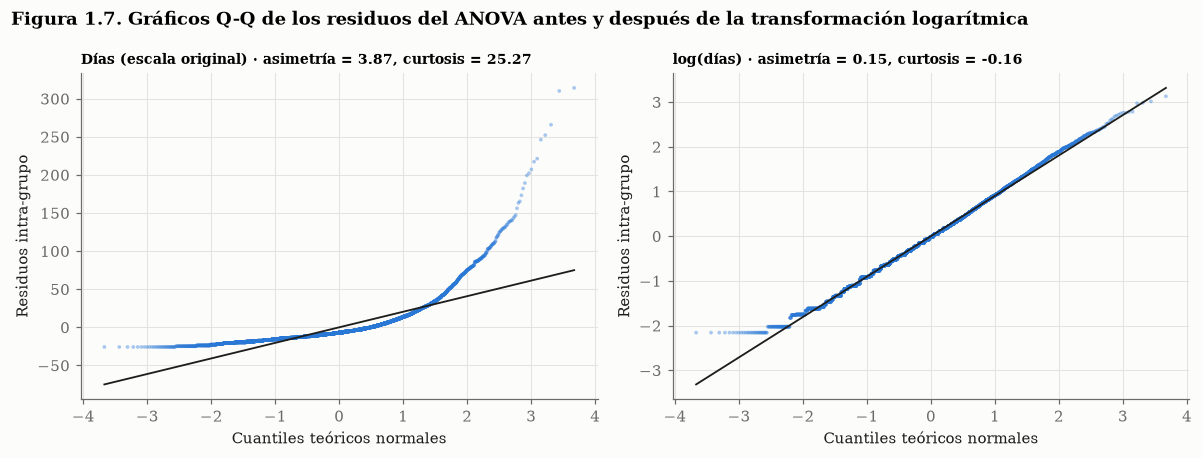

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, v, title in [(axes[0], "los", "Días (escala original)"), (axes[1], "log_los", "log(días)")]:
    resid = anova_df[v] - anova_df.groupby("dx", observed=True)[v].transform("mean")
    (osm, osr), (slope, intercept, _) = stats.probplot(resid, dist="norm")
    ax.scatter(osm, osr, s=6, alpha=0.4, color=viz.NO_RHC, edgecolor="none")
    ax.plot(osm, slope * osm + intercept, color=viz.INK, lw=1.2)
    ax.set_title(f"{title} · asimetría = {stats.skew(resid):.2f}, curtosis = {stats.kurtosis(resid):.2f}", fontsize=9)
    ax.set_xlabel("Cuantiles teóricos normales")
    ax.set_ylabel("Residuos intra-grupo")
viz.figure_title(fig, "1.7", "Gráficos Q-Q de los residuos del ANOVA antes y después de la transformación logarítmica")
fig.tight_layout()
save(fig, "fig_1_7_qq_anova")
plt.show()

**Lectura de la normalidad.** En escala original, los residuos tienen una cola derecha muy pesada (Figura 1.7, izquierda) y Shapiro-Wilk rechaza con $W$ entre 0,54 y 0,79. Tras la transformación logarítmica, la asimetría por grupo queda entre 0,0 y 0,5, la curtosis en exceso cerca de cero, y los puntos del Q-Q se alinean con la recta salvo en los extremos. Shapiro-Wilk **sigue rechazando** ($W \geq 0{,}96$), lo que ilustra la advertencia anterior: la desviación residual es irrelevante para el TCL con grupos de 270 a 2.490 observaciones. Se adopta **log(días)** como variable de respuesta.

In [17]:
res = inf.anova_battery(anova_df, "log_los", "dx")
anova_tab = pd.DataFrame({
    "Estadístico": [res["F_clásico"], res["Levene_W"], res["F_Welch"], res["H_Kruskal"]],
    "g.l.": [f"({res['gl'][0]}, {res['gl'][1]})", f"({res['gl'][0]}, {res['gl'][1]})",
             f"({res['gl_Welch'][0]:.0f}, {res['gl_Welch'][1]:.1f})", f"{res['gl'][0]}"],
    "p-valor": [inf.fmt_p(res[k]) for k in ["p_F", "p_Levene", "p_Welch", "p_Kruskal"]],
}, index=["ANOVA clásico (F)", "Levene / Brown-Forsythe (W)", "ANOVA de Welch (F)", "Kruskal-Wallis (H)"])
display(anova_tab.round(2))
print(f"Tamaño del efecto: η² = {res['eta2']:.3f} · ω² = {res['omega2']:.3f} · ε² (Kruskal-Wallis) = {res['epsilon2_KW']:.3f}")

,Estadístico,g.l.,p-valor
ANOVA clásico (F),49.990,"(6, 5727)",< 10⁻¹⁶
Levene / Brown-Forsythe (W),14.170,"(6, 5727)",4.35 × 10⁻¹⁶
ANOVA de Welch (F),49.870,"(6, 1358.1)",< 10⁻¹⁶
Kruskal-Wallis (H),284.460,6,< 10⁻¹⁶


Tamaño del efecto: η² = 0.050 · ω² = 0.049 · ε² (Kruskal-Wallis) = 0.050


**Interpretación.** El test de Levene en su versión de Brown-Forsythe (centrado en la mediana, robusta a colas) **rechaza la homogeneidad de varianzas**: el desvío de log(días) va de 0,81 (EPOC) a 1,02 (coma). Con varianzas y tamaños de grupo desiguales, el $F$ clásico puede distorsionar el error de tipo I, de modo que la decisión se apoya en dos alternativas robustas:

- el **ANOVA de Welch**, que pondera cada grupo por la inversa de su varianza y corrige los grados de libertad del denominador;
- el test de **Kruskal-Wallis**, no paramétrico, que compara rangos.

Ambos rechazan $H_0$ con $p$-valores prácticamente nulos: **la duración esperada de la internación difiere según el diagnóstico de ingreso.** El tamaño del efecto es pequeño ($\omega^2 \approx 0{,}05$): el diagnóstico explica alrededor del 5 % de la variabilidad de log(días). Es una señal clara pero insuficiente por sí sola para predecir la estadía, lo que justifica el modelo multivariado de la Fase 2.

In [18]:
ph = inf.posthoc(anova_df, "log_los", "dx")
ph_show = ph.copy()
for c in ["p_Tukey", "p_Bonferroni"]:
    ph_show[c] = ph_show[c].astype(float).map(inf.fmt_p)
print(f"Pares significativos: Tukey = {ph['rechaza_Tukey'].sum()} · Bonferroni = {ph['rechaza_Bonferroni'].sum()} "
      f"de {len(ph)} · Coincidencia de decisiones: {(ph['rechaza_Tukey'] == ph['rechaza_Bonferroni']).mean():.0%}")
ph_show.round(3)

Pares significativos: Tukey = 14 · Bonferroni = 14 de 21 · Coincidencia de decisiones: 100%


,group1,group2,dif_medias,p_Tukey,p_Bonferroni,rechaza_Tukey,rechaza_Bonferroni
0,Coma,EPOC,0.242,0.0013,0.0022,True,True
1,Coma,Falla multiorgánica + cáncer,0.180,0.0625,0.1391,False,False
2,Coma,Falla multiorgánica + sepsis,0.573,< 10⁻¹⁶,< 10⁻¹⁶,True,True
3,Coma,Insuf. cardíaca,-0.054,0.9727,1.0000,False,False
4,Coma,Insuf. respiratoria aguda,0.441,< 10⁻¹⁶,5.30 × 10⁻¹⁵,True,True
5,Coma,Otros,0.081,0.9085,1.0000,False,False
6,EPOC,Falla multiorgánica + cáncer,-0.062,0.9547,1.0000,False,False
7,EPOC,Falla multiorgánica + sepsis,0.331,< 10⁻¹⁶,8.34 × 10⁻¹¹,True,True
8,EPOC,Insuf. cardíaca,-0.296,< 10⁻¹⁶,1.17 × 10⁻⁶,True,True
9,EPOC,Insuf. respiratoria aguda,0.199,3.00 × 10⁻⁴,5.09 × 10⁻⁵,True,True


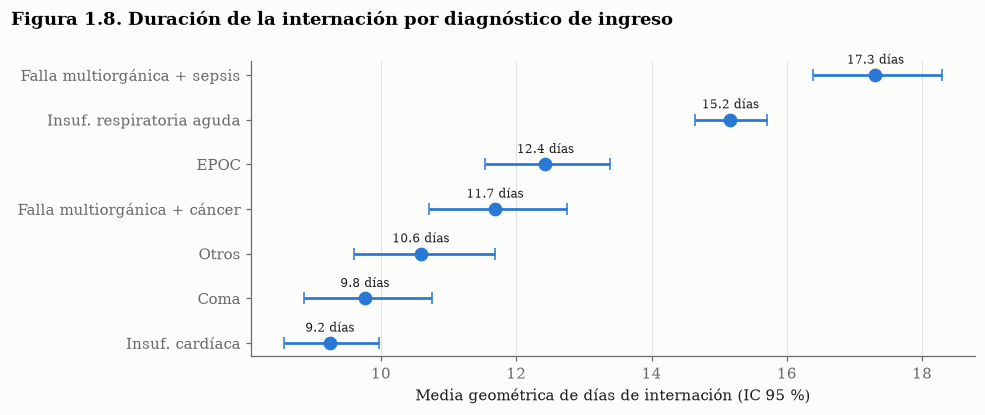

In [19]:
summ = anova_df.groupby("dx", observed=True)["log_los"].agg(["mean", "std", "count"]).sort_values("mean")
summ["ic"] = stats.t.ppf(0.975, summ["count"] - 1) * summ["std"] / np.sqrt(summ["count"])
fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(summ))
ax.errorbar(np.exp(summ["mean"]), yy,
            xerr=[np.exp(summ["mean"]) - np.exp(summ["mean"] - summ["ic"]),
                  np.exp(summ["mean"] + summ["ic"]) - np.exp(summ["mean"])],
            fmt="o", ms=8, color=viz.NO_RHC, ecolor=viz.NO_RHC, capsize=4, lw=1.8)
for yi, m in zip(yy, np.exp(summ["mean"])):
    ax.text(m, yi + 0.25, f"{m:.1f} días", ha="center", fontsize=8, color=viz.INK)
ax.set_yticks(yy, summ.index)
ax.set_xlabel("Media geométrica de días de internación (IC 95 %)")
ax.grid(axis="y", visible=False)
viz.figure_title(fig, "1.8", "Duración de la internación por diagnóstico de ingreso")
fig.tight_layout()
save(fig, "fig_1_8_anova_medias")
plt.show()

**Comparaciones múltiples.** Con 7 grupos hay 21 comparaciones de a pares. Sin corrección, la probabilidad de cometer al menos un error de tipo I sería $1 - 0{,}95^{21} \approx 66\%$. Se contrastan dos formas de controlar la tasa de error por familia:

- **Tukey HSD**: usa la distribución del rango studentizado y supone varianzas iguales.
- **Bonferroni sobre tests t de Welch**: más conservador ($\alpha / 21$ por comparación), pero válido con varianzas desiguales.

**Ambos métodos coinciden en las 21 decisiones** (14 pares con diferencias significativas), por lo que las conclusiones no dependen del supuesto de homocedasticidad que Levene rechazó. La falla multiorgánica con sepsis es el diagnóstico con internaciones más largas (media geométrica de 17,3 días), seguida por la insuficiencia respiratoria aguda (15,2 días). La insuficiencia cardíaca y el coma, en cambio, tienen las estadías más cortas (alrededor de 9,5 días) y no difieren significativamente entre sí. En el caso del coma, la estadía corta se explica en parte por el truncamiento por muerte identificado en la sección 1.4.

## 1.7 Síntesis de la Fase 1

| Hallazgo | Consecuencia para las fases siguientes |
|---|---|
| 896 valores centinela ocultos; el peso tenía 9 % de ceros imposibles | Se recodifican como faltantes; imputación por mediana **solo en train** + indicador |
| Ninguna pérdida es MCAR; el índice ADL es probablemente MNAR | `adld3p` y `urin1` se excluyen; los indicadores de faltante se conservan como predictores |
| Colas pesadas (curtosis en exceso de hasta 38) | Respuesta continua en escala logarítmica; se privilegian métodos robustos |
| Los tratados son más graves ($d = 0{,}51$ en APACHE) | La diferencia ingenua de mortalidad (+7,4 pp) está confundida: requiere el ajuste causal de la Fase 4 |
| El diagnóstico condiciona tratamiento y resultado | Es un confusor obligatorio en el DAG |
| La estadía está truncada por la muerte | No se usa como mediador ni como control en la Fase 4 |
| Colinealidad estructural entre APACHE y la fisiología | Se diagnostica con VIF en la Fase 2 |

---
# Fase 2. Diagnóstico de Gauss-Markov, puntos influyentes y PCA

Esta fase estima un modelo lineal de referencia para la duración de la internación, una variable clave para la planificación de camas de terapia intensiva, y audita con rigor los supuestos que respaldan su inferencia. Cierra con una reducción de dimensionalidad por componentes principales ajustada sin fuga de información.

## 2.1 Partición train/test y contrato sin fuga de datos

La partición se define una única vez en esta fase y se reutiliza en las Fases 3 y 4. Se reserva el 20 % de los pacientes como conjunto de prueba, con estratificación conjunta por mortalidad a 30 días y tratamiento, de modo que ambos subconjuntos conserven las mismas proporciones. A partir de aquí, **todo parámetro aprendido de los datos se estima exclusivamente sobre train**: las medianas de imputación, las medias y desvíos de la estandarización, la rotación del PCA y los coeficientes de los modelos. El conjunto de prueba solo se utiliza para evaluar.

In [20]:
import statsmodels.api as sm

from rhc import regression as reg
from rhc.features import build_pca, build_preprocessor, load_model_frame, split

data = load_model_frame()
train, test = split(data)
balance = pd.DataFrame({
    "n": [len(train), len(test)],
    "mortalidad_30d": [train["dth30"].mean(), test["dth30"].mean()],
    "proporción_RHC": [train["rhc"].mean(), test["rhc"].mean()],
    "log_estadía_media": [train["log_los"].mean(), test["log_los"].mean()],
}, index=["Train (80 %)", "Test (20 %)"])
balance.round(4)

,n,mortalidad_30d,proporción_RHC,log_estadía_media
Train (80 %),4588,0.334,0.381,2.631
Test (20 %),1147,0.335,0.381,2.592


## 2.2 Especificación del modelo lineal de referencia

$$\log(\text{días de internación})_i = \beta_0 + \sum_{j=1}^{p} \beta_j X_{ij} + \varepsilon_i, \qquad \varepsilon_i \sim (0, \sigma^2)$$

**Regresores.** Las 21 variables numéricas basales (demografía, scores de gravedad y fisiología del día 1), los indicadores de valor faltante de peso, frecuencia cardíaca, frecuencia respiratoria y presión media, 21 comorbilidades e indicadores de diagnóstico de admisión, la orden de no reanimar, la presencia de diagnóstico secundario, el tratamiento RHC y las dummies de diagnóstico agrupado, cáncer, sexo, raza, ingreso y cobertura médica.

**Categorías de referencia.** Cada variable categórica entra con $k - 1$ dummies para evitar la colinealidad perfecta con la constante. La referencia es la categoría más frecuente o la basal: insuficiencia respiratoria aguda, sin cáncer, mujer, raza blanca, ingreso menor a USD 11.000 y cobertura privada.

**Exclusiones.** Se excluyen las fechas y resultados posteriores a la admisión (fuga de información), el índice ADL y la diuresis (Fase 1, sección 1.2) y el antecedente de malignidad `malighx` (sección 2.6).

**Advertencia de interpretación.** El coeficiente de RHC en este modelo es **asociativo**: mide la diferencia de estadía entre pacientes tratados y no tratados con iguales covariables observadas, sin aislar el efecto causal del procedimiento. La pregunta causal se aborda en la Fase 4.

In [21]:
tr = train.dropna(subset=["log_los"])
te = test.dropna(subset=["log_los"])
pre = build_preprocessor()
X_tr = pre.fit_transform(tr).astype(float)
X_te = pre.transform(te).astype(float)
y_tr, y_te = tr["log_los"], te["log_los"]

ols = reg.fit_ols(X_tr, y_tr)
n, p = int(ols.nobs), int(ols.df_model)
print(f"Observaciones: n = {n:,} · Regresores: p = {p}")
print(f"R² = {ols.rsquared:.4f} · R² ajustado = {ols.rsquared_adj:.4f}")
print(f"F({p}, {int(ols.df_resid)}) = {ols.fvalue:.2f} · p-valor = {inf.fmt_p(ols.f_pvalue)}")
print(f"R² fuera de muestra (test) = {reg.r2_out_of_sample(ols, X_te, y_te):.4f}")

Observaciones: n = 4,587 · Regresores: p = 68
R² = 0.1454 · R² ajustado = 0.1326
F(68, 4518) = 11.31 · p-valor = < 10⁻¹⁶
R² fuera de muestra (test) = 0.0991


**Interpretación del ajuste global.** El estadístico $F$ rechaza contundentemente la hipótesis de que todos los coeficientes son nulos: el conjunto de covariables basales explica una parte de la variabilidad de la estadía. Sin embargo, esa parte es modesta ($R^2 = 0{,}145$; 0,099 en test). Esto es esperable por dos razones. Primero, la duración de la internación depende en gran medida de la evolución clínica posterior al ingreso, que ninguna variable basal registra. Segundo, el **truncamiento por muerte** identificado en la Fase 1 hace que pacientes muy graves tengan estadías cortas porque fallecen pronto, lo que introduce una relación no monótona entre gravedad y estadía que un modelo lineal no captura.

## 2.3 Coeficientes y significancia individual

Los contrastes $t$ individuales ($H_0: \beta_j = 0$) se calculan con errores estándar robustos HC3, por las razones expuestas en la sección 2.4. Con respuesta logarítmica, $100 \cdot (e^{\beta_j} - 1)$ es el cambio porcentual esperado en la estadía ante un aumento unitario de $X_j$, con el resto constante.

In [22]:
coefs = reg.coefficient_table(ols)
top = coefs.reindex(coefs["t"].abs().sort_values(ascending=False).index).head(15)
top_show = top[["beta", "ee_MCO", "ee_HC3", "t", "p_valor", "efecto_%", "efecto_%_inf", "efecto_%_sup"]].copy()
top_show["p_valor"] = top_show["p_valor"].map(inf.fmt_p)
print(f"Coeficientes significativos al 5 % (HC3): {(coefs['p_valor'] < cfg.ALPHA).sum()} de {len(coefs)}")
top_show.round(4)

Coeficientes significativos al 5 % (HC3): 18 de 68


,beta,ee_MCO,ee_HC3,t,p_valor,efecto_%,efecto_%_inf,efecto_%_sup
dnr1,-0.550,0.042,0.043,-12.696,< 10⁻¹⁶,-42.297,-46.994,-37.184
alb1,-0.144,0.021,0.021,-6.713,2.14 × 10⁻¹¹,-13.439,-17.011,-9.713
dx_Insuf. cardíaca,-0.403,0.068,0.066,-6.081,1.29 × 10⁻⁹,-33.195,-41.341,-23.917
dx_Coma,-0.362,0.068,0.075,-4.811,1.55 × 10⁻⁶,-30.345,-39.890,-19.285
dx_Otros,-0.368,0.082,0.076,-4.809,1.57 × 10⁻⁶,-30.770,-40.408,-19.573
hema1,-0.009,0.002,0.002,-4.761,1.98 × 10⁻⁶,-0.883,-1.244,-0.520
rhc,0.134,0.030,0.030,4.407,1.07 × 10⁻⁵,14.317,7.710,21.328
renalhx,-0.263,0.076,0.079,-3.314,9.27 × 10⁻⁴,-23.128,-34.206,-10.186
aps1,-0.004,0.001,0.001,-3.164,0.0016,-0.419,-0.678,-0.160
ph1,0.479,0.153,0.162,2.949,0.0032,61.437,17.418,121.958


**Interpretación de los coeficientes principales** (efectos porcentuales con IC 95 % robusto en la tabla):

- **Orden de no reanimar** (`dnr1`): reduce la estadía esperada en torno a 42 %. No es un efecto terapéutico: estos pacientes reciben medidas de soporte limitadas y fallecen antes.
- **Coma** como diagnóstico de ingreso: estadía alrededor de 30 % más corta que la insuficiencia respiratoria aguda, por el mismo mecanismo de truncamiento.
- **RHC**: los pacientes cateterizados permanecen internados alrededor de 14 % más tiempo que pacientes comparables no cateterizados. La asociación es robusta, pero no causal.
- **APACHE III**: cada 10 puntos adicionales se asocian con una estadía alrededor de 4 % **menor**. El signo negativo contradice la intuición de que más gravedad implica más días de cama y vuelve a evidenciar el truncamiento por muerte: condicionado en el resto de las covariables, el score captura sobre todo el riesgo de fallecer pronto.

## 2.4 Auditoría de los supuestos de Gauss-Markov

| Supuesto | Hipótesis nula | Contraste |
|---|---|---|
| Homocedasticidad: $\text{Var}(\varepsilon_i \mid X) = \sigma^2$ | $H_0$: los residuos al cuadrado no dependen de $X$ | Breusch-Pagan (LM $\sim \chi^2_p$) |
| Normalidad de los errores | $H_0$: asimetría = 0 y curtosis = 3 | Jarque-Bera ($\sim \chi^2_2$) |
| Independencia de los errores | $H_0$: autocorrelación de primer orden nula | Durbin-Watson, con los residuos ordenados por fecha de admisión |

Se utiliza Breusch-Pagan y no White porque, con 68 regresores, la regresión auxiliar de White incluiría alrededor de 2.400 términos (niveles, cuadrados y productos cruzados), una cantidad cercana al número de observaciones que deja al contraste sin grados de libertad efectivos.

In [23]:
order = tr["sadmdte"].to_numpy().argsort()
gm = reg.gauss_markov_tests(ols, order=order)
gm["p_valor"] = gm["p_valor"].map(lambda v: inf.fmt_p(v) if pd.notna(v) else "")
gm.round(4)

,estadístico,g.l.,p_valor,detalle
Breusch-Pagan (LM),175.206,68.000,2.09 × 10⁻¹¹,F = 2.64 (p = 1.10e-11)
Jarque-Bera,13.615,2.000,0.0011,asimetría = 0.125; curtosis = 2.906
Durbin-Watson,1.979,NaN,,valores cercanos a 2 indican ausencia de autoc...


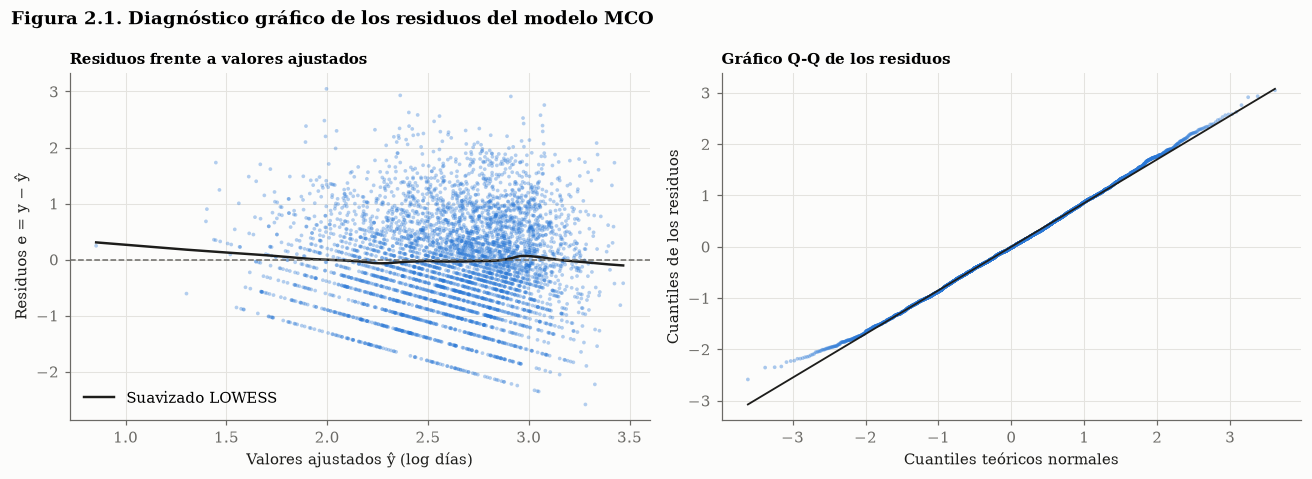

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
fitted, resid = ols.fittedvalues, ols.resid
axes[0].scatter(fitted, resid, s=6, alpha=0.35, color=viz.NO_RHC, edgecolor="none")
smooth = sm.nonparametric.lowess(resid, fitted, frac=0.3)
axes[0].plot(smooth[:, 0], smooth[:, 1], color=viz.INK, lw=1.6, label="Suavizado LOWESS")
axes[0].axhline(0, color=viz.MUTED, lw=1, ls="--")
axes[0].set_xlabel("Valores ajustados ŷ (log días)")
axes[0].set_ylabel("Residuos e = y − ŷ")
axes[0].set_title("Residuos frente a valores ajustados", fontsize=10)
axes[0].legend(loc="lower left")

(osm, osr), (slope, intercept, _) = stats.probplot(resid, dist="norm")
axes[1].scatter(osm, osr, s=6, alpha=0.4, color=viz.NO_RHC, edgecolor="none")
axes[1].plot(osm, slope * osm + intercept, color=viz.INK, lw=1.2)
axes[1].set_xlabel("Cuantiles teóricos normales")
axes[1].set_ylabel("Cuantiles de los residuos")
axes[1].set_title("Gráfico Q-Q de los residuos", fontsize=10)
viz.figure_title(fig, "2.1", "Diagnóstico gráfico de los residuos del modelo MCO")
fig.tight_layout()
save(fig, "fig_2_1_residuos")
plt.show()

**Interpretación.**

- **Homocedasticidad.** Breusch-Pagan rechaza $H_0$ con amplio margen. En la Figura 2.1 (izquierda), la dispersión de los residuos es mayor en el centro del rango de valores ajustados que en los extremos. Bajo heterocedasticidad, los estimadores MCO siguen siendo insesgados, pero dejan de ser los de mínima varianza y los errores estándar clásicos son inconsistentes. **Remediación:** toda la inferencia del modelo se realiza con la matriz de covarianza robusta HC3 de MacKinnon y White (1985), que no requiere especificar la forma de la heterocedasticidad. La corrección modifica los errores estándar un 3 % en la mediana y menos de 10 % en nueve de cada diez coeficientes. El mayor cambio (41 %) corresponde a la admisión ortopédica, una categoría con solo 5 pacientes. Ningún coeficiente cambia su decisión de significancia al 5 % al pasar de los errores clásicos a los robustos.
Las bandas diagonales del gráfico no indican un problema de especificación: la estadía es un número entero de días, de modo que, para cada valor observado de $y$, los residuos $e = y - \hat y$ se alinean sobre una recta de pendiente $-1$.
- **Normalidad.** Jarque-Bera rechaza $H_0$ ($p \approx 0{,}001$), pero la asimetría (0,13) y la curtosis (2,91) son prácticamente las de una normal, y el gráfico Q-Q sigue la recta salvo en las colas extremas. Con $n = 4.587$, el contraste detecta desviaciones irrelevantes para la inferencia: el teorema central del límite garantiza la normalidad asintótica de $\hat\beta$. La transformación logarítmica de la Fase 1 cumplió su propósito.
- **Independencia.** Con los residuos ordenados por fecha de admisión, el estadístico de Durbin-Watson es 1,98, prácticamente igual al valor de referencia de 2: no hay autocorrelación temporal entre pacientes admitidos en fechas consecutivas.

## 2.5 Observaciones atípicas, de alto apalancamiento e influyentes

Se descompone el impacto de cada observación en tres dimensiones complementarias, con los umbrales del enunciado:

- **Atípicos en la respuesta**: residuo estudentizado externamente $|r_i| > 3$.
- **Alto apalancamiento** en el espacio de covariables: $h_{ii} > \dfrac{2(p+1)}{n}$, donde $h_{ii}$ es el elemento diagonal de la matriz sombrero $H = X(X^\top X)^{-1}X^\top$.
- **Influyentes** sobre los coeficientes: distancia de Cook $D_i = \dfrac{e_i^2}{(p+1)\,\text{MSE}} \cdot \dfrac{h_{ii}}{(1 - h_{ii})^2}$, con umbrales $D_i > 4/n$ y $D_i > 0{,}5$.

In [25]:
infl = reg.influence_table(ols)
thr = reg.influence_thresholds(n, p)
flags = pd.Series({
    f"|r| > 3": (infl["r_ext"].abs() > thr["r"]).sum(),
    f"h > 2(p+1)/n = {thr['leverage']:.4f}": (infl["leverage"] > thr["leverage"]).sum(),
    f"D > 4/n = {thr['cook_4n']:.5f}": (infl["cook"] > thr["cook_4n"]).sum(),
    "D > 0,5": (infl["cook"] > thr["cook_abs"]).sum(),
}, name="observaciones")
print(flags.to_string())
print(f"\nDistancia de Cook máxima: {infl['cook'].max():.4f}")

|r| > 3                    9
h > 2(p+1)/n = 0.0301    178
D > 4/n = 0.00087        238
D > 0,5                    0

Distancia de Cook máxima: 0.0187


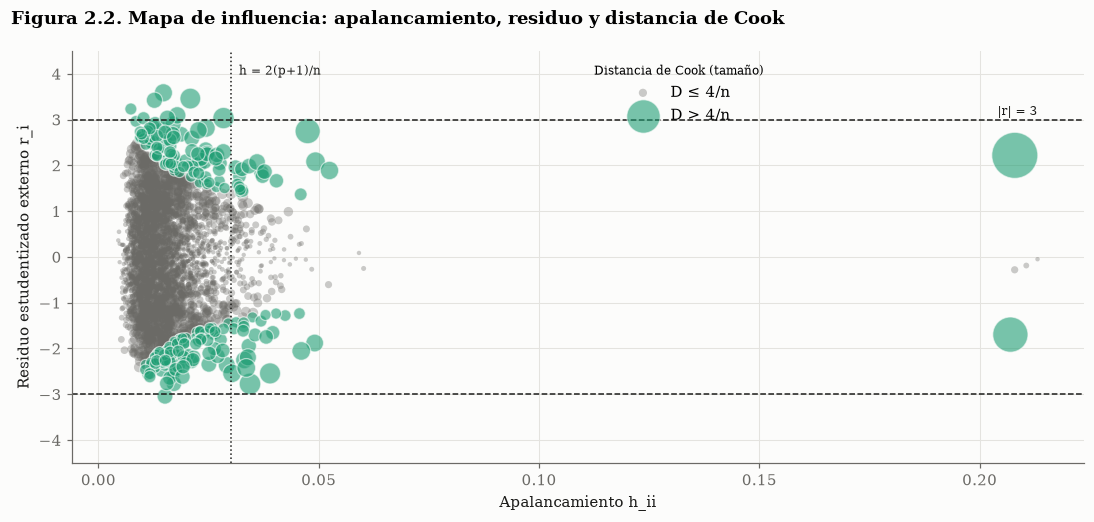

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.8))
size = 8 + 900 * infl["cook"] / infl["cook"].max()
flagged = (infl["cook"] > thr["cook_4n"])
ax.scatter(infl.loc[~flagged, "leverage"], infl.loc[~flagged, "r_ext"], s=size[~flagged],
           color=viz.MUTED, alpha=0.35, edgecolor="none", label="D ≤ 4/n")
ax.scatter(infl.loc[flagged, "leverage"], infl.loc[flagged, "r_ext"], s=size[flagged],
           color=viz.THIRD, alpha=0.6, edgecolor=viz.SURFACE, linewidth=0.8, label="D > 4/n")
for yline in (-3, 3):
    ax.axhline(yline, color=viz.INK, lw=1, ls="--")
ax.axvline(thr["leverage"], color=viz.INK, lw=1, ls=":")
ax.text(thr["leverage"], 4.2, "  h = 2(p+1)/n", fontsize=8, color=viz.INK, va="top")
ax.text(ax.get_xlim()[1] if False else infl["leverage"].max(), 3.1, "|r| = 3", fontsize=8, ha="right", color=viz.INK)
ax.set_xlabel("Apalancamiento h_ii")
ax.set_ylabel("Residuo estudentizado externo r_i")
ax.set_ylim(-4.5, 4.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.6, 1.0), title="Distancia de Cook (tamaño)", title_fontsize=8)
viz.figure_title(fig, "2.2", "Mapa de influencia: apalancamiento, residuo y distancia de Cook")
fig.tight_layout()
save(fig, "fig_2_2_influencia")
plt.show()

In [27]:
extreme = infl[infl["r_ext"].abs() > thr["r"]].join(tr[["los", "dth30", "aps1", "dx"]])
extreme.sort_values("r_ext").round(3)

,r_ext,leverage,cook,ajustado,los,dth30,aps1,dx
1679,-3.044,0.015,0.002,3.281,2.000,1,69,Falla multiorgánica + sepsis
1620,3.029,0.010,0.001,2.449,153.000,0,58,EPOC
1107,3.031,0.016,0.002,3.058,280.000,0,47,Falla multiorgánica + sepsis
2988,3.033,0.028,0.004,2.557,167.000,0,63,Falla multiorgánica + sepsis
3969,3.093,0.018,0.003,2.405,153.000,0,53,Insuf. respiratoria aguda
2726,3.231,0.007,0.001,3.077,342.000,0,50,Falla multiorgánica + sepsis
3554,3.422,0.013,0.002,2.911,338.000,0,50,Falla multiorgánica + sepsis
4012,3.459,0.021,0.004,2.362,199.000,0,65,Coma
4378,3.585,0.015,0.003,1.996,155.000,0,65,Insuf. respiratoria aguda


**Interpretación.** Los nueve atípicos de respuesta ($|r_i| > 3$) son, salvo uno, internaciones excepcionalmente largas (de 150 a 342 días) de pacientes que sobrevivieron, en su mayoría con sepsis o insuficiencia respiratoria. Son trayectorias clínicas plausibles (estadías prolongadas por complicaciones) y no errores de medición: el registro de alta es coherente con el de admisión y con las fechas de contacto. Por eso **no se eliminan**.

El 5 % de las observaciones supera el umbral $D_i > 4/n$, una proporción esperable con $n$ grande, ya que el umbral se vuelve muy exigente ($4/n \approx 0{,}0009$). Lo determinante es que **ninguna observación se acerca a $D_i > 0{,}5$**: la distancia de Cook máxima es 0,019. Ningún paciente individual altera de manera sustantiva el vector de coeficientes.

Los cinco puntos aislados con apalancamiento cercano a 0,21 (Figura 2.2, derecha) son los únicos pacientes de train admitidos por causa ortopédica. Su apalancamiento refleja la rareza de esa categoría en el espacio de covariables, no un error de registro, y su influencia sobre los coeficientes sigue siendo baja.

Para verificar que las conclusiones no dependen de las colas, se reestima el modelo con el **M-estimador de Huber**, que pondera a la baja las observaciones con residuos grandes en lugar de eliminarlas.

In [28]:
huber = reg.fit_huber(X_tr, y_tr)
w = huber.weights
print(f"Observaciones ponderadas a la baja (peso < 1): {(w < 1).mean():.1%} · con peso < 0,5: {(w < 0.5).sum()}")

key = ["rhc", "dnr1", "aps1", "scoma1", "dx_Coma", "dx_Falla multiorgánica + sepsis",
       "dx_Insuf. cardíaca", "dx_EPOC", "ca_Metastatic", "has_cat2", "age", "transhx"]
comp = pd.DataFrame({
    "MCO (HC3)": 100 * (np.exp(coefs.loc[key, "beta"]) - 1),
    "IC_inf": coefs.loc[key, "efecto_%_inf"],
    "IC_sup": coefs.loc[key, "efecto_%_sup"],
    "Huber": 100 * (np.exp(huber.params[key]) - 1),
})
comp["dentro_del_IC"] = comp["Huber"].between(comp["IC_inf"], comp["IC_sup"])
comp.round(2)

Observaciones ponderadas a la baja (peso < 1): 19.2% · con peso < 0,5: 38


,MCO (HC3),IC_inf,IC_sup,Huber,dentro_del_IC
rhc,14.320,7.710,21.330,15.490,True
dnr1,-42.300,-46.990,-37.180,-43.430,True
aps1,-0.420,-0.680,-0.160,-0.340,True
scoma1,0.020,-0.110,0.150,0.030,True
dx_Coma,-30.350,-39.890,-19.290,-32.440,True
dx_Falla multiorgánica + sepsis,11.200,1.760,21.520,11.430,True
dx_Insuf. cardíaca,-33.190,-41.340,-23.920,-33.170,True
dx_EPOC,-8.140,-19.070,4.270,-8.010,True
ca_Metastatic,-12.250,-22.440,-0.720,-13.950,True
has_cat2,0.710,-7.020,9.090,0.570,True


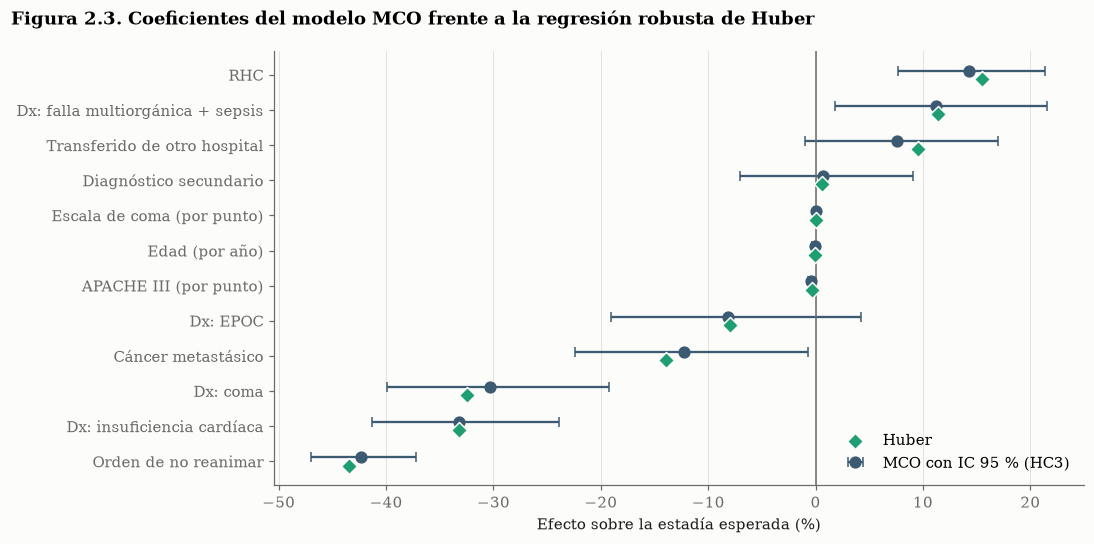

In [29]:
nice = {"rhc": "RHC", "dnr1": "Orden de no reanimar", "aps1": "APACHE III (por punto)",
        "scoma1": "Escala de coma (por punto)", "dx_Coma": "Dx: coma",
        "dx_Falla multiorgánica + sepsis": "Dx: falla multiorgánica + sepsis",
        "dx_Insuf. cardíaca": "Dx: insuficiencia cardíaca", "dx_EPOC": "Dx: EPOC",
        "ca_Metastatic": "Cáncer metastásico", "has_cat2": "Diagnóstico secundario",
        "age": "Edad (por año)", "transhx": "Transferido de otro hospital"}
c = comp.sort_values("MCO (HC3)")
yy = np.arange(len(c))
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(c["MCO (HC3)"], yy + 0.12, xerr=[c["MCO (HC3)"] - c["IC_inf"], c["IC_sup"] - c["MCO (HC3)"]],
            fmt="o", ms=7, color="#3d5a73", capsize=3, lw=1.5, label="MCO con IC 95 % (HC3)")
ax.scatter(c["Huber"], yy - 0.12, s=55, marker="D", color=viz.THIRD, edgecolor=viz.SURFACE,
           linewidth=1, zorder=3, label="Huber")
ax.axvline(0, color=viz.MUTED, lw=1)
ax.set_yticks(yy, [nice[k] for k in c.index])
ax.set_xlabel("Efecto sobre la estadía esperada (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.figure_title(fig, "2.3", "Coeficientes del modelo MCO frente a la regresión robusta de Huber")
fig.tight_layout()
save(fig, "fig_2_3_mco_vs_huber")
plt.show()

**Interpretación.** Huber pondera a la baja alrededor del 19 % de las observaciones, pero solo unas pocas decenas reciben un peso menor a 0,5. Las estimaciones robustas caen dentro del intervalo de confianza del MCO para los doce coeficientes clave (Figura 2.3), sin cambios de signo ni de significancia. Las conclusiones del modelo lineal **no dependen de las observaciones extremas**, y se mantiene el MCO con errores HC3 como especificación principal por su interpretabilidad.

## 2.6 Diagnóstico de multicolinealidad

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el coeficiente de determinación de la regresión de $X_j$ sobre el resto de los regresores. Un VIF mayor a 5 indica colinealidad moderada y uno mayor a 10, severa: la varianza de $\hat\beta_j$ se multiplica por ese factor respecto del caso de regresores ortogonales.

Se calcula primero sobre el diseño inicial, que incluye el antecedente de malignidad `malighx`, y luego sobre el diseño final.

In [30]:
# Diseño inicial: idéntico al final, pero con `malighx` incluida.
pre_initial = build_preprocessor(binary=cfg.BINARY_FEATURES + ["dnr1", "has_cat2"])
vif_initial = reg.vif(pre_initial.fit_transform(tr))
vif_final = reg.vif(X_tr)
vif_cmp = pd.DataFrame({"VIF inicial": vif_initial, "VIF final": vif_final}).sort_values("VIF inicial", ascending=False)
print(pd.crosstab(tr["ca"], tr["malighx"], margins=True, margins_name="Total"))
vif_cmp.head(10).round(2)

malighx        0     1  Total
ca                           
No          3502     0   3502
Yes           34   730    764
Metastatic     0   321    321
Total       3536  1051   4587


,VIF inicial,VIF final
malighx,26.410,NaN
ca_Yes,21.330,1.530
ca_Metastatic,12.210,1.710
surv2md1,5.220,5.220
aps1,4.190,4.190
age,2.500,2.500
liverhx,2.280,2.280
scoma1,2.270,2.270
crea1,2.170,2.170
ninsclas_Medicare,2.170,2.170


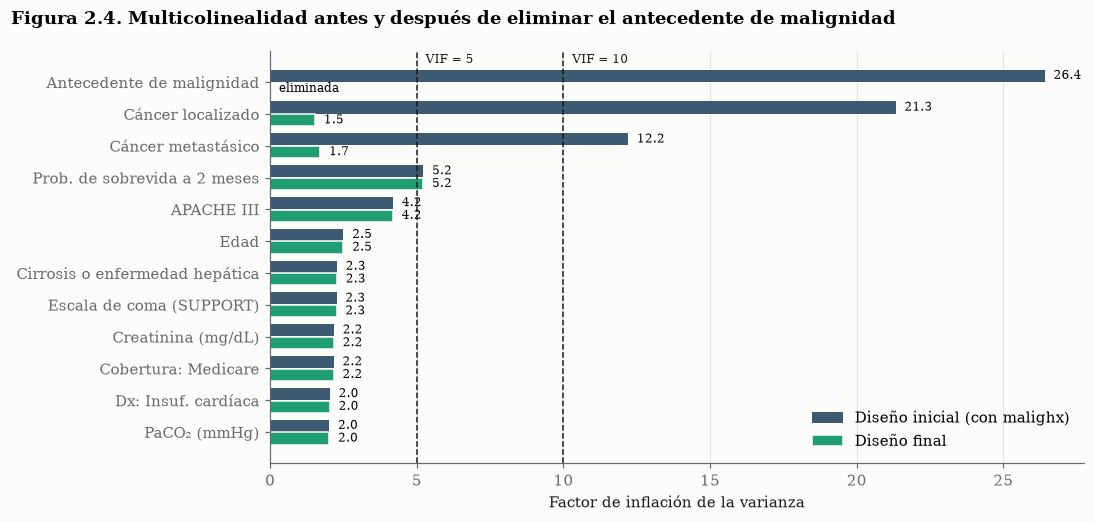

In [31]:
show = vif_cmp.head(12).iloc[::-1]
labels = {"ca_Yes": "Cáncer localizado", "ca_Metastatic": "Cáncer metastásico",
          "surv2md1": "Prob. de sobrevida a 2 meses", "aps1": "APACHE III", "age": "Edad"}
yy = np.arange(len(show))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(yy + 0.2, show["VIF inicial"], height=0.38, color="#3d5a73", label="Diseño inicial (con malighx)")
ax.barh(yy - 0.2, show["VIF final"].fillna(0), height=0.38, color=viz.THIRD, label="Diseño final",
        edgecolor=viz.SURFACE, linewidth=1)
for xline, lab in [(5, "VIF = 5"), (10, "VIF = 10")]:
    ax.axvline(xline, color=viz.INK, lw=1, ls="--")
    ax.text(xline + 0.3, len(show) - 0.4, lab, fontsize=8, color=viz.INK)
for yi, (vi, vf) in enumerate(zip(show["VIF inicial"], show["VIF final"])):
    ax.text(vi + 0.3, yi + 0.2, f"{vi:.1f}", va="center", fontsize=8)
    ax.text((0 if pd.isna(vf) else vf) + 0.3, yi - 0.2, "eliminada" if pd.isna(vf) else f"{vf:.1f}", va="center", fontsize=8)
ax.set_yticks(yy, [labels.get(i, cfg.pretty(i)) for i in show.index])
ax.set_xlabel("Factor de inflación de la varianza")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.figure_title(fig, "2.4", "Multicolinealidad antes y después de eliminar el antecedente de malignidad")
fig.tight_layout()
save(fig, "fig_2_4_vif")
plt.show()

In [32]:
# Sensibilidad: ¿cambia el coeficiente de APACHE si se excluye la probabilidad de sobrevida (VIF > 5)?
ols_sin_surv = reg.fit_ols(X_tr.drop(columns="surv2md1"), y_tr)
for name, m in [("con surv2md1", ols), ("sin surv2md1", ols_sin_surv)]:
    r = m.get_robustcov_results("HC3")
    i = list(m.params.index).index("aps1")
    print(f"APACHE III {name}: β = {m.params['aps1']:.5f} · ee HC3 = {r.bse[i]:.5f} · R² aj. = {m.rsquared_adj:.4f}")

APACHE III con surv2md1: β = -0.00420 · ee HC3 = 0.00133 · R² aj. = 0.1326
APACHE III sin surv2md1: β = -0.00391 · ee HC3 = 0.00127 · R² aj. = 0.1327


**Interpretación y estrategia de resolución.**

- **Colinealidad severa, resuelta por eliminación.** En el diseño inicial, las dummies de cáncer y el antecedente de malignidad superan ampliamente el umbral de 10. La tabla cruzada explica por qué: `malighx` vale 1 exactamente para los pacientes con cáncer localizado o metastásico, salvo 34 casos en train. Ambas variables codifican la misma información. Se elimina `malighx` y se conserva `ca`, que además distingue el cáncer metastásico. Tras la eliminación, el VIF de las dummies de cáncer cae por debajo de 2 y ningún regresor supera 10.
- **Colinealidad moderada, retenida con justificación.** La probabilidad de sobrevida a 2 meses conserva un VIF levemente superior a 5 y el APACHE III, cercano a 4. Es colinealidad **estructural**: la probabilidad de sobrevida es la salida del modelo pronóstico SUPPORT, que combina el APACHE, la edad y el diagnóstico. Se mantiene en el modelo porque la sensibilidad muestra que excluirla apenas modifica el coeficiente y el error estándar del APACHE, y no mejora el ajuste. En la Fase 3, la regularización Ridge ofrece la solución estándar para este tipo de colinealidad en un contexto predictivo.

## 2.7 Reducción de dimensionalidad con PCA sin fuga de datos

**Regla aplicada.** Se trabaja sobre las 21 variables numéricas basales. El pipeline imputa, estandariza y calcula la descomposición en valores singulares **solo con los pacientes de train**. Luego, la matriz de rotación aprendida se aplica a ciegas sobre test, sin reestimar medias, desvíos ni autovectores.

Si la estandarización o el PCA se ajustaran sobre el dataset completo, las medias y la estructura de covarianza incorporarían información de los pacientes de test, y cualquier modelo posterior sería evaluado con datos que de algún modo ya vio.

In [33]:
pca_pipe = build_pca()
pca_pipe.fit(train[cfg.NUMERIC_FEATURES])
pca = pca_pipe.named_steps["pca"]
eig = pca.explained_variance_
n_kaiser = int((eig > 1).sum())

# Aplicación ciega sobre test: imputación, escalado y rotación aprendidos en train.
Z_te = pca_pipe[:-1].transform(test[cfg.NUMERIC_FEATURES])
scores_te = pca.transform(Z_te)
var_test = scores_te.var(axis=0, ddof=1) / Z_te.var(axis=0, ddof=1).sum()

eig_tab = pd.DataFrame({
    "autovalor (train)": eig,
    "varianza explicada train": pca.explained_variance_ratio_,
    "acumulada train": pca.explained_variance_ratio_.cumsum(),
    "varianza explicada test": var_test,
    "acumulada test": var_test.cumsum(),
}, index=[f"CP{i + 1}" for i in range(len(eig))])
print(f"Componentes con autovalor > 1 (criterio de Kaiser): {n_kaiser}")
eig_tab.head(10).round(3)

Componentes con autovalor > 1 (criterio de Kaiser): 8


,autovalor (train),varianza explicada train,acumulada train,varianza explicada test,acumulada test
CP1,2.590,0.123,0.123,0.125,0.125
CP2,1.861,0.089,0.212,0.092,0.217
CP3,1.756,0.084,0.296,0.082,0.299
CP4,1.526,0.073,0.368,0.075,0.375
CP5,1.265,0.060,0.428,0.062,0.436
CP6,1.116,0.053,0.481,0.051,0.488
CP7,1.084,0.052,0.533,0.049,0.537
CP8,1.029,0.049,0.582,0.047,0.584
CP9,0.986,0.047,0.629,0.044,0.628
CP10,0.923,0.044,0.673,0.044,0.672


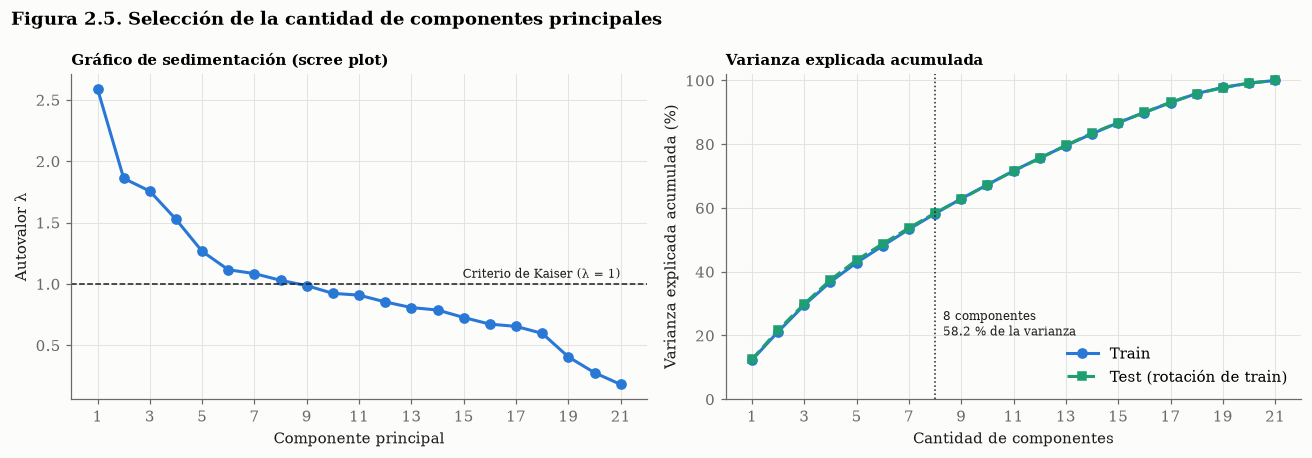

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
k = np.arange(1, len(eig) + 1)
axes[0].plot(k, eig, marker="o", ms=6, color=viz.NO_RHC)
axes[0].axhline(1, color=viz.INK, lw=1, ls="--")
axes[0].text(len(eig), 1.05, "Criterio de Kaiser (λ = 1)", ha="right", fontsize=8, color=viz.INK)
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Autovalor λ")
axes[0].set_title("Gráfico de sedimentación (scree plot)", fontsize=10)
axes[0].set_xticks(k[::2])

axes[1].plot(k, 100 * eig_tab["acumulada train"], marker="o", ms=6, color=viz.NO_RHC, label="Train")
axes[1].plot(k, 100 * eig_tab["acumulada test"], marker="s", ms=5, color=viz.THIRD, ls="--", label="Test (rotación de train)")
axes[1].axvline(n_kaiser, color=viz.INK, lw=1, ls=":")
axes[1].text(n_kaiser + 0.3, 20, f"{n_kaiser} componentes\n{100 * eig_tab['acumulada train'].iloc[n_kaiser - 1]:.1f} % de la varianza",
             fontsize=8, color=viz.INK)
axes[1].set_xlabel("Cantidad de componentes")
axes[1].set_ylabel("Varianza explicada acumulada (%)")
axes[1].set_title("Varianza explicada acumulada", fontsize=10)
axes[1].set_xticks(k[::2])
axes[1].set_ylim(0, 102)
axes[1].legend(loc="lower right")
viz.figure_title(fig, "2.5", "Selección de la cantidad de componentes principales")
fig.tight_layout()
save(fig, "fig_2_5_scree")
plt.show()

**Cantidad de componentes.** El criterio de Kaiser retiene las componentes con autovalor mayor a 1, es decir, las que resumen más varianza que una variable original estandarizada. Se retienen 8 componentes, que explican el 58 % de la varianza total. El gráfico de sedimentación no presenta un codo marcado: después de la primera componente, los autovalores descienden de forma gradual. Esto indica que la información fisiológica está **distribuida** entre muchas dimensiones relativamente independientes y no concentrada en unos pocos factores latentes.

La curva de test, calculada con la rotación de train aplicada a ciegas, prácticamente coincide con la de train: **la estructura de componentes generaliza** a pacientes que no participaron de su estimación.

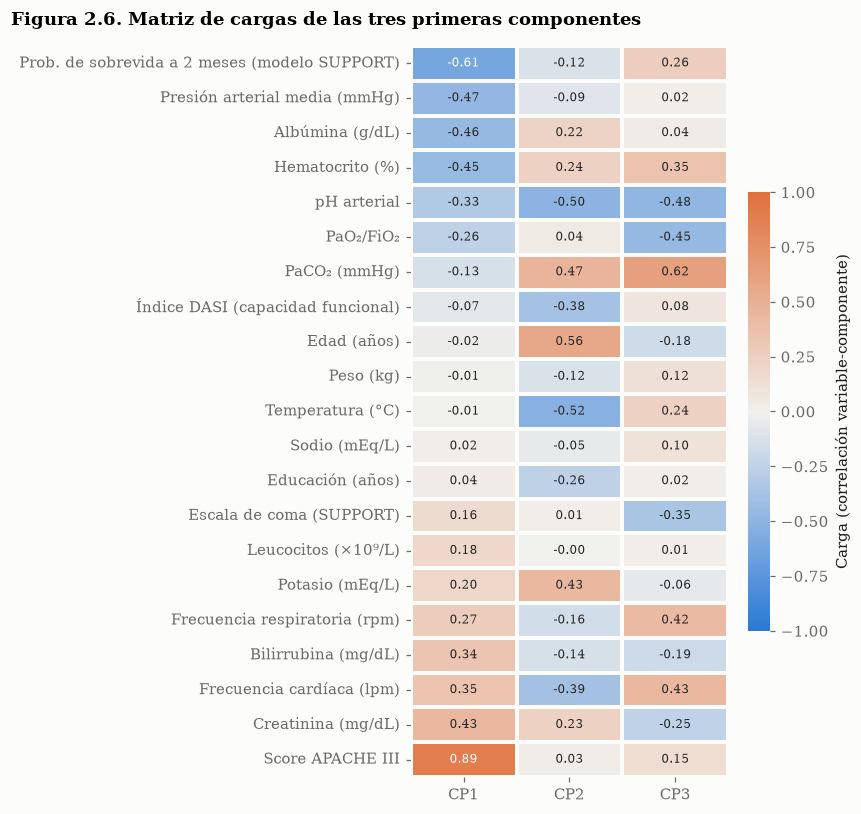

In [35]:
loadings = pd.DataFrame(pca.components_[:3].T * np.sqrt(eig[:3]), index=cfg.NUMERIC_FEATURES,
                        columns=["CP1", "CP2", "CP3"])
loadings = loadings.reindex(loadings["CP1"].sort_values().index)
fig, ax = plt.subplots(figsize=(7.5, 7.5))
sns.heatmap(loadings.rename(index=lambda c: cfg.LABELS.get(c, c)), cmap=viz.DIVERGING, vmin=-1, vmax=1,
            center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=1.5, linecolor=viz.SURFACE,
            cbar_kws={"shrink": 0.6, "label": "Carga (correlación variable-componente)"}, ax=ax)
ax.grid(False)
viz.figure_title(fig, "2.6", "Matriz de cargas de las tres primeras componentes")
fig.tight_layout()
save(fig, "fig_2_6_cargas")
plt.show()

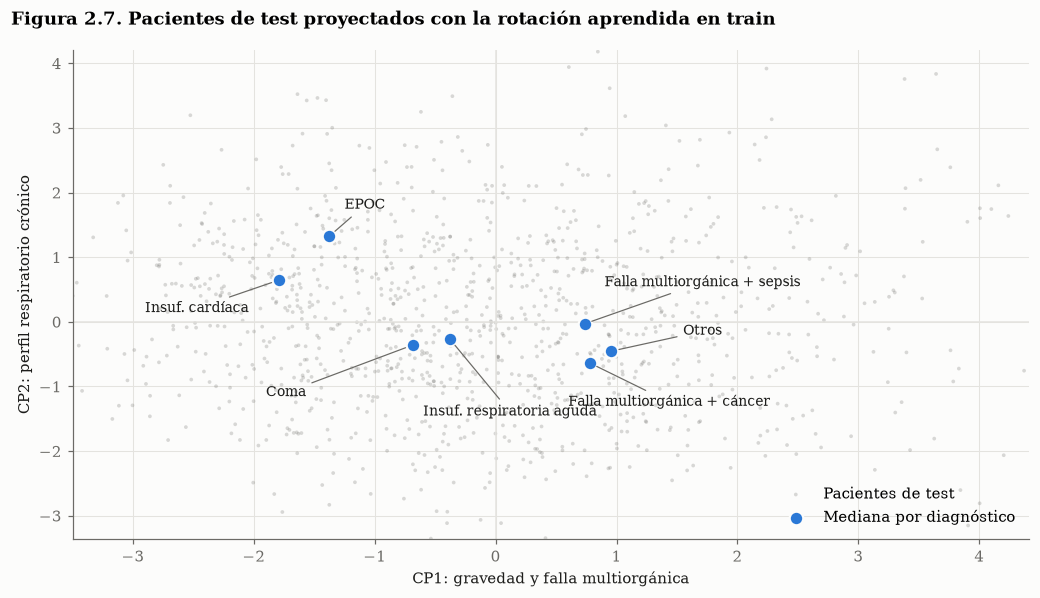

,CP1,CP2
dx,,
Insuf. respiratoria aguda,-0.380,-0.270
Falla multiorgánica + sepsis,0.740,-0.030
Falla multiorgánica + cáncer,0.780,-0.640
Insuf. cardíaca,-1.790,0.640
EPOC,-1.380,1.320
Coma,-0.690,-0.360
Otros,0.960,-0.450


In [36]:
pc = pd.DataFrame(scores_te[:, :2], columns=["CP1", "CP2"], index=test.index).join(test[["dx", "dth30"]])
cent = pc.groupby("dx", observed=True)[["CP1", "CP2"]].median()
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.scatter(pc["CP1"], pc["CP2"], s=6, color=viz.MUTED, alpha=0.25, edgecolor="none", label="Pacientes de test")
ax.scatter(cent["CP1"], cent["CP2"], s=80, color=viz.NO_RHC, edgecolor=viz.SURFACE, linewidth=1.5, zorder=3,
           label="Mediana por diagnóstico")
# Posición de cada etiqueta (en unidades de los ejes) y línea guía hasta su punto.
label_pos = {"EPOC": (-1.25, 1.75), "Insuf. cardíaca": (-2.9, 0.15), "Coma": (-1.9, -1.15),
             "Insuf. respiratoria aguda": (-0.6, -1.45), "Falla multiorgánica + sepsis": (0.9, 0.55),
             "Otros": (1.55, -0.2), "Falla multiorgánica + cáncer": (0.6, -1.3)}
for name, row in cent.iterrows():
    ax.annotate(name, xy=(row["CP1"], row["CP2"]), xytext=label_pos[name], fontsize=9, color=viz.INK,
                arrowprops=dict(arrowstyle="-", color=viz.MUTED, lw=0.8, shrinkA=2, shrinkB=5))
ax.axhline(0, color=viz.GRID, lw=1)
ax.axvline(0, color=viz.GRID, lw=1)
ax.set_xlim(pc["CP1"].quantile(0.005), pc["CP1"].quantile(0.995))
ax.set_ylim(pc["CP2"].quantile(0.005), pc["CP2"].quantile(0.995))
ax.set_xlabel("CP1: gravedad y falla multiorgánica")
ax.set_ylabel("CP2: perfil respiratorio crónico")
ax.legend(loc="lower right")
viz.figure_title(fig, "2.7", "Pacientes de test proyectados con la rotación aprendida en train")
fig.tight_layout()
save(fig, "fig_2_7_plano_factorial")
plt.show()
cent.round(2)

**Interpretación de negocio de las dos primeras componentes.**

- **CP1, eje de gravedad y falla multiorgánica.** Carga positivamente en el APACHE III (0,89), la creatinina, la bilirrubina y la frecuencia cardíaca, y negativamente en la probabilidad de sobrevida, la presión arterial media, la albúmina y el hematocrito. Ordena a los pacientes desde estables hasta críticos con compromiso de varios órganos (riñón, hígado, circulación). Es, en la práctica, un **índice de gravedad** construido a partir de la fisiología: en la Figura 2.7, la falla multiorgánica con sepsis se ubica en el extremo derecho y la insuficiencia cardíaca y la EPOC, a la izquierda.
- **CP2, perfil respiratorio crónico frente a cuadro inflamatorio agudo.** Carga positivamente en la edad, la PaCO₂ y el potasio, y negativamente en la temperatura, el pH, la frecuencia cardíaca y el índice de capacidad funcional. Un valor alto describe al paciente mayor, con retención de dióxido de carbono, acidosis y sin fiebre: el perfil típico de la EPOC descompensada, que efectivamente aparece en el extremo superior. Un valor bajo combina fiebre, taquicardia y un pH más alto, en pacientes en promedio más jóvenes. La falla multiorgánica asociada al cáncer es el grupo con menor CP2, mientras que la sepsis queda en una posición intermedia.

Para la dirección médica, el plano CP1-CP2 resume en dos ejes interpretables la heterogeneidad de una unidad de terapia intensiva: **cuán grave** está el paciente y **de qué tipo** es su descompensación. Estas dimensiones anticipan la pregunta de heterogeneidad de la Fase 4: el efecto del RHC podría diferir entre pacientes con distinto perfil fisiológico.

## 2.8 Síntesis de la Fase 2

| Diagnóstico | Resultado | Decisión |
|---|---|---|
| Ajuste global | $R^2 = 0{,}145$; $F$ significativo; $R^2$ de test = 0,099 | Modelo útil para describir asociaciones, insuficiente para predecir estadías individuales |
| Homocedasticidad | Breusch-Pagan rechaza | Inferencia con errores robustos HC3 |
| Normalidad | Jarque-Bera rechaza por $n$, pero asimetría 0,13 y curtosis 2,91 | Se apoya en el TCL; la transformación logarítmica fue adecuada |
| Independencia | Durbin-Watson = 1,98 por fecha de admisión | Sin autocorrelación temporal |
| Atípicos e influyentes | 9 atípicos (estadías largas reales); Cook máxima = 0,019 | Se conservan; Huber confirma los coeficientes |
| Multicolinealidad | `malighx` duplicaba `ca` (VIF de 26) | Se elimina `malighx`; colinealidad moderada restante se aborda con Ridge en la Fase 3 |
| PCA | 8 componentes por Kaiser (58 % de la varianza); la estructura generaliza a test | CP1 = gravedad; CP2 = perfil respiratorio crónico |
| Truncamiento por muerte | APACHE y la orden de no reanimar acortan la estadía | La estadía no es un indicador válido de evolución clínica; la Fase 3 modela la mortalidad |

---
# Fase 3. Torneo de modelos predictivos y calibración

Esta fase responde la pregunta predictiva, $P(Y \mid X)$: dado el perfil de un paciente al ingreso, ¿cuál es su probabilidad de morir dentro de los 30 días? Compiten cuatro familias de modelos bajo un mismo esquema de validación y se comparan por su capacidad de **discriminar** (ordenar a los pacientes según su riesgo) y de **calibrar** (que una probabilidad predicha de 40 % corresponda efectivamente a 40 % de muertes).

## 3.1 Esquema de validación

- **Partición:** la misma de la Fase 2: 80 % train y 20 % test, estratificada por mortalidad y tratamiento.
- **Validación cruzada:** `StratifiedKFold` de 5 pliegues sobre train, para elegir hiperparámetros.
- **Sin fuga dentro de la validación cruzada:** cada modelo es un *pipeline* que incluye su preprocesamiento. En cada pliegue, la imputación, el escalado y las dummies se reajustan solo con los cuatro pliegues de entrenamiento.
- **Criterio de selección:** AUC-ROC promedio en validación cruzada. **Ninguna decisión se toma con el conjunto de test:** los hiperparámetros, el modelo final y el umbral de decisión se eligen con información de train. El conjunto de test se reserva para medir el desempeño de los modelos ya decididos y para ilustrar, fuera de muestra, el sobreajuste del árbol sin poda (sección 3.4) y la importancia de las variables (sección 3.7).
- **Predictores:** los 68 regresores de la Fase 2, incluido el tratamiento RHC. Para predecir el riesgo es legítimo usarlo; si su efecto es causal se discute en la Fase 4.

In [37]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict, cross_val_score
from sklearn.tree import plot_tree

from rhc import models as mdl

y_tr, y_te = train[cfg.OUTCOME_BIN], test[cfg.OUTCOME_BIN]
cv = mdl.cv_splitter()
folds = pd.DataFrame([
    {"pliegue": k + 1, "n_validación": len(va), "mortalidad_validación": y_tr.iloc[va].mean()}
    for k, (_, va) in enumerate(cv.split(train, y_tr))
]).set_index("pliegue")
folds.round(4)

,n_validación,mortalidad_validación
pliegue,,
1,918,0.334
2,918,0.334
3,918,0.334
4,917,0.335
5,917,0.334


## 3.2 Familia 1: regresión logística regularizada

$$\log \frac{P(Y = 1 \mid X)}{1 - P(Y = 1 \mid X)} = \beta_0 + \sum_j \beta_j X_j$$

Los coeficientes se estiman minimizando la log-pérdida más una penalización. Con penalización **L2 (Ridge)**, $\lambda \sum_j \beta_j^2$, todos los coeficientes se contraen hacia cero, lo que estabiliza las estimaciones ante la colinealidad moderada detectada en la Fase 2. Con penalización **L1 (Lasso)**, $\lambda \sum_j |\beta_j|$, algunos coeficientes se anulan exactamente, lo que equivale a seleccionar variables. En scikit-learn la intensidad se controla con $C = 1/\lambda$, y las variables numéricas se estandarizan para que la penalización trate a todas en la misma escala.

In [38]:
grid_C = {"modelo__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]}
logit_l2 = GridSearchCV(mdl.build_logit(penalty="l2"), grid_C, cv=cv, scoring="roc_auc").fit(train, y_tr)
logit_l1 = GridSearchCV(mdl.build_logit(penalty="l1"), grid_C, cv=cv, scoring="roc_auc").fit(train, y_tr)
reg_cmp = pd.DataFrame({
    "C óptimo": [logit_l2.best_params_["modelo__C"], logit_l1.best_params_["modelo__C"]],
    "AUC validación cruzada": [logit_l2.best_score_, logit_l1.best_score_],
    "coeficientes no nulos": [int((logit_l2.best_estimator_[-1].coef_ != 0).sum()),
                              int((logit_l1.best_estimator_[-1].coef_ != 0).sum())],
}, index=["L2 (Ridge)", "L1 (Lasso)"])
reg_cmp.round(4)

,C óptimo,AUC validación cruzada,coeficientes no nulos
L2 (Ridge),0.100,0.760,68
L1 (Lasso),0.300,0.761,56


**Interpretación.** Las dos penalizaciones alcanzan el mismo AUC en validación cruzada (alrededor de 0,76). Lasso anula 12 de los 68 coeficientes sin perder capacidad predictiva, lo que confirma que parte de la información está duplicada entre variables correlacionadas. Se adopta **Ridge** como modelo logístico del torneo porque conserva todos los predictores, reparte el peso entre variables colineales en lugar de elegir una arbitrariamente, y genera coeficientes más estables entre muestras.

### Odds ratios con intervalos de confianza

Para interpretar los coeficientes con su incertidumbre se reestima la logística **sin penalización** por máxima verosimilitud. La penalización sesga los coeficientes hacia cero e invalida los intervalos clásicos. El odds ratio $OR_j = e^{\beta_j}$ indica cuánto se multiplican las chances de muerte ante un aumento de $\Delta$ unidades en $X_j$, con el resto constante: $OR_j^{(\Delta)} = e^{\Delta \beta_j}$.

In [39]:
X_tr_or = build_preprocessor().fit_transform(train).astype(float)
or_tab = mdl.odds_ratio_table(X_tr_or, y_tr)
scaled = {"rhc": 1, "dnr1": 1, "dx_Coma": 1, "dx_Falla multiorgánica + sepsis": 1, "dx_Insuf. cardíaca": 1,
          "ca_Metastatic": 1, "ca_Yes": 1, "immunhx": 1, "aps1": 10, "surv2md1": 0.1, "age": 10, "das2d3pc": 10}
or_show = pd.DataFrame({
    "Δ": pd.Series(scaled),
    "OR": np.exp(or_tab.loc[list(scaled), "beta"] * pd.Series(scaled)),
    "IC_inf": or_tab.loc[list(scaled), "OR_inf"] ** pd.Series(scaled),
    "IC_sup": or_tab.loc[list(scaled), "OR_sup"] ** pd.Series(scaled),
    "p_valor": or_tab.loc[list(scaled), "p_valor"].map(inf.fmt_p),
})
or_show.round(3)

,Δ,OR,IC_inf,IC_sup,p_valor
rhc,1.000,1.331,1.129,1.569,6.47 × 10⁻⁴
dnr1,1.000,2.835,2.276,3.530,< 10⁻¹⁶
dx_Coma,1.000,2.661,1.853,3.821,1.15 × 10⁻⁷
dx_Falla multiorgánica + sepsis,1.000,1.113,0.886,1.398,0.3563
dx_Insuf. cardíaca,1.000,0.822,0.538,1.257,0.3656
ca_Metastatic,1.000,0.845,0.602,1.186,0.3299
ca_Yes,1.000,0.900,0.718,1.128,0.3618
immunhx,1.000,1.101,0.934,1.299,0.2511
aps1,10.000,1.092,1.017,1.171,0.0147
surv2md1,0.100,0.731,0.676,0.790,3.38 × 10⁻¹⁵


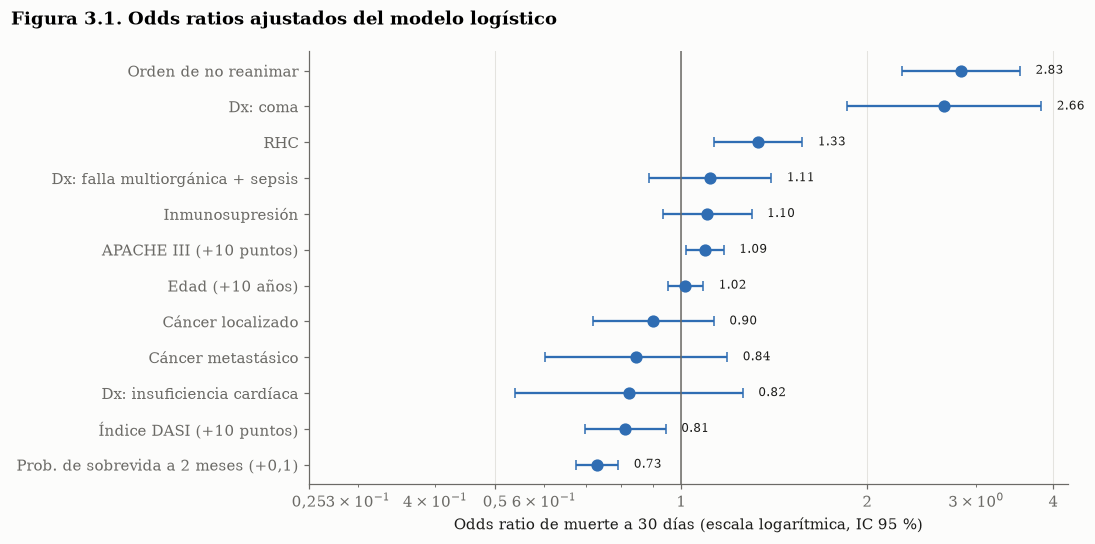

In [40]:
labels_or = {"rhc": "RHC", "dnr1": "Orden de no reanimar", "dx_Coma": "Dx: coma",
             "dx_Falla multiorgánica + sepsis": "Dx: falla multiorgánica + sepsis",
             "dx_Insuf. cardíaca": "Dx: insuficiencia cardíaca", "ca_Metastatic": "Cáncer metastásico",
             "ca_Yes": "Cáncer localizado", "immunhx": "Inmunosupresión", "aps1": "APACHE III (+10 puntos)",
             "surv2md1": "Prob. de sobrevida a 2 meses (+0,1)", "age": "Edad (+10 años)",
             "das2d3pc": "Índice DASI (+10 puntos)"}
o = or_show.sort_values("OR")
yy = np.arange(len(o))
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(o["OR"], yy, xerr=[o["OR"] - o["IC_inf"], o["IC_sup"] - o["OR"]], fmt="o", ms=7,
            color=viz.MODEL_COLORS["Logística"], capsize=3, lw=1.5)
ax.axvline(1, color=viz.MUTED, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0,25", "0,5", "1", "2", "4"])
ax.set_yticks(yy, [labels_or[k] for k in o.index])
ax.set_xlabel("Odds ratio de muerte a 30 días (escala logarítmica, IC 95 %)")
ax.grid(axis="y", visible=False)
for yi, (k, r) in enumerate(o.iterrows()):
    ax.text(r["IC_sup"] * 1.06, yi, f"{r['OR']:.2f}", va="center", fontsize=8, color=viz.INK)
viz.figure_title(fig, "3.1", "Odds ratios ajustados del modelo logístico")
fig.tight_layout()
save(fig, "fig_3_1_odds_ratios")
plt.show()

**Interpretación de los odds ratios** (Figura 3.1, todos ajustados por el resto de las covariables):

- **Orden de no reanimar:** casi triplica las chances de morir a 30 días (OR ≈ 2,8). Es un marcador de pronóstico y de limitación del esfuerzo terapéutico, no una causa.
- **Coma como diagnóstico de ingreso:** OR ≈ 2,7 frente a la insuficiencia respiratoria aguda.
- **Probabilidad de sobrevida estimada por SUPPORT:** cada 0,1 adicional reduce las chances de muerte en alrededor de 27 % (OR ≈ 0,73). Es el predictor más fuerte del modelo, lo que resulta esperable: es un pronóstico construido con la información clínica de ingreso.
- **RHC:** OR ≈ 1,33 (IC 95 %: 1,13 a 1,57). Entre pacientes con covariables observadas iguales, los cateterizados tienen un tercio más de chances de morir a 30 días. El valor es del mismo orden que el OR ajustado de 1,24 publicado por Connors et al. (1996). Sigue siendo una **asociación condicional**: si es efecto causal o sesgo residual se analiza en la Fase 4.

## 3.3 Familia 2: Naive Bayes y el supuesto de independencia condicional

Naive Bayes aplica el teorema de Bayes bajo el supuesto de que, dentro de cada clase, los predictores son independientes:

$$P(X_1, \ldots, X_p \mid Y) = \prod_{i=1}^{p} P(X_i \mid Y) \quad \Longrightarrow \quad P(Y \mid X) \propto P(Y) \prod_{i=1}^{p} P(X_i \mid Y)$$

**Implementación.** Como el dataset combina variables continuas y binarias, se implementó un clasificador mixto (`MixedNaiveBayes` en `src/rhc/models.py`): `GaussianNB` modela las 21 variables continuas y `BernoulliNB`, las 47 binarias (comorbilidades, diagnósticos, dummies e indicadores). Bajo el mismo supuesto de independencia, ambas log-verosimilitudes se suman y el prior de clase se cuenta una sola vez. Forzar una única distribución para todas las variables habría tratado las binarias como gaussianas o habría discretizado las continuas.

In [41]:
nb_model = mdl.build_naive_bayes()
nb_cv = cross_val_score(nb_model, train, y_tr, cv=cv, scoring="roc_auc")
print(f"Naive Bayes mixto: AUC en validación cruzada = {nb_cv.mean():.4f} (desvío entre pliegues = {nb_cv.std():.4f})")

num = cfg.NUMERIC_FEATURES
corr_y1 = train.loc[y_tr == 1, num].corr()
upper = corr_y1.where(np.triu(np.ones(corr_y1.shape, dtype=bool), k=1)).stack()
print(f"Correlación absoluta media entre pares de variables continuas, dentro de Y = 1: {upper.abs().mean():.3f}")
print("Pares más correlacionados dentro de la clase Y = 1 (bajo Naive Bayes deberían ser 0):")
print(upper.reindex(upper.abs().sort_values(ascending=False).index).head(6)
      .rename(index=lambda c: cfg.pretty(c)).round(2).to_string())

Naive Bayes mixto: AUC en validación cruzada = 0.7492 (desvío entre pliegues = 0.0146)
Correlación absoluta media entre pares de variables continuas, dentro de Y = 1: 0.088
Pares más correlacionados dentro de la clase Y = 1 (bajo Naive Bayes deberían ser 0):
PaCO₂ (mmHg)              pH arterial                                     -0.480
Escala de coma (SUPPORT)  Prob. de sobrevida a 2 meses (modelo SUPPORT)   -0.460
Score APACHE III          Prob. de sobrevida a 2 meses (modelo SUPPORT)   -0.410
                          Presión arterial media (mmHg)                   -0.410
                          Frecuencia cardíaca (lpm)                        0.390
                          pH arterial                                     -0.390


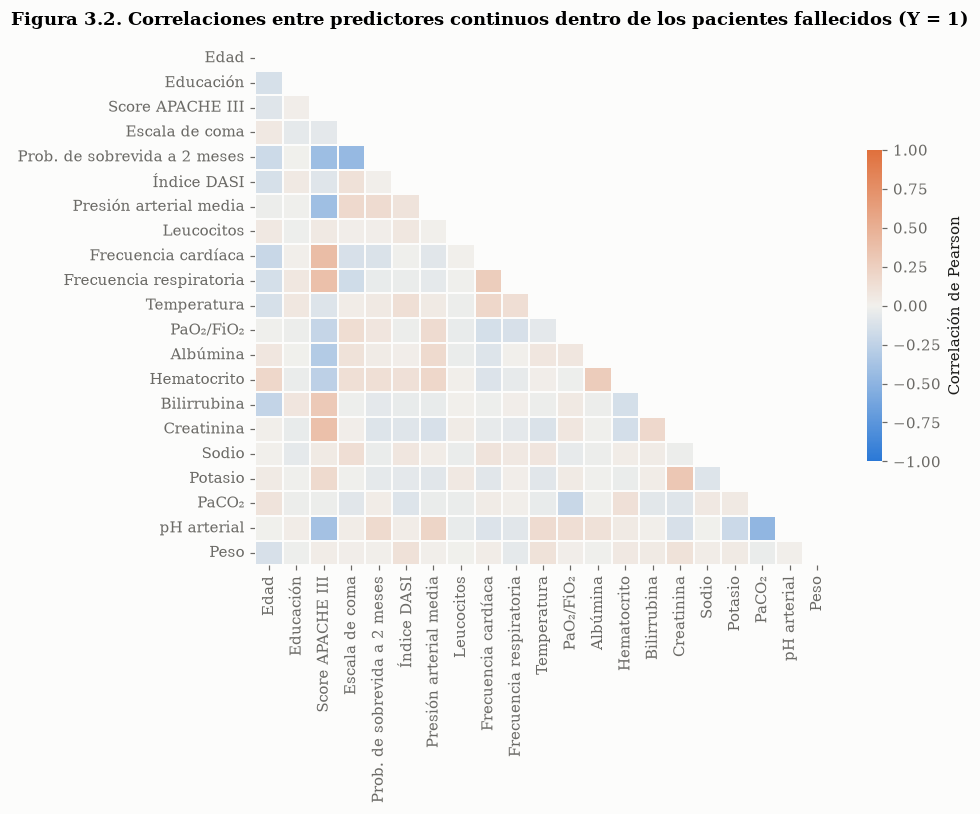

In [42]:
short_c = {c: cfg.pretty(c).split(" (")[0] for c in num}
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr_y1, dtype=bool), k=0)
sns.heatmap(corr_y1.rename(index=short_c, columns=short_c), mask=mask, cmap=viz.DIVERGING, vmin=-1, vmax=1,
            center=0, linewidths=1, linecolor=viz.SURFACE, cbar_kws={"shrink": 0.6, "label": "Correlación de Pearson"},
            ax=ax)
ax.grid(False)
viz.figure_title(fig, "3.2", "Correlaciones entre predictores continuos dentro de los pacientes fallecidos (Y = 1)")
fig.tight_layout()
save(fig, "fig_3_2_independencia_nb")
plt.show()

**Violación del supuesto.** Si la independencia condicional se cumpliera, la matriz de la Figura 3.2 sería blanca fuera de la diagonal. En cambio, dentro de los pacientes fallecidos persisten correlaciones de hasta 0,48 en valor absoluto: entre PaCO₂ y pH (ambos reflejan el equilibrio ácido-base), entre la escala de coma y la probabilidad de sobrevida, y entre el APACHE y la probabilidad de sobrevida, la presión arterial o la frecuencia cardíaca. Varias de estas variables son, por construcción, funciones de otras: el APACHE resume la fisiología, y la probabilidad de sobrevida resume al APACHE y al coma.

La consecuencia es que Naive Bayes **cuenta varias veces la misma evidencia**. Si el APACHE, la presión y la probabilidad de sobrevida señalan gravedad, el producto de verosimilitudes multiplica tres veces una sola señal, y la probabilidad final se empuja hacia 0 o hacia 1. La discriminación puede sobrevivir, porque el orden de los pacientes se mantiene aproximadamente, pero la **calibración** se degrada. Esto se cuantifica en la sección 3.6.

## 3.4 Familia 3: árbol de decisión CART y poda por costo-complejidad

### Árbol sin restricciones: ilustración del sobreajuste

In [43]:
tree_full = mdl.build_tree(ccp_alpha=0.0).fit(train, y_tr)
overfit = pd.DataFrame({
    "exactitud": [accuracy_score(y_tr, tree_full.predict(train)), accuracy_score(y_te, tree_full.predict(test))],
    "AUC-ROC": [roc_auc_score(y_tr, tree_full.predict_proba(train)[:, 1]),
                roc_auc_score(y_te, tree_full.predict_proba(test)[:, 1])],
}, index=["Train", "Test"])
print(f"Hojas: {tree_full[-1].get_n_leaves()} · Profundidad: {tree_full[-1].get_depth()}")
overfit.round(4)

Hojas: 707 · Profundidad: 25


,exactitud,AUC-ROC
Train,1.000,1.000
Test,0.636,0.585


El árbol crecido sin restricciones **memoriza el conjunto de entrenamiento**: clasifica correctamente al 100 % de los pacientes de train con cientos de hojas, muchas de ellas con un único paciente. En test, su exactitud cae a alrededor de 64 % y su AUC a 0,59, apenas por encima del azar (0,5). Es el caso típico de varianza máxima: cada hoja refleja ruido de la muestra y no un patrón generalizable.

### Poda por costo-complejidad

La poda minimiza el costo penalizado

$$R_\alpha(T) = R(T) + \alpha \, |T|$$

donde $R(T)$ es el error de clasificación del árbol, $|T|$ su cantidad de hojas y $\alpha$ el precio de cada hoja adicional. `cost_complexity_pruning_path` devuelve la secuencia de valores de $\alpha$ en los que el árbol óptimo cambia, y $\alpha_{opt}$ se elige por validación cruzada de 5 pliegues.

In [44]:
pre_tree = build_preprocessor().fit(train)
path = tree_full[-1].cost_complexity_pruning_path(pre_tree.transform(train), y_tr)
alphas = path.ccp_alphas[path.ccp_alphas > 0]
alpha_grid = np.unique(np.quantile(alphas, np.linspace(0, 0.995, 40)))
tree_cv = GridSearchCV(mdl.build_tree(), {"modelo__ccp_alpha": alpha_grid}, cv=cv, scoring="roc_auc",
                       return_train_score=True).fit(train, y_tr)
alpha_opt = tree_cv.best_params_["modelo__ccp_alpha"]
tree_pruned = tree_cv.best_estimator_
print(f"Valores de α en el camino de poda: {len(path.ccp_alphas)}")
print(f"α óptimo = {alpha_opt:.5f} · AUC en validación cruzada = {tree_cv.best_score_:.4f}")
print(f"Árbol podado: {tree_pruned[-1].get_n_leaves()} hojas · profundidad {tree_pruned[-1].get_depth()}")

Valores de α en el camino de poda: 373
α óptimo = 0.00132 · AUC en validación cruzada = 0.7354
Árbol podado: 16 hojas · profundidad 7


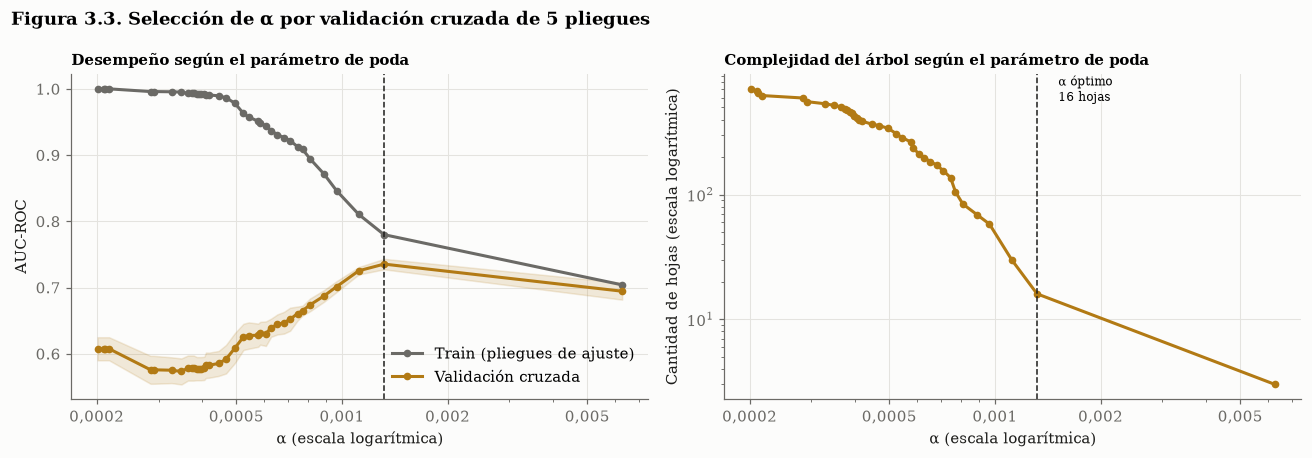

In [45]:
res_cv = pd.DataFrame(tree_cv.cv_results_)
leaves = [mdl.build_tree(a).fit(train, y_tr)[-1].get_n_leaves() for a in alpha_grid]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(alpha_grid, res_cv["mean_train_score"], marker="o", ms=4, color=viz.MUTED, label="Train (pliegues de ajuste)")
axes[0].plot(alpha_grid, res_cv["mean_test_score"], marker="o", ms=4, color=viz.MODEL_COLORS["Árbol podado"],
             label="Validación cruzada")
axes[0].fill_between(alpha_grid, res_cv["mean_test_score"] - res_cv["std_test_score"],
                     res_cv["mean_test_score"] + res_cv["std_test_score"], color=viz.MODEL_COLORS["Árbol podado"], alpha=0.15)
axes[0].axvline(alpha_opt, color=viz.INK, lw=1, ls="--")
axes[0].set_xscale("log")
axes[0].set_xlabel("α (escala logarítmica)")
axes[0].set_ylabel("AUC-ROC")
axes[0].set_title("Desempeño según el parámetro de poda", fontsize=10)
axes[0].legend(loc="lower right")
axes[1].plot(alpha_grid, leaves, marker="o", ms=4, color=viz.MODEL_COLORS["Árbol podado"])
axes[1].axvline(alpha_opt, color=viz.INK, lw=1, ls="--")
axes[1].text(alpha_opt * 1.15, max(leaves) * 0.8, f"α óptimo\n{tree_pruned[-1].get_n_leaves()} hojas", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("α (escala logarítmica)")
axes[1].set_ylabel("Cantidad de hojas (escala logarítmica)")
axes[1].set_title("Complejidad del árbol según el parámetro de poda", fontsize=10)
from matplotlib.ticker import NullFormatter
for ax in axes:
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks([2e-4, 5e-4, 1e-3, 2e-3, 5e-3], ["0,0002", "0,0005", "0,001", "0,002", "0,005"])
viz.figure_title(fig, "3.3", "Selección de α por validación cruzada de 5 pliegues")
fig.tight_layout()
save(fig, "fig_3_3_poda")
plt.show()

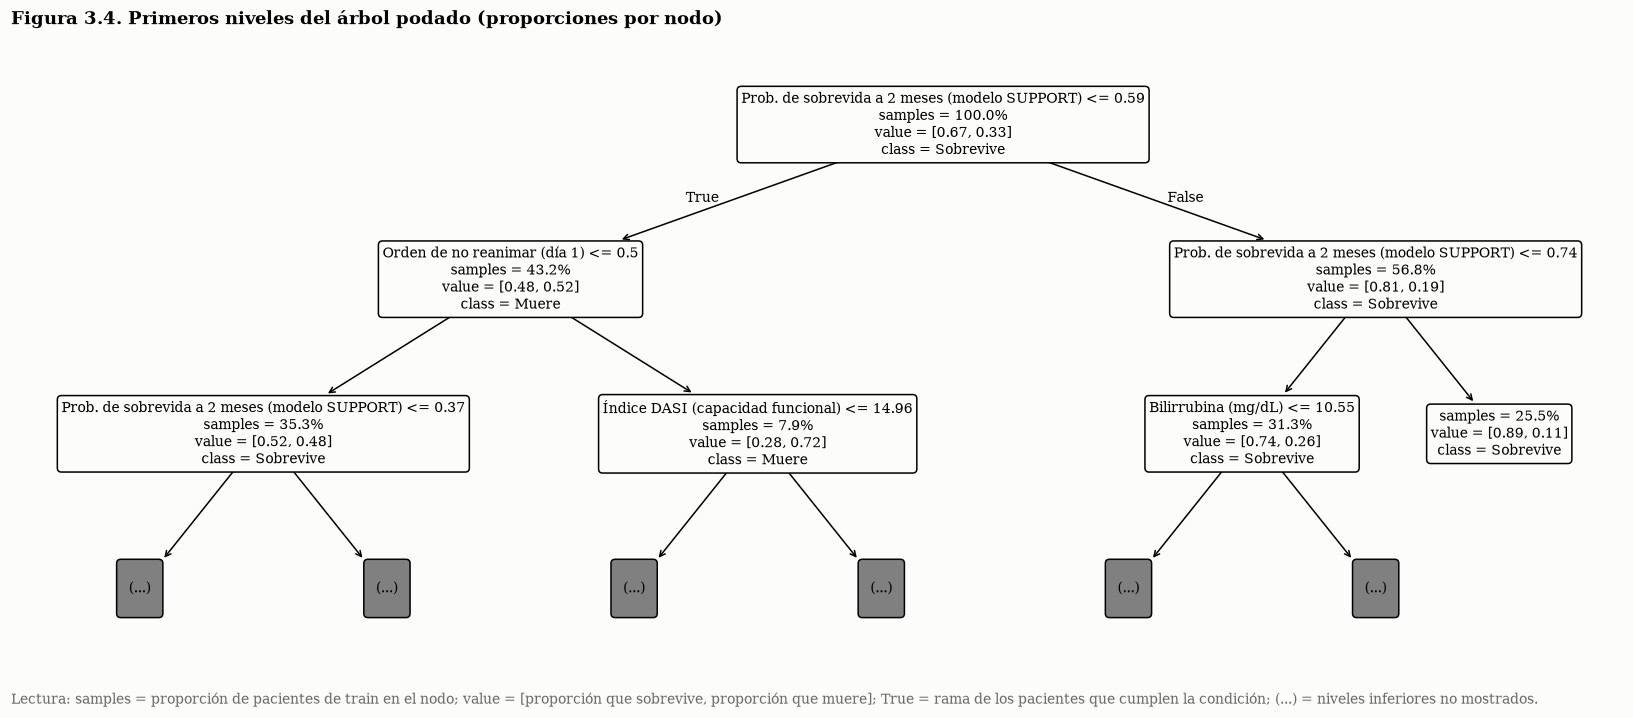

Regla del nodo raíz: Prob. de sobrevida a 2 meses (modelo SUPPORT) ≤ 0.591
  Rama izquierda (cumple la regla): 1,981 pacientes, mortalidad 52.1%
  Rama derecha (no la cumple): 2,607 pacientes, mortalidad 19.2%


In [46]:
names_tree = [cfg.pretty(n) for n in tree_pruned[0].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(15, 6.5))
plot_tree(tree_pruned[-1], max_depth=2, feature_names=names_tree, class_names=["Sobrevive", "Muere"],
          filled=False, impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax, precision=2)
ax.grid(False)
viz.figure_title(fig, "3.4", "Primeros niveles del árbol podado (proporciones por nodo)")
fig.text(0.01, 0.01, "Lectura: samples = proporción de pacientes de train en el nodo; value = [proporción que sobrevive, proporción que muere]; "
         "True = rama de los pacientes que cumplen la condición; (...) = niveles inferiores no mostrados.", fontsize=9, color=viz.MUTED)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "fig_3_4_arbol")
plt.show()

t = tree_pruned[-1].tree_
root_feat = tree_pruned[0].get_feature_names_out()[t.feature[0]]
left, right = t.children_left[0], t.children_right[0]
print(f"Regla del nodo raíz: {cfg.pretty(root_feat)} ≤ {t.threshold[0]:.3f}")
print(f"  Rama izquierda (cumple la regla): {t.n_node_samples[left]:,} pacientes, mortalidad {t.value[left][0][1]:.1%}")
print(f"  Rama derecha (no la cumple): {t.n_node_samples[right]:,} pacientes, mortalidad {t.value[right][0][1]:.1%}")

**Interpretación.** La curva de validación (Figura 3.3, izquierda) muestra el compromiso entre sesgo y varianza. Con $\alpha$ muy chico el árbol sobreajusta: el AUC en los pliegues de ajuste es cercano a 1, pero en validación es bajo. A medida que $\alpha$ crece, el árbol pierde hojas y gana capacidad de generalización hasta el óptimo. Más allá de ese punto, la poda elimina estructura útil y ambas curvas descienden. El árbol podado conserva unas 16 hojas, frente a las más de 700 del árbol sin restricciones.

**Regla del nodo raíz.** El primer corte usa la **probabilidad de sobrevida a 2 meses estimada por SUPPORT**, con umbral cercano a 0,59. Los pacientes por debajo del umbral tienen una mortalidad a 30 días de alrededor de 52 %; los que lo superan, de alrededor de 19 %. En la rama de mayor riesgo, el siguiente corte es la orden de no reanimar. El árbol confirma, con una regla legible para un médico, lo que la regresión logística mostró en forma de odds ratios: el pronóstico global al ingreso es el factor que más ordena el riesgo.

## 3.5 Familia 4: Random Forest y búsqueda de hiperparámetros

Un Random Forest promedia muchos árboles profundos entrenados sobre muestras bootstrap y, en cada corte, sobre un subconjunto aleatorio de variables (`max_features`). El promedio reduce la varianza que hundía al árbol individual. Se optimizan los cinco hiperparámetros pedidos con `RandomizedSearchCV` (20 combinaciones × 5 pliegues = 100 ajustes), una alternativa más eficiente que la búsqueda exhaustiva cuando el espacio es grande.

In [47]:
param_rf = {
    "modelo__n_estimators": [200, 300, 500],
    "modelo__max_depth": [None, 6, 10, 15],
    "modelo__min_samples_split": [2, 10, 30],
    "modelo__min_samples_leaf": [1, 5, 10, 20],
    "modelo__max_features": ["sqrt", "log2", 0.3, 0.5],
}
rf_search = RandomizedSearchCV(mdl.build_forest(), param_rf, n_iter=20, cv=cv, random_state=cfg.SEED,
                               scoring={"auc": "roc_auc", "exactitud": "accuracy"}, refit="auc", n_jobs=1)
rf_search.fit(train, y_tr)
rf_best = rf_search.best_estimator_
best_idx = rf_search.best_index_
cvr = rf_search.cv_results_
print("Mejores hiperparámetros:", {k.replace("modelo__", ""): v for k, v in rf_search.best_params_.items()})
print(f"Validación cruzada: AUC = {cvr['mean_test_auc'][best_idx]:.4f} · exactitud = {cvr['mean_test_exactitud'][best_idx]:.4f}")
print(f"Out-of-bag:        exactitud = {rf_best[-1].oob_score_:.4f}")

Mejores hiperparámetros: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 15}
Validación cruzada: AUC = 0.7728 · exactitud = 0.7441
Out-of-bag:        exactitud = 0.7441


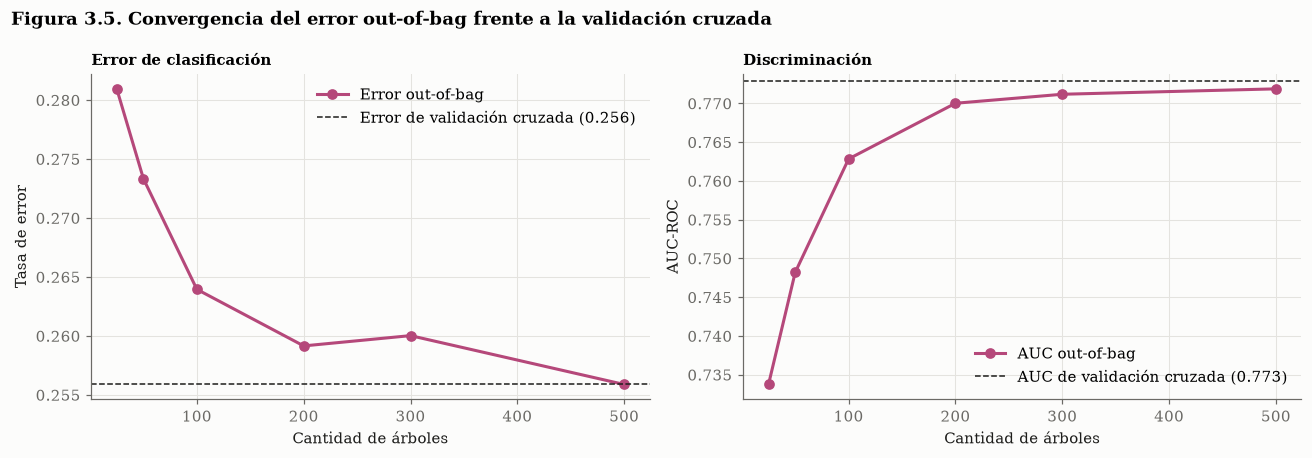

,árboles,error_OOB,AUC_OOB
0,25,0.281,0.734
1,50,0.273,0.748
2,100,0.264,0.763
3,200,0.259,0.770
4,300,0.260,0.771
5,500,0.256,0.772


In [48]:
rf_params = {k.replace("modelo__", ""): v for k, v in rf_search.best_params_.items()}
oob = mdl.oob_convergence(mdl.build_forest(**rf_params), train, y_tr)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cv_err = 1 - cvr["mean_test_exactitud"][best_idx]
axes[0].plot(oob["árboles"], oob["error_OOB"], marker="o", color=viz.MODEL_COLORS["Random Forest"], label="Error out-of-bag")
axes[0].axhline(cv_err, color=viz.INK, lw=1, ls="--", label=f"Error de validación cruzada ({cv_err:.3f})")
axes[0].set_xlabel("Cantidad de árboles")
axes[0].set_ylabel("Tasa de error")
axes[0].set_title("Error de clasificación", fontsize=10)
axes[0].legend(loc="upper right")
axes[1].plot(oob["árboles"], oob["AUC_OOB"], marker="o", color=viz.MODEL_COLORS["Random Forest"], label="AUC out-of-bag")
axes[1].axhline(cvr["mean_test_auc"][best_idx], color=viz.INK, lw=1, ls="--",
                label=f"AUC de validación cruzada ({cvr['mean_test_auc'][best_idx]:.3f})")
axes[1].set_xlabel("Cantidad de árboles")
axes[1].set_ylabel("AUC-ROC")
axes[1].set_title("Discriminación", fontsize=10)
axes[1].legend(loc="lower right")
viz.figure_title(fig, "3.5", "Convergencia del error out-of-bag frente a la validación cruzada")
fig.tight_layout()
save(fig, "fig_3_5_oob")
plt.show()
oob.round(4)

**Interpretación.** Cada árbol del bosque se entrena con una muestra bootstrap que deja afuera, en promedio, alrededor de un tercio de los pacientes ($e^{-1} \approx 0{,}368$). Esos pacientes *out-of-bag* funcionan como un conjunto de validación interno y gratuito. La Figura 3.5 muestra que el error y el AUC out-of-bag se estabilizan a partir de unos 200 árboles y convergen a los valores de la validación cruzada de 5 pliegues. Las dos estimaciones del error de generalización coinciden, y agregar árboles por encima de 300 no mejora el modelo: solo encarece su cómputo.

## 3.6 Evaluación final en el conjunto de test

Los cuatro modelos se reentrenan con todo train, con los hiperparámetros elegidos por validación cruzada, y se evalúan sobre los 1.147 pacientes de test, que no intervinieron en ninguna de esas decisiones. Las métricas que requieren una clasificación (precisión, recall, F1) usan el umbral convencional de 0,5; las de discriminación (AUC-ROC, PR-AUC) y calibración (Brier) usan la probabilidad completa.

In [49]:
nb_model.fit(train, y_tr)
logit_best = logit_l2.best_estimator_
models_final = {"Logística": logit_best, "Naive Bayes": nb_model, "Árbol podado": tree_pruned, "Random Forest": rf_best}
probas = {name: m.predict_proba(test)[:, 1] for name, m in models_final.items()}
metrics_test = pd.DataFrame({name: mdl.classification_metrics(y_te, p) for name, p in probas.items()}).T
metrics_test.loc["Árbol sin poda (referencia)"] = mdl.classification_metrics(y_te, tree_full.predict_proba(test)[:, 1])
metrics_test.round(3)

,AUC-ROC,PR-AUC,Brier,Precisión,Recall,F1,F1 macro,F1 ponderado
Logística,0.776,0.633,0.177,0.656,0.422,0.513,0.664,0.714
Naive Bayes,0.767,0.612,0.216,0.618,0.523,0.567,0.687,0.726
Árbol podado,0.744,0.552,0.187,0.615,0.440,0.513,0.658,0.706
Random Forest,0.779,0.628,0.177,0.675,0.406,0.507,0.663,0.715
Árbol sin poda (referencia),0.585,0.386,0.364,0.455,0.430,0.442,0.586,0.634


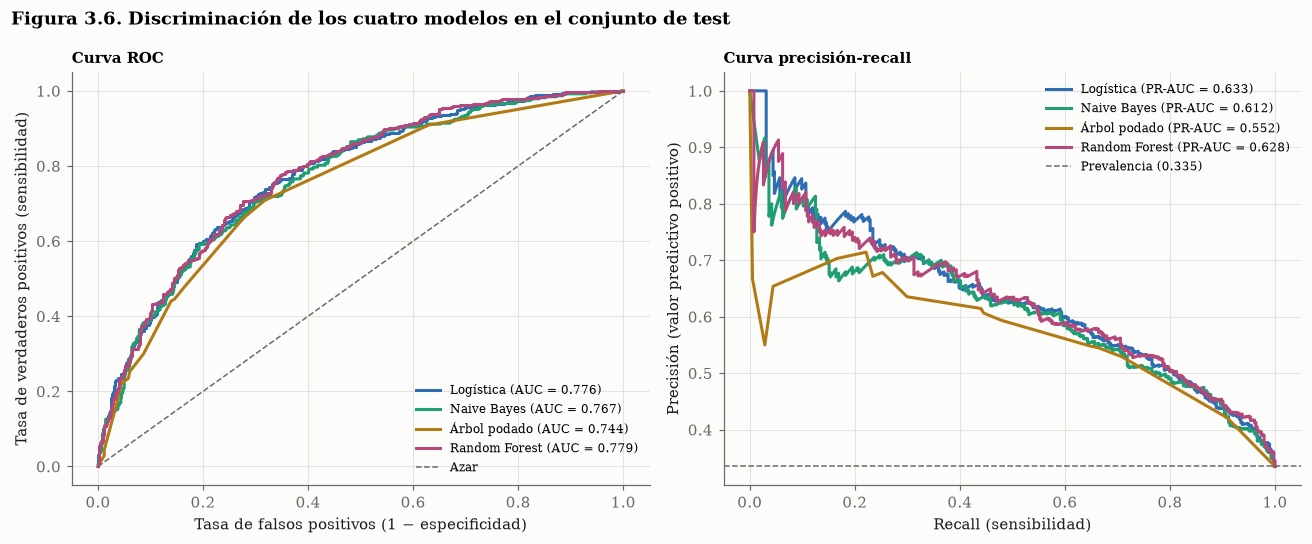

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, color=viz.MODEL_COLORS[name], lw=2, label=f"{name} (AUC = {roc_auc_score(y_te, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rec, prec, color=viz.MODEL_COLORS[name], lw=2,
                 label=f"{name} (PR-AUC = {metrics_test.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=viz.MUTED, lw=1, ls="--", label="Azar")
axes[0].set_xlabel("Tasa de falsos positivos (1 − especificidad)")
axes[0].set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
axes[0].set_title("Curva ROC", fontsize=10)
axes[0].legend(loc="lower right", fontsize=8)
axes[1].axhline(y_te.mean(), color=viz.MUTED, lw=1, ls="--", label=f"Prevalencia ({y_te.mean():.3f})")
axes[1].set_xlabel("Recall (sensibilidad)")
axes[1].set_ylabel("Precisión (valor predictivo positivo)")
axes[1].set_title("Curva precisión-recall", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
viz.figure_title(fig, "3.6", "Discriminación de los cuatro modelos en el conjunto de test")
fig.tight_layout()
save(fig, "fig_3_6_roc_pr")
plt.show()

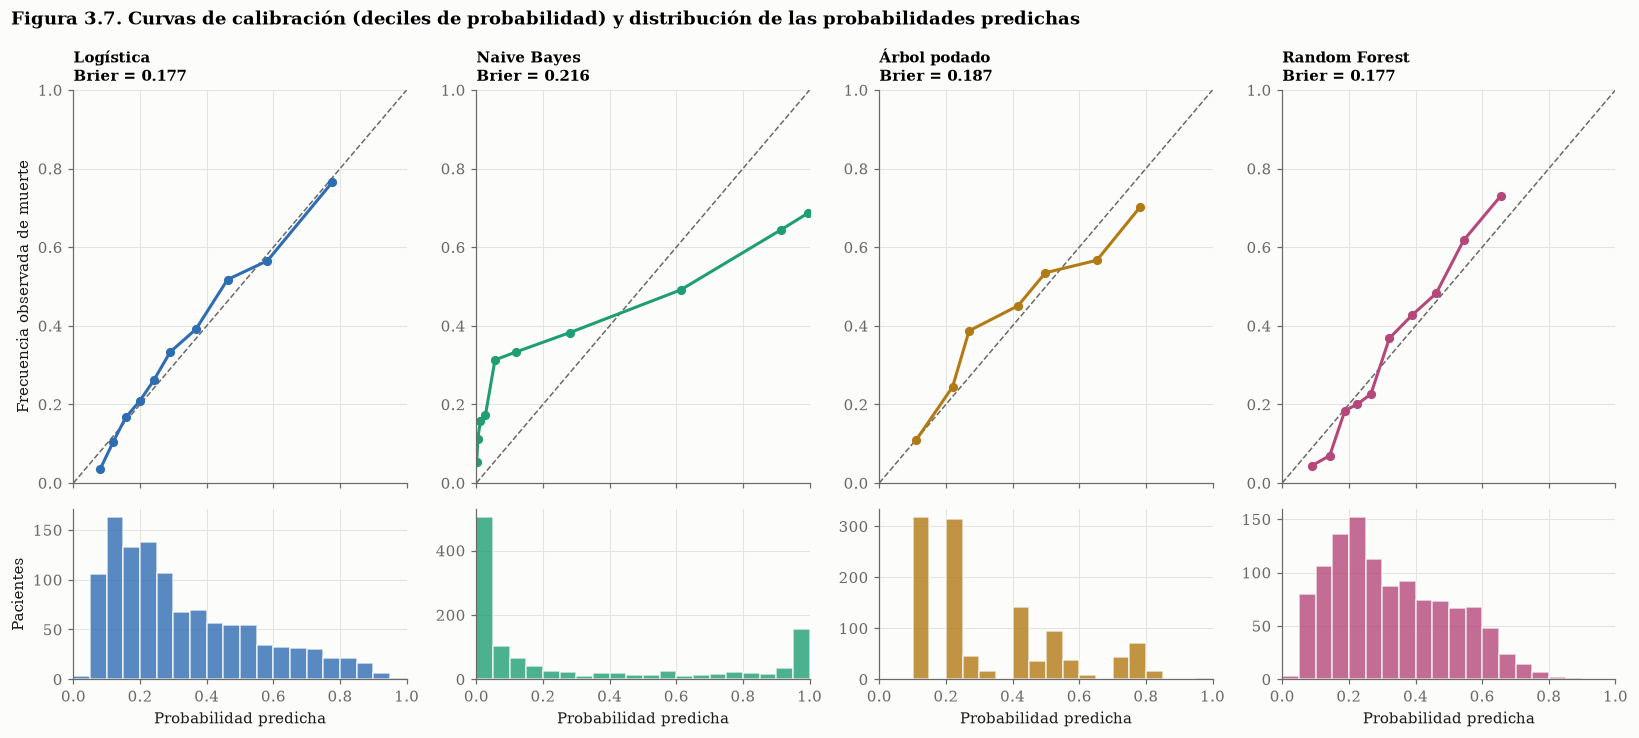

,"p < 0,05","p > 0,95"
Logística,0.003,0.001
Naive Bayes,0.439,0.136
Árbol podado,0.000,0.003
Random Forest,0.003,0.000


In [51]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.8), gridspec_kw={"height_ratios": [3, 1.3]}, sharex=True)
for j, (name, p) in enumerate(probas.items()):
    cal = mdl.calibration_table(y_te, p)
    ax = axes[0, j]
    ax.plot([0, 1], [0, 1], color=viz.MUTED, lw=1, ls="--")
    ax.plot(cal["prob_predicha"], cal["frecuencia_observada"], marker="o", ms=5, color=viz.MODEL_COLORS[name])
    ax.set_title(f"{name}\nBrier = {metrics_test.loc[name, 'Brier']:.3f}", fontsize=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    if j == 0:
        ax.set_ylabel("Frecuencia observada de muerte")
    axes[1, j].hist(p, bins=20, range=(0, 1), color=viz.MODEL_COLORS[name], alpha=0.8, edgecolor=viz.SURFACE)
    axes[1, j].set_xlabel("Probabilidad predicha")
    if j == 0:
        axes[1, j].set_ylabel("Pacientes")
viz.figure_title(fig, "3.7", "Curvas de calibración (deciles de probabilidad) y distribución de las probabilidades predichas")
fig.tight_layout()
save(fig, "fig_3_7_calibracion")
plt.show()

extremes = pd.DataFrame({name: {"p < 0,05": (p < 0.05).mean(), "p > 0,95": (p > 0.95).mean()}
                         for name, p in probas.items()}).T
extremes.round(3)

**Interpretación de la discriminación** (tabla y Figura 3.6):

- **Random Forest** y **logística** encabezan el torneo con AUC prácticamente idénticos (alrededor de 0,78) y las mismas métricas de calibración (Brier ≈ 0,177).
- **Naive Bayes** discrimina casi igual (AUC ≈ 0,77), lo que confirma que la violación de la independencia condicional afecta poco al *orden* de los pacientes.
- **El árbol podado** queda detrás (AUC ≈ 0,74): una sola partición del espacio pierde información que el ensamble recupera. Aun así, supera ampliamente al árbol sin poda (0,59).
- **Los valores de PR-AUC** (0,55 a 0,63) deben leerse frente a la prevalencia del 33 % de muertes, que es la PR-AUC de un clasificador al azar.

**Interpretación de la calibración** (Figura 3.7):

- La logística, el Random Forest y el árbol siguen de cerca la diagonal: cuando predicen 40 % de riesgo, muere alrededor del 40 % de esos pacientes.
- **Naive Bayes está mal calibrado**, tal como anticipaba la sección 3.3. Asigna probabilidades menores a 5 % o mayores a 95 % a más de la mitad de los pacientes, frente a menos del 1 % en la logística. Su curva se aleja de la diagonal en los extremos: el modelo es sobreconfiado, y su Brier es el peor del torneo (≈ 0,216). Un médico que usara esas probabilidades para informar un pronóstico a la familia comunicaría certezas que el modelo no tiene.

**Elección del modelo final.** La elección se hace con la información de train. En validación cruzada, el Random Forest obtuvo un AUC de 0,773 frente a 0,760 de la logística: una ventaja de 0,013. Ante una diferencia tan pequeña, se elige la **regresión logística** como modelo final y como motor del módulo predictivo de la aplicación web, por cuatro razones:

1. Es interpretable: cada predicción se descompone en la contribución de cada variable, lo que permite explicar el caso individual al usuario.
2. Es parsimoniosa: el modelo serializado ocupa unos pocos kilobytes, frente a varios megabytes del bosque.
3. Es estable: un modelo lineal regularizado tiene menor varianza entre muestras que un ensamble de árboles profundos.
4. Sus odds ratios conectan directamente con la literatura clínica.

La comparación en test, con un bootstrap de 2.000 remuestreos de los pacientes, verifica después si la ventaja del Random Forest se sostiene en datos no vistos.

In [52]:
diff = mdl.bootstrap_auc_difference(y_te.to_numpy(), probas["Random Forest"], probas["Logística"])
print(f"AUC(Random Forest) − AUC(Logística) = {diff['diferencia']:.4f} "
      f"· IC 95 % bootstrap = [{diff['IC_inf']:.4f}; {diff['IC_sup']:.4f}] · p ≈ {diff['p_bilateral']:.2f}")

AUC(Random Forest) − AUC(Logística) = 0.0026 · IC 95 % bootstrap = [-0.0092; 0.0152] · p ≈ 0.68


El intervalo contiene al cero con holgura: en pacientes no vistos, **la ventaja del Random Forest no se distingue del azar**, y los dos modelos calibran igual (mismo Brier). El test confirma la elección hecha con train; no la determina.

### Elección del umbral de decisión

Con una prevalencia de muerte del 33 %, el umbral convencional de 0,5 es conservador: clasifica como "muere" solo a los pacientes cuyo riesgo predicho supera en una vez y media la prevalencia, y deja sin detectar a una parte importante de los que mueren. En un contexto clínico, no detectar a un paciente de alto riesgo suele ser más costoso que una falsa alarma. Se elige un umbral alternativo maximizando el índice de Youden ($J = \text{sensibilidad} + \text{especificidad} - 1$) sobre las predicciones **fuera de pliegue de train**, nunca sobre test, para que la evaluación siga siendo honesta.

In [53]:
oof = cross_val_predict(mdl.build_logit(C=logit_l2.best_params_["modelo__C"]), train, y_tr, cv=cv,
                        method="predict_proba")[:, 1]
fpr_tr, tpr_tr, thr_tr = roc_curve(y_tr, oof)
threshold_youden = float(thr_tr[np.argmax(tpr_tr - fpr_tr)])
thr_cmp = pd.DataFrame({
    "Umbral 0,5": mdl.classification_metrics(y_te, probas["Logística"], 0.5),
    f"Umbral de Youden ({threshold_youden:.3f})": mdl.classification_metrics(y_te, probas["Logística"], threshold_youden),
}).T[["Precisión", "Recall", "F1", "F1 macro", "F1 ponderado"]]
thr_cmp.round(3)

,Precisión,Recall,F1,F1 macro,F1 ponderado
"Umbral 0,5",0.656,0.422,0.513,0.664,0.714
Umbral de Youden (0.320),0.558,0.674,0.611,0.691,0.718


Con el umbral de Youden (alrededor de 0,32, cercano a la prevalencia), el recall medido en test sube de 0,42 a 0,67 y el F1 de la clase "muere" de 0,51 a 0,61, a cambio de una precisión menor. El umbral es una **decisión de negocio**, no estadística: depende del costo relativo de un falso negativo frente a un falso positivo, y la aplicación web lo expone como un parámetro ajustable.

## 3.7 Explicabilidad: MDI frente a importancia por permutación

- **MDI** (*mean decrease in impurity*): suma la reducción de impureza de Gini que logra cada variable en todos los cortes de todos los árboles, calculada **sobre los datos de entrenamiento**.
- **Importancia por permutación**: mide cuánto cae el AUC en **test** cuando se desordenan al azar los valores de una variable, rompiendo su relación con el resultado.

**Experimento de control.** Para hacer visible el sesgo de MDI, se agrega a los datos una variable de **ruido puro**, normal estándar e independiente de todo. Una medida de importancia confiable debería asignarle importancia nula.

In [54]:
rng_noise = np.random.default_rng(cfg.SEED)
pre_rf = build_preprocessor().fit(train)
X_tr_n, X_te_n = pre_rf.transform(train), pre_rf.transform(test)
X_tr_n["ruido_aleatorio"] = rng_noise.normal(size=len(X_tr_n))
X_te_n["ruido_aleatorio"] = rng_noise.normal(size=len(X_te_n))
rf_noise = RandomForestClassifier(**rf_params, random_state=cfg.SEED, n_jobs=-1).fit(X_tr_n, y_tr)

mdi = pd.Series(rf_noise.feature_importances_, index=X_tr_n.columns).sort_values(ascending=False)
perm = permutation_importance(rf_noise, X_te_n, y_te, scoring="roc_auc", n_repeats=5, random_state=cfg.SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_tr_n.columns).sort_values(ascending=False)
perm_sd = pd.Series(perm.importances_std, index=X_tr_n.columns)
binary_cols = [c for c in X_tr_n.columns if c not in cfg.NUMERIC_FEATURES + ["ruido_aleatorio"]]
ranking = pd.DataFrame({
    "puesto MDI": [list(mdi.index).index(c) + 1 for c in ["ruido_aleatorio", "dnr1", "rhc", "surv2md1"]],
    "puesto permutación": [list(perm_s.index).index(c) + 1 for c in ["ruido_aleatorio", "dnr1", "rhc", "surv2md1"]],
}, index=["Ruido aleatorio", "Orden de no reanimar (binaria)", "RHC (binaria)", "Prob. de sobrevida (continua)"])
print(f"Variables totales: {len(mdi)} · Participación de las {len(binary_cols)} binarias en el MDI total: "
      f"{mdi[binary_cols].sum():.1%}")
ranking

Variables totales: 69 · Participación de las 47 binarias en el MDI total: 21.5%


,puesto MDI,puesto permutación
Ruido aleatorio,9,69
Orden de no reanimar (binaria),18,2
RHC (binaria),27,8
Prob. de sobrevida (continua),1,1


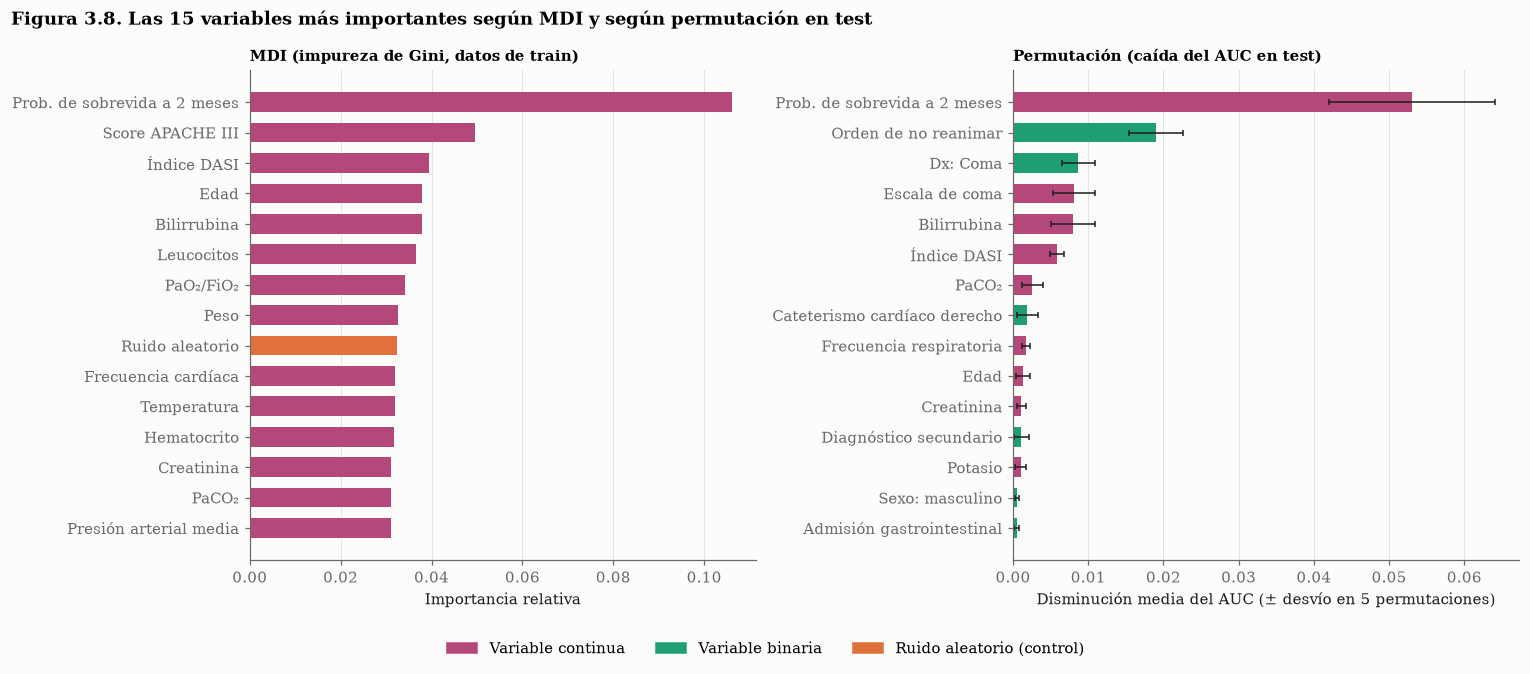

Importancia por permutación del ruido: -0.0015 ± 0.0006


In [55]:
def label_imp(c):
    return "Ruido aleatorio" if c == "ruido_aleatorio" else cfg.pretty(c).split(" (")[0]

top_mdi = mdi.head(15).iloc[::-1]
top_perm = perm_s.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, s, title, err in [(axes[0], top_mdi, "MDI (impureza de Gini, datos de train)", None),
                          (axes[1], top_perm, "Permutación (caída del AUC en test)", perm_sd)]:
    colors = [viz.RHC if c == "ruido_aleatorio" else (viz.MODEL_COLORS["Random Forest"] if c in cfg.NUMERIC_FEATURES
              else viz.THIRD) for c in s.index]
    ax.barh(np.arange(len(s)), s.values, color=colors, height=0.65,
            xerr=None if err is None else err[s.index].values, error_kw=dict(ecolor=viz.INK, lw=1, capsize=2))
    ax.set_yticks(np.arange(len(s)), [label_imp(c) for c in s.index])
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
axes[1].set_xlabel("Disminución media del AUC (± desvío en 5 permutaciones)")
axes[0].set_xlabel("Importancia relativa")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=viz.MODEL_COLORS["Random Forest"], label="Variable continua"),
                    Patch(color=viz.THIRD, label="Variable binaria"),
                    Patch(color=viz.RHC, label="Ruido aleatorio (control)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
viz.figure_title(fig, "3.8", "Las 15 variables más importantes según MDI y según permutación en test")
fig.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, "fig_3_8_mdi_permutacion")
plt.show()
print(f"Importancia por permutación del ruido: {perm_s['ruido_aleatorio']:.4f} ± {perm_sd['ruido_aleatorio']:.4f}")

**El dilema crítico.** En el ranking de MDI, la variable de ruido aleatorio ocupa el **puesto 9**, por encima de decenas de variables clínicas reales, entre ellas todas las binarias. En el ranking por permutación en test cae al **último lugar**, con importancia nula (incluso levemente negativa). A la inversa, la orden de no reanimar, una variable binaria, es la segunda más importante por permutación y queda relegada en MDI.

**¿Por qué MDI favorece a las variables continuas de alta cardinalidad?**

1. **Más oportunidades de corte.** Una variable binaria ofrece un único punto de corte posible; una continua con miles de valores distintos ofrece miles. En cada nodo, el árbol elige el mejor corte entre todos los candidatos, de modo que una variable con muchos umbrales tiene más probabilidad de encontrar, solo por azar, uno que reduzca la impureza de la muestra.
2. **Se mide sobre los datos de entrenamiento.** Los árboles profundos del bosque siguen cortando hasta nodos muy pequeños, donde cualquier variable continua, incluso el ruido, logra separar unos pocos pacientes. MDI contabiliza esas reducciones de impureza aunque no generalicen.

**¿Por qué la permutación en test neutraliza el sesgo?** Porque mide la contribución de cada variable a la **capacidad predictiva fuera de muestra**. Si se desordena el ruido, el AUC en test no cambia, porque los cortes que el bosque hizo sobre él solo ajustaban ruido de train. Si se desordena la orden de no reanimar, el AUC cae, porque esa información sí generaliza. La permutación no depende de la cantidad de umbrales de cada variable, sino del efecto de perderla.

**Hallazgo para la Fase 4.** El tratamiento RHC aparece entre las 10 variables más importantes por permutación: el modelo lo usa para predecir la mortalidad. Que una variable sea *predictiva* no implica que sea una *palanca causal*. Esta distinción es el eje del ensayo crítico de la Fase 4.

## 3.8 Persistencia del modelo para la aplicación web

El modelo logístico final, con su preprocesamiento incluido, se reentrena con todo train y se serializa con `joblib`. Se guarda junto con un archivo de metadatos que registra los hiperparámetros, las métricas en test y el umbral de Youden. La aplicación web carga estos archivos sin reentrenar.

In [56]:
import json
import joblib

cfg.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(logit_best, cfg.MODELS_DIR / "modelo_logistico.joblib")
metadata = {
    "modelo": "Regresión logística con penalización L2",
    "C": logit_l2.best_params_["modelo__C"],
    "resultado": cfg.OUTCOME_BIN,
    "umbral_youden": round(threshold_youden, 4),
    "metricas_test": metrics_test.loc["Logística"].round(4).to_dict(),
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "semilla": cfg.SEED,
}
(cfg.MODELS_DIR / "modelo_logistico.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
size_kb = (cfg.MODELS_DIR / "modelo_logistico.joblib").stat().st_size / 1024
print(f"Modelo guardado ({size_kb:.1f} KB) y metadatos en {cfg.MODELS_DIR.relative_to(ROOT)}")

reloaded = joblib.load(cfg.MODELS_DIR / "modelo_logistico.joblib")
assert np.allclose(reloaded.predict_proba(test)[:, 1], probas["Logística"]), "El modelo recargado debe predecir igual"
print("Verificación: el modelo recargado reproduce exactamente las probabilidades de test.")

Modelo guardado (12.6 KB) y metadatos en models
Verificación: el modelo recargado reproduce exactamente las probabilidades de test.


## 3.9 Síntesis de la Fase 3

| Familia | Hallazgo principal | AUC test | Brier |
|---|---|---|---|
| Logística L2 | Empata con el Random Forest; mejor relación entre desempeño e interpretabilidad. OR del RHC ajustado ≈ 1,33 | ≈ 0,78 | ≈ 0,177 |
| Naive Bayes mixto | Discrimina bien, pero viola la independencia condicional y produce probabilidades sobreconfiadas | ≈ 0,77 | ≈ 0,216 |
| Árbol CART | Sin poda memoriza train (exactitud 100 % frente a 64 % en test); la poda por $\alpha$ lo reduce a unas 16 hojas legibles | ≈ 0,74 | ≈ 0,19 |
| Random Forest | Mejor AUC puntual, sin diferencia significativa con la logística; el error out-of-bag converge al de validación cruzada | ≈ 0,78 | ≈ 0,177 |

**Decisiones:** se adopta la regresión logística como modelo final, con un umbral de Youden de alrededor de 0,32 elegido sin tocar test. MDI se descarta como medida de importancia en favor de la permutación en test, porque asigna importancia a una variable de ruido puro.

---
# Fase 4. Inferencia causal, Causal ML y el choque causal frente al predictivo

Las fases anteriores respondieron preguntas de asociación. La Fase 1 mostró que los pacientes con RHC mueren más (+7,4 puntos porcentuales), y la Fase 3, que el RHC es un predictor útil de la mortalidad. Ninguno de esos resultados responde la pregunta que importa a la dirección médica: **si se le aplica RHC a un paciente, ¿cambia su probabilidad de morir?** Esa es una pregunta sobre una intervención, $P(Y \mid do(T = 1))$, y requiere el marco causal estructural de Pearl.

El efecto causal promedio (ATE) se define sobre los resultados potenciales de cada paciente, $Y(1)$ con RHC e $Y(0)$ sin RHC:

$$\text{ATE} = E[Y(1) - Y(0)] = P(Y = 1 \mid do(T = 1)) - P(Y = 1 \mid do(T = 0))$$

Como el resultado es binario, el ATE es una **diferencia de riesgos**: un ATE de 0,05 significa que aplicar RHC aumenta la mortalidad a 30 días en 5 puntos porcentuales.

## 4.1 Formalización del grafo acíclico dirigido (DAG)

In [57]:
import json
import logging

warnings.filterwarnings("ignore", message="IProgress not found")
import networkx as nx
from dowhy import CausalModel
from econml.dml import CausalForestDML, LinearDML
from matplotlib.patches import FancyBboxPatch
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from rhc import causal as cz

logging.getLogger("dowhy").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

causal_data, Z_cols = cz.causal_frame(data)
# Nombre original de cada columna de Z (las versiones "seguras" reemplazan espacios y símbolos).
orig_name = {cz.safe_name(n): n for n in build_preprocessor(include_treatment=False).fit(data).get_feature_names_out()}
T_c, Y_c = causal_data[cfg.TREATMENT].to_numpy(), causal_data[cfg.OUTCOME_BIN].to_numpy()
print(f"Pacientes en el análisis causal: {len(causal_data):,} · Confusores observados (columnas de Z): {len(Z_cols)}")

Pacientes en el análisis causal: 5,734 · Confusores observados (columnas de Z): 67


**Roles de las variables.**

| Rol | Variable | Justificación |
|---|---|---|
| Tratamiento $T$ | RHC en las primeras 24 h ($T \in \{0, 1\}$) | Decisión clínica manipulable: es la palanca sobre la que la dirección médica puede fijar una política. |
| Resultado $Y$ | Muerte a 30 días | Resultado primario de Connors et al. (1996), lo que permite contrastar las estimaciones con la literatura. |
| Confusores $Z$ | 67 columnas basales agrupadas en cuatro bloques: demografía y nivel socioeconómico ($Z_1$), diagnóstico y comorbilidades ($Z_2$), gravedad fisiológica del día 1 ($Z_3$), pronóstico y preferencias ($Z_4$) | Todas se miden al ingreso, antes o en simultáneo con la decisión de cateterizar, y cada bloque influye tanto en esa decisión como en el riesgo de muerte (evidencia de las Fases 1 y 3). |
| Mediador $M$ | Intensificación terapéutica posterior al RHC: fluidos, inotrópicos, vasopresores, procedimientos adicionales (**no observada**) | El mecanismo por el cual el catéter podría alterar la mortalidad es el cambio de conducta terapéutica que induce su lectura, más las complicaciones del propio procedimiento. |
| Colisionador $C$ | Días de internación | El RHC prolonga la estadía (Fase 2: +14 %) y la muerte la acorta (Fase 1: correlación de −0,42). Es un efecto común: $T \rightarrow C \leftarrow Y$. |
| Confusor latente $U$ | Criterio del médico tratante y hospital (**no observados**) | El médico decide cateterizar con información clínica que no queda registrada, y el dataset no identifica el centro. Es la amenaza principal a la validez interna (sección 4.5). |

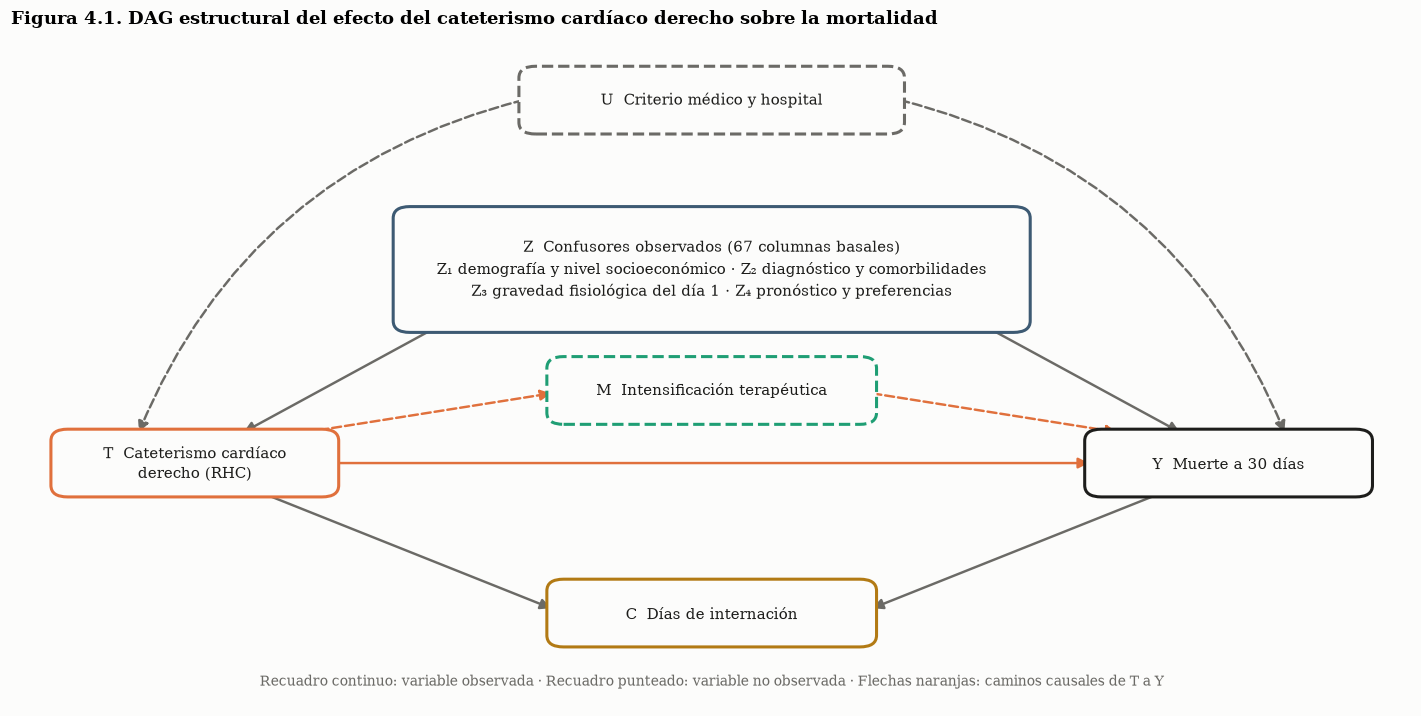

DAG exportado en formato DOT y JSON en la carpeta models/


In [58]:
boxes = {  # centro (x, y), semiancho, semialto, texto, color, latente
    "Z": ((4.6, 3.0), 2.25, 0.62, "Z  Confusores observados (67 columnas basales)\n"
          "Z₁ demografía y nivel socioeconómico · Z₂ diagnóstico y comorbilidades\n"
          "Z₃ gravedad fisiológica del día 1 · Z₄ pronóstico y preferencias", "#3d5a73", False),
    "T": ((0.9, 1.0), 1.0, 0.32, "T  Cateterismo cardíaco\nderecho (RHC)", viz.RHC, False),
    "Y": ((8.3, 1.0), 1.0, 0.32, "Y  Muerte a 30 días", viz.INK, False),
    "M": ((4.6, 1.75), 1.15, 0.32, "M  Intensificación terapéutica", viz.THIRD, True),
    "C": ((4.6, -0.55), 1.15, 0.32, "C  Días de internación", "#b27a14", False),
    "U": ((4.6, 4.75), 1.35, 0.32, "U  Criterio médico y hospital", viz.MUTED, True),
}
arrows = [  # (origen, destino, punto de salida, punto de llegada, curvatura)
    ("Z", "T", (2.6, 2.38), (1.25, 1.32), 0.0), ("Z", "Y", (6.6, 2.38), (7.95, 1.32), 0.0),
    ("T", "M", (1.7, 1.32), (3.45, 1.72), 0.0), ("M", "Y", (5.75, 1.72), (7.5, 1.32), 0.0),
    ("T", "Y", (1.9, 1.0), (7.3, 1.0), 0.0),
    ("T", "C", (1.4, 0.68), (3.45, -0.5), 0.0), ("Y", "C", (7.8, 0.68), (5.75, -0.5), 0.0),
    ("U", "T", (3.25, 4.75), (0.5, 1.32), 0.25), ("U", "Y", (5.95, 4.75), (8.7, 1.32), -0.25),
]
fig, ax = plt.subplots(figsize=(13, 6.6))
for key, ((x, y0), hw, hh, text, color, latent) in boxes.items():
    ax.add_patch(FancyBboxPatch((x - hw, y0 - hh), 2 * hw, 2 * hh, boxstyle="round,pad=0.03,rounding_size=0.12",
                                fc=viz.SURFACE, ec=color, lw=2, ls="--" if latent else "-", zorder=2))
    ax.text(x, y0, text, ha="center", va="center", fontsize=9.5, color=viz.INK, zorder=3, linespacing=1.5)
for a, b, start, end, rad in arrows:
    causal = (a, b) in [("T", "M"), ("M", "Y"), ("T", "Y")]
    dashed = boxes[a][5] or boxes[b][5]
    ax.annotate("", xy=end, xytext=start, zorder=1,
                arrowprops=dict(arrowstyle="-|>", lw=1.6, mutation_scale=14, color=viz.RHC if causal else viz.MUTED,
                                ls="--" if dashed else "-", shrinkA=0, shrinkB=0, connectionstyle=f"arc3,rad={rad}"))
ax.text(4.6, -1.3, "Recuadro continuo: variable observada · Recuadro punteado: variable no observada · "
        "Flechas naranjas: caminos causales de T a Y", ha="center", fontsize=9, color=viz.MUTED)
ax.set_xlim(-0.4, 9.6)
ax.set_ylim(-1.5, 5.3)
ax.axis("off")
viz.figure_title(fig, "4.1", "DAG estructural del efecto del cateterismo cardíaco derecho sobre la mortalidad")
fig.tight_layout()
save(fig, "fig_4_1_dag")
plt.show()

(cfg.MODELS_DIR / "dag.dot").write_text(cz.dag_dot())
(cfg.MODELS_DIR / "dag.json").write_text(json.dumps(
    {"nodos": cz.DAG_NODES, "arcos": cz.DAG_EDGES, "latentes": sorted(cz.LATENT)}, indent=2, ensure_ascii=False))
print("DAG exportado en formato DOT y JSON en la carpeta models/")

**Justificación de los arcos principales** (el detalle de cada arco y de su plausibilidad se registra en la Entrada 4 de la Bitácora):

- $Z_3 \rightarrow T$ y $Z_3 \rightarrow Y$: la gravedad fisiológica orienta la decisión de cateterizar (la Fase 1 mostró un APACHE 9,8 puntos mayor en los tratados) y es el principal determinante de la mortalidad.
- $Z_2 \rightarrow T$ y $Z_2 \rightarrow Y$: el diagnóstico condiciona la indicación (57 % de RHC en sepsis frente a 13 % en coma) y el pronóstico.
- $Z_1 \rightarrow T$: la cobertura médica y el ingreso pueden afectar el acceso a un procedimiento costoso; $Z_1 \rightarrow Y$: la edad y el nivel socioeconómico afectan la sobrevida.
- $Z_4 \rightarrow T$ y $Z_4 \rightarrow Y$: una orden de no reanimar desalienta procedimientos invasivos y se asocia con mayor mortalidad.
- $T \rightarrow M \rightarrow Y$ y $T \rightarrow Y$: el efecto del RHC opera a través de los cambios de tratamiento que induce su lectura y, de forma directa, a través de sus complicaciones (arritmias, infecciones, trombosis).
- $T \rightarrow C \leftarrow Y$: la estadía es consecuencia tanto del tratamiento como del resultado.

## 4.2 Identificación causal y criterio de puerta trasera

**Criterio backdoor (Pearl, 2009).** Un conjunto $Z$ identifica el efecto de $T$ sobre $Y$ si (i) ningún elemento de $Z$ es descendiente de $T$ y (ii) $Z$ bloquea todo camino entre $T$ e $Y$ que comienza con una flecha que entra en $T$. En ese caso:

$$P(Y \mid do(T = t)) = \sum_z P(Y \mid T = t, Z = z)\, P(Z = z)$$

**Demostración sobre el DAG de la Figura 4.1.**

1. **Condición (i).** Todas las variables de $Z$ se miden al ingreso; ninguna es consecuencia del RHC. La estadía ($C$) y la intensificación terapéutica ($M$) son descendientes de $T$ y por eso quedan **excluidas** del conjunto de ajuste.
2. **Condición (ii).** Los caminos de puerta trasera observados tienen la forma $T \leftarrow Z_k \rightarrow Y$ o $T \leftarrow Z_k \leftarrow Z_j \rightarrow Y$. En todos ellos, los nodos de $Z$ son no colisionadores (cadenas u horquillas), y condicionar en ellos **bloquea** el camino.
3. **Caminos que no deben bloquearse.** $T \rightarrow Y$ y $T \rightarrow M \rightarrow Y$ son los caminos causales: forman el efecto total que se quiere estimar.
4. **Caminos que no deben abrirse.** $T \rightarrow C \leftarrow Y$ tiene un colisionador en $C$, por lo que está bloqueado mientras no se condicione sobre la estadía.
5. **Camino no bloqueable.** $T \leftarrow U \rightarrow Y$ pasa por un confusor no observado. El criterio se cumple **bajo el supuesto** de que $U$ no existe o de que su efecto queda capturado por $Z$ (ignorabilidad condicional). Ese supuesto no puede verificarse con los datos y se somete a análisis de sensibilidad en la sección 4.5.

El motor de identificación de DoWhy confirma la demostración sobre el grafo operativo, en el que cada una de las 67 columnas de $Z$ apunta a $T$ y a $Y$:

In [59]:
graph = cz.dowhy_graph(Z_cols)
causal_model = CausalModel(data=causal_data, treatment=cfg.TREATMENT, outcome=cfg.OUTCOME_BIN, graph=graph)
estimand = causal_model.identify_effect(proceed_when_unidentifiable=True, method_name="maximal-adjustment")
backdoor_set = estimand.get_backdoor_variables()
print(f"Conjunto de ajuste backdoor identificado: {len(backdoor_set)} variables")
print(f"¿Incluye el colisionador (días de internación)? {cz.COLLIDER in backdoor_set}")
print(f"¿Incluye el mediador (intensificación terapéutica)? {cz.MEDIATOR in backdoor_set}")
print(f"¿Coincide con Z? {set(backdoor_set) == set(Z_cols)}")

Conjunto de ajuste backdoor identificado: 67 variables
¿Incluye el colisionador (días de internación)? False
¿Incluye el mediador (intensificación terapéutica)? False
¿Coincide con Z? True


### Las preguntas trampa: mediadores y colisionadores

**¿Qué ocurre si se condiciona sobre el mediador $M$?** Se bloquea el camino $T \rightarrow M \rightarrow Y$, y la regresión estima solo el efecto **directo**: se pierde la parte del efecto que opera a través de la intensificación terapéutica, y se subestima el impacto total de la política.

**¿Qué ocurre si se condiciona sobre el colisionador $C$?** Se abre el camino $T \rightarrow C \leftarrow Y$ y se induce una asociación espuria entre $T$ e $Y$ (sesgo de Berkson). Entre pacientes con la misma estadía, saber que alguien recibió RHC, que la prolonga, aporta información sobre si murió, que la acorta.

Como $M$ no se observa en este dataset, ambas consecuencias se demuestran primero con una **simulación de efecto conocido** que replica la estructura del DAG, y después, para el colisionador, con los **datos reales**.

In [60]:
trap_sim = cz.simulate_trap_questions()
display(trap_sim.round(4))

import statsmodels.api as sm
Xz = sm.add_constant(causal_data[[cfg.TREATMENT] + Z_cols])
Xzc = sm.add_constant(causal_data[[cfg.TREATMENT] + Z_cols + [cz.COLLIDER]])
fit_z = sm.OLS(causal_data[cfg.OUTCOME_BIN], Xz).fit(cov_type="HC3")
fit_zc = sm.OLS(causal_data[cfg.OUTCOME_BIN], Xzc).fit(cov_type="HC3")
trap_real = pd.DataFrame({
    "efecto estimado del RHC": [fit_z.params[cfg.TREATMENT], fit_zc.params[cfg.TREATMENT]],
    "IC_inf": [fit_z.conf_int().loc[cfg.TREATMENT, 0], fit_zc.conf_int().loc[cfg.TREATMENT, 0]],
    "IC_sup": [fit_z.conf_int().loc[cfg.TREATMENT, 1], fit_zc.conf_int().loc[cfg.TREATMENT, 1]],
}, index=["Datos reales: ajuste por Z", "Datos reales: ajuste por Z + días de internación"])
trap_real.round(4)

,efecto estimado de T,efecto total verdadero,sesgo
conjunto de ajuste,,,
Sin ajuste (ingenuo),0.142,0.070,0.072
Z (criterio backdoor),0.072,0.070,0.002
Z + mediador M,0.041,0.070,-0.029
Z + colisionador C,0.152,0.070,0.082


,efecto estimado del RHC,IC_inf,IC_sup
Datos reales: ajuste por Z,0.054,0.028,0.080
Datos reales: ajuste por Z + días de internación,0.069,0.045,0.094


**Interpretación.** En la simulación, cuyo efecto total verdadero es 0,07:

- El ajuste por $Z$ recupera el efecto con error despreciable.
- Ajustar además por el mediador devuelve 0,04, que es exactamente el efecto directo simulado: la mitad del efecto queda oculta.
- Ajustar por el colisionador produce una estimación sesgada, aun peor que la ingenua.

En los datos reales, agregar los días de internación al ajuste cambia la estimación del efecto del RHC de alrededor de 5,4 a 6,9 puntos porcentuales. Ese desplazamiento no tiene interpretación causal: es el sesgo inducido al condicionar sobre un efecto común del tratamiento y del resultado.

## 4.3 Estimación del ATE con DoWhy

El flujo de DoWhy tiene cuatro pasos: **Model** (el `CausalModel` que vincula datos y grafo, ya declarado), **Identify** (el conjunto backdoor de la sección 4.2), **Estimate** y **Refute** (sección 4.4). Se estiman tres cantidades:

1. **Efecto ingenuo:** coeficiente de la regresión simple $Y \sim T$, sin ajuste.
2. **Regresión con ajuste backdoor** (`backdoor.linear_regression`): modelo de probabilidad lineal $Y = \alpha + \tau T + Z^\top \gamma + \varepsilon$, donde $\tau$ es el ATE bajo el supuesto de efecto constante.
3. **Ponderación por propensión inversa** (`backdoor.propensity_score_weighting`): cada paciente se pondera por la inversa de la probabilidad de recibir el tratamiento que efectivamente recibió, $e(Z) = P(T = 1 \mid Z)$, lo que crea una pseudo-población en la que $T$ es independiente de $Z$. Se usa la versión normalizada (estimador de Hájek), más estable ante pesos extremos.

In [61]:
naive = sm.OLS(Y_c, sm.add_constant(T_c)).fit(cov_type="HC3")
est_lr = causal_model.estimate_effect(estimand, method_name="backdoor.linear_regression", confidence_intervals=True)
est_ipw = causal_model.estimate_effect(
    estimand, method_name="backdoor.propensity_score_weighting",
    method_params={"weighting_scheme": "ips_normalized_weight",
                   "propensity_score_model": LogisticRegression(max_iter=5000)})

ps = cz.propensity_scores(causal_data[Z_cols], T_c)
rng_b = np.random.default_rng(cfg.SEED)
boot_ipw = []
for _ in range(300):
    idx = rng_b.integers(0, len(T_c), len(T_c))
    ps_b = cz.propensity_scores(causal_data[Z_cols].iloc[idx], T_c[idx])
    boot_ipw.append(cz.hajek_ipw(Y_c[idx], T_c[idx], ps_b)["ATE"])
ipw_ci = np.percentile(boot_ipw, [2.5, 97.5])
lr_ci = np.asarray(est_lr.get_confidence_intervals()).ravel()

ate_tab = pd.DataFrame({
    "ATE (diferencia de riesgo)": [naive.params[1], est_lr.value, est_ipw.value],
    "IC_inf": [naive.conf_int()[1, 0], lr_ci[0], ipw_ci[0]],
    "IC_sup": [naive.conf_int()[1, 1], lr_ci[1], ipw_ci[1]],
}, index=["Ingenuo: Y ~ T", "DoWhy: regresión con ajuste backdoor", "DoWhy: IPW (Hájek)"])
ate_tab["muertes adicionales cada 1.000 pacientes"] = 1000 * ate_tab["ATE (diferencia de riesgo)"]
bias = naive.params[1] - est_lr.value
print(f"Sesgo de confusión = ATE ingenuo − ATE ajustado = {bias:+.4f} "
      f"({100 * bias / naive.params[1]:.0f} % del efecto ingenuo)")
ate_tab.round(4)

Sesgo de confusión = ATE ingenuo − ATE ajustado = +0.0196 (27 % del efecto ingenuo)


,ATE (diferencia de riesgo),IC_inf,IC_sup,muertes adicionales cada 1.000 pacientes
Ingenuo: Y ~ T,0.074,0.048,0.099,73.818
DoWhy: regresión con ajuste backdoor,0.054,0.028,0.080,54.252
DoWhy: IPW (Hájek),0.059,0.026,0.088,58.811


**Interpretación y dirección del sesgo de confusión.**

- El efecto **ingenuo** atribuye al RHC un aumento de 7,4 puntos porcentuales en la mortalidad a 30 días.
- Con ajuste backdoor, el efecto se reduce a alrededor de **5,4 puntos** por regresión y **5,9 puntos** por IPW, y ambos intervalos de confianza excluyen el cero.
- El **sesgo de confusión es positivo**, de alrededor de 2 puntos porcentuales: más de un cuarto del efecto ingenuo se debía a que los médicos cateterizan a pacientes más graves. Esta es la dirección que anticipaba la hipótesis H1 de la Bitácora: la confusión por indicación **sobrestima** el daño.
- Aun corregido, el efecto sigue siendo **positivo y significativo**: según este análisis, el RHC no reduce la mortalidad, sino que la aumenta. Por cada 1.000 pacientes críticos cateterizados de forma rutinaria, se esperarían entre 28 y 80 muertes adicionales a los 30 días, con una estimación puntual de unas 54. El resultado es consistente con Connors et al. (1996) y con la reestimación por propensión de Hirano e Imbens (2001).

### Supuestos del IPW: solapamiento y balance

El IPW requiere **positividad**: todo paciente debe tener una probabilidad no nula de recibir y de no recibir el tratamiento, $0 < e(Z) < 1$. Además, si el modelo de propensión es adecuado, la ponderación debe **balancear** las covariables entre grupos.

Pacientes con propensión fuera de [0,05; 0,95]: 6.3%
ATE IPW recortando esos pacientes: 0.0546 (n = 5,375)
Covariables con |diferencia estandarizada| > 0,1: antes = 34, después de ponderar = 0
Diferencia estandarizada máxima: antes = 0.501, después = 0.066


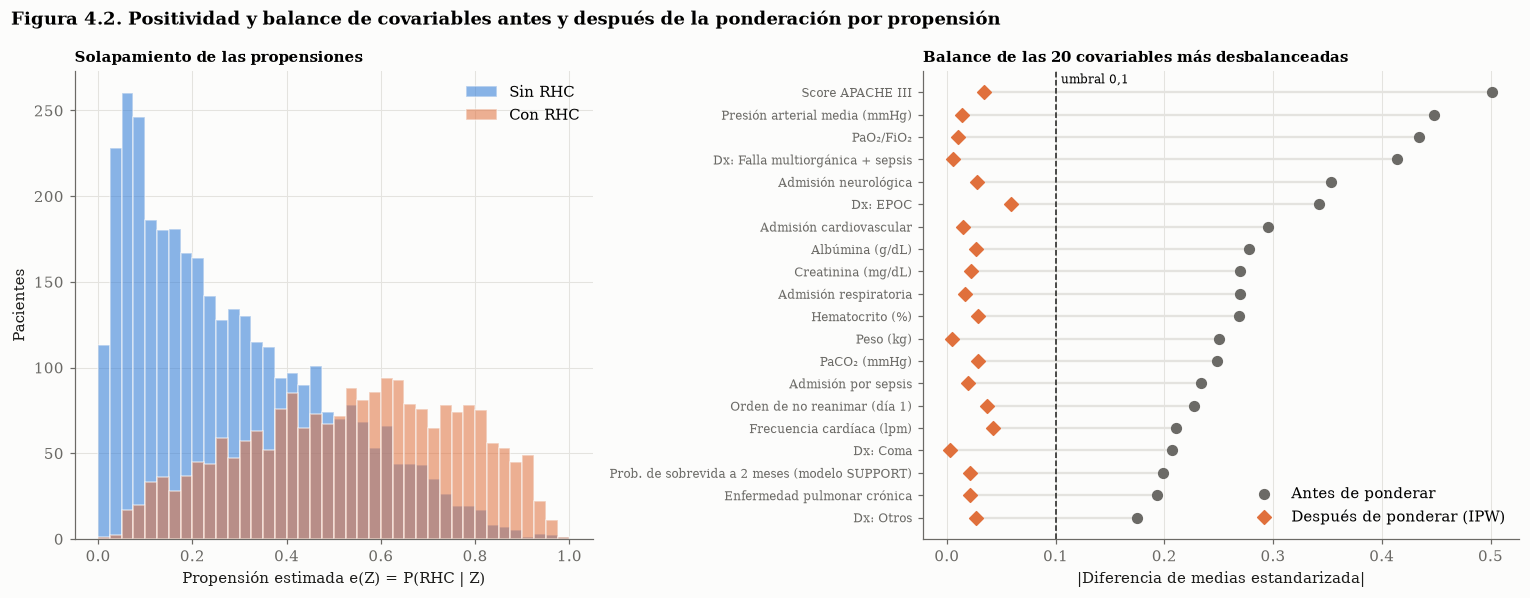

In [62]:
w_ipw = np.where(T_c == 1, 1 / ps, 1 / (1 - ps))
smd_before = cz.standardized_differences(causal_data[Z_cols], T_c)
smd_after = cz.standardized_differences(causal_data[Z_cols], T_c, w_ipw)
trimmed = cz.hajek_ipw(Y_c, T_c, ps, trim=(0.05, 0.95))
print(f"Pacientes con propensión fuera de [0,05; 0,95]: {((ps < 0.05) | (ps > 0.95)).mean():.1%}")
print(f"ATE IPW recortando esos pacientes: {trimmed['ATE']:.4f} (n = {trimmed['n']:,})")
print(f"Covariables con |diferencia estandarizada| > 0,1: antes = {(smd_before.abs() > 0.1).sum()}, "
      f"después de ponderar = {(smd_after.abs() > 0.1).sum()}")
print(f"Diferencia estandarizada máxima: antes = {smd_before.abs().max():.3f}, después = {smd_after.abs().max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.15]})
bins = np.linspace(0, 1, 41)
axes[0].hist(ps[T_c == 0], bins=bins, color=viz.NO_RHC, alpha=0.55, label="Sin RHC", edgecolor=viz.SURFACE)
axes[0].hist(ps[T_c == 1], bins=bins, color=viz.RHC, alpha=0.55, label="Con RHC", edgecolor=viz.SURFACE)
axes[0].set_xlabel("Propensión estimada e(Z) = P(RHC | Z)")
axes[0].set_ylabel("Pacientes")
axes[0].set_title("Solapamiento de las propensiones", fontsize=10)
axes[0].legend(loc="upper right")

top = smd_before.abs().sort_values(ascending=False).head(20).index[::-1]
yy = np.arange(len(top))
axes[1].scatter(smd_before[top].abs(), yy, color=viz.MUTED, s=40, label="Antes de ponderar", zorder=3)
axes[1].scatter(smd_after[top].abs(), yy, color=viz.RHC, s=40, marker="D", label="Después de ponderar (IPW)", zorder=3)
for yi, c in zip(yy, top):
    axes[1].plot([abs(smd_after[c]), abs(smd_before[c])], [yi, yi], color=viz.GRID, lw=1.5, zorder=1)
axes[1].axvline(0.1, color=viz.INK, lw=1, ls="--")
axes[1].text(0.105, len(top) - 0.6, "umbral 0,1", fontsize=8)
axes[1].set_yticks(yy, [cfg.pretty(orig_name[c]) for c in top], fontsize=8)
axes[1].set_xlabel("|Diferencia de medias estandarizada|")
axes[1].set_title("Balance de las 20 covariables más desbalanceadas", fontsize=10)
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", visible=False)
viz.figure_title(fig, "4.2", "Positividad y balance de covariables antes y después de la ponderación por propensión")
fig.tight_layout()
save(fig, "fig_4_2_propension_balance")
plt.show()

**Interpretación.** Las distribuciones de la propensión se solapan en casi todo el rango (Figura 4.2, izquierda), y solo alrededor del 6 % de los pacientes tiene propensiones extremas. Recortarlos apenas modifica el ATE, de modo que la estimación no depende de unos pocos pesos muy grandes. Antes de ponderar, 34 covariables superan el umbral convencional de desbalance de 0,1, con un máximo de 0,50 en el APACHE. Después de ponderar, **ninguna** lo supera: la pseudo-población del IPW se comporta, en las variables observadas, como un ensayo aleatorizado.

## 4.4 Batería de refutaciones

Las refutaciones de DoWhy someten la estimación a perturbaciones con resultado conocido:

| Prueba | Perturbación | Comportamiento esperado si la estimación es robusta |
|---|---|---|
| Causa común aleatoria | Agrega al modelo una covariable de ruido independiente | El ATE no cambia significativamente |
| Tratamiento placebo | Reemplaza $T$ por una permutación aleatoria | El ATE converge a cero y el contraste no es significativo ($p > 0{,}05$) |
| Subconjunto de datos | Reestima sobre submuestras aleatorias del 80 % | El ATE se mantiene dentro del intervalo de confianza original |

In [63]:
refutations = {}
for name, method, kw in [
    ("Causa común aleatoria", "random_common_cause", {}),
    ("Tratamiento placebo", "placebo_treatment_refuter", {"placebo_type": "permute"}),
    ("Subconjunto de datos (80 %)", "data_subset_refuter", {"subset_fraction": 0.8}),
]:
    r = causal_model.refute_estimate(estimand, est_lr, method_name=method, num_simulations=100,
                                     random_seed=cfg.SEED, **kw)
    refutations[name] = {"ATE original": est_lr.value, "ATE refutado": r.new_effect,
                         "p_valor": r.refutation_result["p_value"]}
ref_tab = pd.DataFrame(refutations).T
ref_tab["criterio"] = [
    "ATE estable (p > 0,05)",
    "ATE ≈ 0 (p > 0,05)",
    "ATE dentro del IC original",
]
ref_tab["supera"] = [
    ref_tab.iloc[0]["p_valor"] > 0.05,
    abs(ref_tab.iloc[1]["ATE refutado"]) < 0.01 and ref_tab.iloc[1]["p_valor"] > 0.05,
    lr_ci[0] <= ref_tab.iloc[2]["ATE refutado"] <= lr_ci[1],
]
ref_tab["semáforo"] = np.where(ref_tab["supera"], "Verde", "Rojo")
ref_tab.round(4)

,ATE original,ATE refutado,p_valor,criterio,supera,semáforo
Causa común aleatoria,0.054,0.054,0.920,"ATE estable (p > 0,05)",True,Verde
Tratamiento placebo,0.054,-0.001,0.900,"ATE ≈ 0 (p > 0,05)",True,Verde
Subconjunto de datos (80 %),0.054,0.055,0.960,ATE dentro del IC original,True,Verde


**Interpretación.** La estimación supera las tres pruebas:

- Agregar una causa común aleatoria deja el ATE prácticamente intacto.
- Con un tratamiento placebo el efecto se desvanece a un valor cercano a cero, como corresponde a un tratamiento que por construcción no tiene efecto.
- Las submuestras del 80 % reproducen el ATE dentro del intervalo de confianza original.

Estas pruebas certifican que la estimación es **estable y no es un artefacto del estimador ni de una submuestra particular**. No certifican la ausencia de confusores no observados: una causa común aleatoria es, por construcción, independiente de $T$ y de $Y$. Esa amenaza requiere un análisis específico.

## 4.5 Sensibilidad a la confusión no observada: E-value

El E-value (VanderWeele y Ding, 2017) responde la pregunta: **¿qué tan fuerte debería ser un confusor no observado para explicar todo el efecto estimado?** Se expresa en la escala del riesgo relativo: es la asociación mínima que $U$ debería tener simultáneamente con el tratamiento y con la mortalidad para anular el resultado.

$$E = RR + \sqrt{RR\,(RR - 1)}$$

In [64]:
ipw_full = cz.hajek_ipw(Y_c, T_c, ps)
rr = ipw_full["mu1"] / ipw_full["mu0"]
rr_low = (ipw_full["mu0"] + ipw_ci[0]) / ipw_full["mu0"]
ev, ev_low = cz.e_value(rr), cz.e_value(rr_low)
print(f"Mortalidad potencial a 30 días: con RHC = {ipw_full['mu1']:.3f} · sin RHC = {ipw_full['mu0']:.3f}")
print(f"Riesgo relativo causal (IPW) = {rr:.3f} · límite inferior del IC 95 % = {rr_low:.3f}")
print(f"E-value del estimador puntual = {ev:.2f} · E-value del límite inferior del IC = {ev_low:.2f}")

Mortalidad potencial a 30 días: con RHC = 0.372 · sin RHC = 0.313
Riesgo relativo causal (IPW) = 1.191 · límite inferior del IC 95 % = 1.084
E-value del estimador puntual = 1.67 · E-value del límite inferior del IC = 1.38


**Interpretación.** Para que el efecto dañino del RHC fuera enteramente producto de confusión no observada, haría falta un confusor asociado tanto con la decisión de cateterizar como con la mortalidad con un riesgo relativo de alrededor de 1,7 cada una, **después de ajustar por las 67 covariables observadas**. Para llevar el límite inferior del intervalo al cero alcanzaría con un confusor más débil, de alrededor de 1,4.

Es un valor moderado. El criterio clínico no registrado (la "impresión" del médico sobre la gravedad) podría plausiblemente alcanzar esa magnitud, sobre todo porque el APACHE y la fisiología ya capturan gran parte de la gravedad medible. Por eso la conclusión correcta no es "el RHC mata", sino que **no hay evidencia de beneficio y la evidencia disponible apunta a un daño moderado**, que solo un confusor no observado de magnitud relevante podría explicar.

### Sensibilidad a la especificación del conjunto de ajuste

Dos covariables merecen una verificación específica. La **orden de no reanimar** se registra el día 1, posiblemente en simultáneo con la decisión de cateterizar: si el RHC influyera sobre ella, sería un mediador y no debería ajustarse. La **probabilidad de sobrevida estimada por SUPPORT** es una función de otras covariables ya incluidas. Se reestima el ATE excluyendo cada una.

In [65]:
spec = {"Conjunto completo Z": Z_cols,
        "Z sin orden de no reanimar": [c for c in Z_cols if c != "dnr1"],
        "Z sin probabilidad de sobrevida": [c for c in Z_cols if c != "surv2md1"]}
spec_tab = []
for name, cols in spec.items():
    fit = sm.OLS(Y_c, sm.add_constant(causal_data[[cfg.TREATMENT] + cols])).fit(cov_type="HC3")
    ci = fit.conf_int().loc[cfg.TREATMENT]
    spec_tab.append({"especificación": name, "ATE": fit.params[cfg.TREATMENT], "IC_inf": ci[0], "IC_sup": ci[1]})
pd.DataFrame(spec_tab).set_index("especificación").round(4)

,ATE,IC_inf,IC_sup
especificación,,,
Conjunto completo Z,0.054,0.028,0.080
Z sin orden de no reanimar,0.044,0.017,0.070
Z sin probabilidad de sobrevida,0.063,0.037,0.089


**Interpretación.** El ATE se desplaza alrededor de un punto porcentual: baja a 4,4 puntos al excluir la orden de no reanimar y sube a 6,3 al excluir la probabilidad de sobrevida. En las tres especificaciones el efecto sigue siendo positivo y su intervalo excluye el cero. La magnitud exacta depende moderadamente del conjunto de ajuste, pero la conclusión cualitativa (ausencia de beneficio y daño moderado) no depende de tratar la orden de no reanimar como confusor ni de incluir un resumen pronóstico redundante.

## 4.6 Causal Machine Learning: Double Machine Learning y efectos heterogéneos

El ATE es un promedio. La dirección médica necesita saber además **para quién** el procedimiento es dañino, neutro o eventualmente beneficioso. El efecto causal promedio condicional (CATE) es:

$$\tau(x) = E[Y(1) - Y(0) \mid X = x]$$

**Double Machine Learning** (Chernozhukov et al., 2018) estima $\tau(x)$ en tres pasos:

1. Un Random Forest predice el resultado a partir de las covariables, $\hat{E}[Y \mid X, W]$, y otro predice el tratamiento, $\hat{E}[T \mid X, W]$.
2. Ambas predicciones se obtienen por *cross-fitting* (cada paciente se predice con modelos entrenados sin él) y se calculan los residuos $\tilde{Y} = Y - \hat{E}[Y \mid X, W]$ y $\tilde{T} = T - \hat{E}[T \mid X, W]$.
3. Se regresa $\tilde{Y}$ sobre $\tilde{T}$ interactuado con los modificadores de efecto $X$. Al trabajar con residuos ortogonales, los errores de los modelos de ruido afectan la estimación solo en segundo orden.

**Especificación.** Los modificadores de efecto $X$ son la gravedad (APACHE III), la edad y el diagnóstico de ingreso. Los demás confusores entran como controles $W$. Se usa `LinearDML`, que produce una función de CATE con intervalos de confianza válidos, y `CausalForestDML` como verificación no paramétrica.

In [66]:
dd = data.loc[causal_data.index]
dx_cols = [c for c in Z_cols if c.startswith("dx_")]
X_mod = pd.concat([dd[["aps1", "age"]], causal_data[dx_cols]], axis=1)
W_ctrl = causal_data[[c for c in Z_cols if c not in ["aps1", "age"] + dx_cols]]

def rf_nuisance():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=cfg.SEED, n_jobs=-1)

dml = LinearDML(model_y=rf_nuisance(), model_t=rf_nuisance(), discrete_treatment=True, discrete_outcome=True,
                cv=3, random_state=cfg.SEED)
dml.fit(Y_c, T_c, X=X_mod.to_numpy(float), W=W_ctrl.to_numpy(float))
def scalar(v):
    return float(np.ravel(v)[0])

ate_dml = scalar(dml.ate(X_mod.to_numpy(float)))
ate_dml_ci = [scalar(v) for v in dml.ate_interval(X_mod.to_numpy(float))]
print(f"ATE por Double ML: {ate_dml:.4f} · IC 95 % = [{ate_dml_ci[0]:.4f}; {ate_dml_ci[1]:.4f}]")

coef = pd.DataFrame({"coeficiente": dml.coef_, "IC_inf": dml.coef__interval()[0], "IC_sup": dml.coef__interval()[1]},
                    index=[cfg.pretty(orig_name.get(c, c)) for c in X_mod.columns])
coef.round(4)

ATE por Double ML: 0.0391 · IC 95 % = [0.0127; 0.0656]


,coeficiente,IC_inf,IC_sup
Score APACHE III,0.001,-0.001,0.002
Edad (años),0.001,-0.000,0.003
Dx: Falla multiorgánica + sepsis,0.044,-0.024,0.112
Dx: Falla multiorgánica + cáncer,0.015,-0.099,0.129
Dx: Insuf. cardíaca,-0.013,-0.094,0.069
Dx: EPOC,0.007,-0.118,0.132
Dx: Coma,-0.080,-0.197,0.037
Dx: Otros,-0.081,-0.237,0.074


In [67]:
base = X_mod.median().to_frame().T
grid = np.arange(15, 136, 5)
curve = []
for a in grid:
    xa = base.copy()
    xa["aps1"] = a
    lo, hi = dml.effect_interval(xa.to_numpy(float))
    curve.append({"APACHE": a, "CATE": scalar(dml.effect(xa.to_numpy(float))), "IC_inf": scalar(lo), "IC_sup": scalar(hi)})
curve = pd.DataFrame(curve)

cf = CausalForestDML(model_y=rf_nuisance(), model_t=rf_nuisance(), discrete_treatment=True, discrete_outcome=True,
                     cv=3, n_estimators=400, min_samples_leaf=20, random_state=cfg.SEED)
X_cf = X_mod.assign(surv2md1=dd["surv2md1"])
cf.fit(Y_c, T_c, X=X_cf.to_numpy(float), W=W_ctrl.to_numpy(float))
cate_cf = pd.Series(cf.effect(X_cf.to_numpy(float)).ravel(), index=dd.index)

subgroups = []
for g in cfg.DX_ORDER:
    mask = (dd["dx"] == g).to_numpy()
    Xg = X_mod[mask].to_numpy(float)
    lo, hi = dml.ate_interval(Xg)
    subgroups.append({"diagnóstico": g, "n": int(mask.sum()), "CATE (LinearDML)": scalar(dml.ate(Xg)),
                      "IC_inf": scalar(lo), "IC_sup": scalar(hi), "CATE (bosque causal)": cate_cf[mask].mean()})
subgroups = pd.DataFrame(subgroups).set_index("diagnóstico")
subgroups["lectura"] = np.where(subgroups["IC_inf"] > 0, "Dañino",
                                np.where(subgroups["IC_sup"] < 0, "Beneficioso", "Sin efecto demostrable"))
subgroups.round(4)

,n,CATE (LinearDML),IC_inf,IC_sup,CATE (bosque causal),lectura
diagnóstico,,,,,,
Insuf. respiratoria aguda,2490,0.038,-0.000,0.076,0.047,Sin efecto demostrable
Falla multiorgánica + sepsis,1226,0.090,0.036,0.145,0.064,Dañino
Falla multiorgánica + cáncer,399,0.061,-0.043,0.166,0.011,Sin efecto demostrable
Insuf. cardíaca,456,0.015,-0.052,0.083,0.027,Sin efecto demostrable
EPOC,457,0.049,-0.069,0.167,0.048,Sin efecto demostrable
Coma,436,-0.046,-0.158,0.065,0.006,Sin efecto demostrable
Otros,270,-0.053,-0.204,0.097,0.029,Sin efecto demostrable


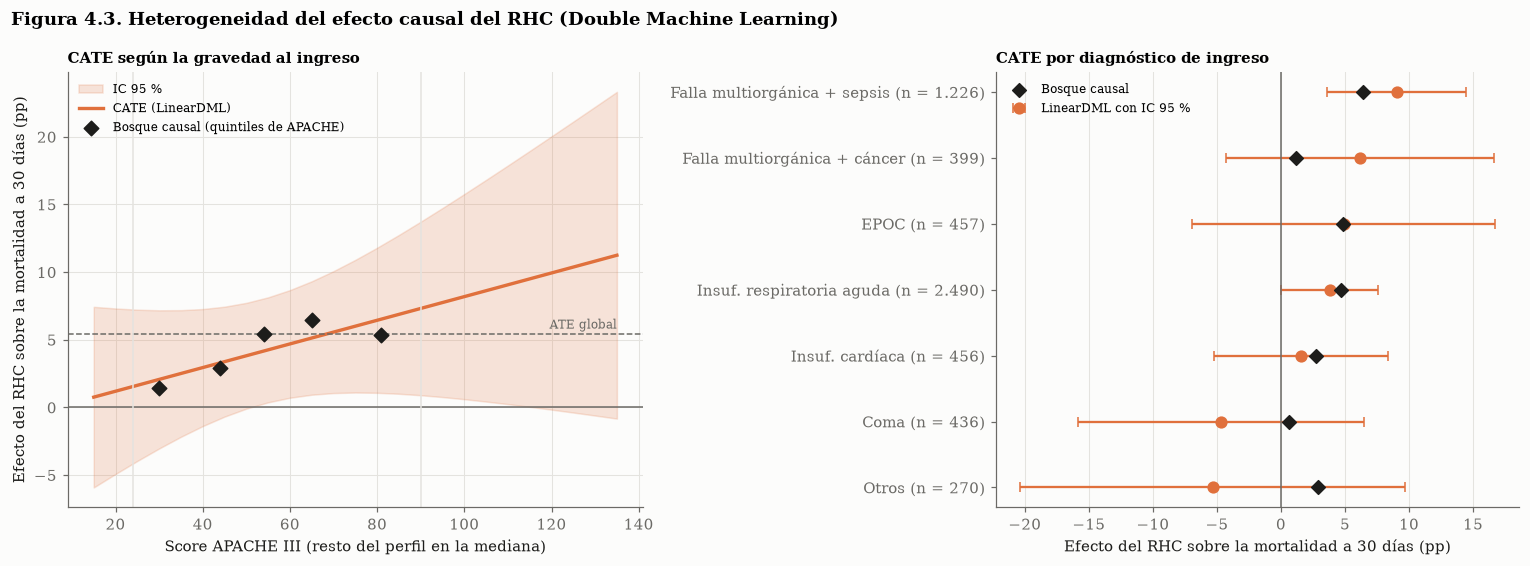

,APACHE,CATE,IC_inf,IC_sup
0,15,0.008,-0.059,0.074
4,35,0.025,-0.022,0.072
8,55,0.043,0.004,0.081
12,75,0.060,0.011,0.109
16,95,0.077,0.008,0.147
20,115,0.095,0.001,0.190
24,135,0.113,-0.008,0.233


In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.fill_between(curve["APACHE"], 100 * curve["IC_inf"], 100 * curve["IC_sup"], color=viz.RHC, alpha=0.18, label="IC 95 %")
ax.plot(curve["APACHE"], 100 * curve["CATE"], color=viz.RHC, lw=2.2, label="CATE (LinearDML)")
q = pd.qcut(dd["aps1"], 5)
cf_q = cate_cf.groupby(q, observed=True).mean()
mid = dd.groupby(q, observed=True)["aps1"].median()
ax.scatter(mid, 100 * cf_q, color=viz.INK, marker="D", s=45, zorder=3, label="Bosque causal (quintiles de APACHE)")
ax.axhline(0, color=viz.MUTED, lw=1)
ax.axhline(100 * est_lr.value, color=viz.MUTED, lw=1, ls="--")
ax.text(grid[-1], 100 * est_lr.value + 0.4, "ATE global", ha="right", fontsize=8, color=viz.MUTED)
for pct in (0.05, 0.95):
    ax.axvline(dd["aps1"].quantile(pct), color=viz.GRID, lw=1)
ax.set_xlabel("Score APACHE III (resto del perfil en la mediana)")
ax.set_ylabel("Efecto del RHC sobre la mortalidad a 30 días (pp)")
ax.set_title("CATE según la gravedad al ingreso", fontsize=10)
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
sg = subgroups.sort_values("CATE (LinearDML)")
yy = np.arange(len(sg))
ax.errorbar(100 * sg["CATE (LinearDML)"], yy, xerr=[100 * (sg["CATE (LinearDML)"] - sg["IC_inf"]),
            100 * (sg["IC_sup"] - sg["CATE (LinearDML)"])], fmt="o", ms=7, color=viz.RHC, capsize=3, lw=1.5,
            label="LinearDML con IC 95 %")
ax.scatter(100 * sg["CATE (bosque causal)"], yy, color=viz.INK, marker="D", s=40, zorder=3, label="Bosque causal")
ax.axvline(0, color=viz.MUTED, lw=1)
ax.set_yticks(yy, [f"{i} (n = {n:,})".replace(",", ".") for i, n in zip(sg.index, sg["n"])])
ax.set_xlabel("Efecto del RHC sobre la mortalidad a 30 días (pp)")
ax.set_title("CATE por diagnóstico de ingreso", fontsize=10)
ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="y", visible=False)
viz.figure_title(fig, "4.3", "Heterogeneidad del efecto causal del RHC (Double Machine Learning)")
fig.tight_layout()
save(fig, "fig_4_3_cate")
plt.show()
curve.iloc[::4].round(4)

**Interpretación de la heterogeneidad.**

- **El ATE por Double ML** (alrededor de 3,9 puntos porcentuales) es algo menor que el de la regresión lineal y el del IPW, pero su intervalo también excluye el cero. Que tres estimadores con supuestos distintos (lineal, ponderación por propensión y residuos ortogonales con modelos no lineales) coincidan en signo y orden de magnitud es la evidencia más sólida del análisis.
- **Gravedad.** La estimación puntual del daño crece con el APACHE (Figura 4.3, izquierda). En pacientes con gravedad baja (APACHE de 20 a 30) el efecto es pequeño, de 1 a 2 puntos porcentuales, y su intervalo incluye el cero. Entre un APACHE de 55 y 115 el intervalo excluye el cero y el efecto supera los 4 puntos. Por encima de 115 el intervalo vuelve a ensancharse, porque menos del 5 % de los pacientes tiene esa gravedad. El bosque causal, sin imponer linealidad, reproduce el mismo gradiente por quintiles. **Una cautela:** el coeficiente que mide la pendiente del CATE respecto del APACHE tiene un intervalo de confianza que incluye el cero. La heterogeneidad por gravedad debe leerse, por lo tanto, como un indicio consistente entre dos métodos y no como un hallazgo concluyente. Si se confirmara, sería contraintuitivo: el procedimiento se indica con más frecuencia en los pacientes más graves, que es donde el análisis estima el mayor daño.
- **Diagnóstico.** La **falla multiorgánica con sepsis** es el único subgrupo con daño claramente demostrado: alrededor de 9 puntos porcentuales, con un intervalo que excluye el cero. En la insuficiencia respiratoria aguda el efecto es positivo, con un intervalo que roza el cero. En **coma** y en el grupo "otros", la estimación puntual es nula o levemente negativa, sin evidencia de efecto en ninguna dirección. **No se identifica ningún subgrupo en el que el RHC sea beneficioso** con significancia estadística.

**Lectura de negocio.** El RHC no es costo-efectivo en ningún subgrupo identificado: es un procedimiento invasivo y costoso que, en el mejor de los casos (pacientes de baja gravedad, coma), no modifica la mortalidad, y en el peor (sepsis, APACHE alto) la aumenta. La política recomendada es **abandonar su uso rutinario** y reservarlo para indicaciones específicas no capturadas en este análisis, bajo protocolos que controlen la intensificación terapéutica que desencadena.

## 4.7 Persistencia de los resultados causales para la aplicación web

In [69]:
cate_grid = []
for g in cfg.DX_ORDER:
    for age in (40, 55, 70, 85):
        for a in range(15, 141, 5):
            x = base.copy()
            x["aps1"], x["age"] = a, age
            for c in dx_cols:
                x[c] = 1.0 if c == cz.safe_name("dx_" + g) else 0.0
            lo, hi = dml.effect_interval(x.to_numpy(float))
            cate_grid.append({"dx": g, "edad": age, "aps1": a, "cate": round(scalar(dml.effect(x.to_numpy(float))), 5),
                              "ic_inf": round(scalar(lo), 5), "ic_sup": round(scalar(hi), 5)})
causal_results = {
    "tratamiento": cfg.TREATMENT, "resultado": cfg.OUTCOME_BIN, "n": int(len(causal_data)),
    "ate": {name: {"valor": round(float(r["ATE (diferencia de riesgo)"]), 5), "ic_inf": round(float(r["IC_inf"]), 5),
                   "ic_sup": round(float(r["IC_sup"]), 5)} for name, r in ate_tab.iterrows()},
    "ate_dml": {"valor": round(ate_dml, 5), "ic_inf": round(ate_dml_ci[0], 5), "ic_sup": round(ate_dml_ci[1], 5)},
    "refutaciones": {name: {"ate_refutado": round(float(r["ATE refutado"]), 5), "p_valor": round(float(r["p_valor"]), 4),
                            "criterio": r["criterio"], "supera": bool(r["supera"])} for name, r in ref_tab.iterrows()},
    "e_value": {"puntual": round(float(ev), 3), "limite_inferior": round(float(ev_low), 3)},
    "subgrupos": subgroups.drop(columns="lectura").round(5).reset_index().to_dict(orient="records"),
    "cate_grilla": cate_grid,
}
(cfg.MODELS_DIR / "resultados_causales.json").write_text(json.dumps(causal_results, indent=1, ensure_ascii=False))
print(f"Resultados causales guardados: {len(cate_grid):,} puntos de la grilla de CATE, "
      f"{len(ref_tab)} refutaciones y {len(subgroups)} subgrupos.")

Resultados causales guardados: 728 puntos de la grilla de CATE, 3 refutaciones y 7 subgrupos.


## 4.8 Ensayo crítico: el choque entre la predicción y la causalidad

**Pregunta 1. Si la variable $X_k$ resultó la de mayor importancia en el Random Forest de la Fase 3, ¿puede la dirección ejecutiva considerarla una palanca para intervenir el sistema?**

En este trabajo, $X_k$ es la **probabilidad de sobrevida a 2 meses estimada por el modelo SUPPORT**: primera tanto por MDI como por permutación en test, raíz del árbol podado y variable con el odds ratio más fuerte de la regresión logística (cada 0,1 adicional reduce las chances de muerte en alrededor de 27 %). Sin embargo, **no es una palanca**.

La razón es que esta variable no es una causa de la sobrevida, sino una **medición resumida de sus causas**. Es la salida de un modelo pronóstico que combina el APACHE, la edad, el diagnóstico y la escala de coma. En el lenguaje del DAG, es un nodo descendiente de la gravedad fisiológica ($Z_3 \rightarrow X_k$) sin flecha propia hacia $Y$, más allá de la que ya transmiten sus componentes. Intervenir sobre ella, $do(X_k = 0{,}9)$, no tiene contenido clínico: no existe acción médica que modifique el puntaje sin modificar la fisiología que lo genera. Si se lo manipulara (por ejemplo, premiando a los equipos por "mejorar" el pronóstico estimado), el indicador perdería su relación con la mortalidad, que es la advertencia de la ley de Goodhart. Lo que sí es una palanca es la gravedad subyacente (corregir la presión arterial o la oxigenación), y su efecto causal debería estimarse con su propio DAG.

La pregunta vale con más fuerza para el propio RHC, que sí es manipulable. El Random Forest lo ubica entre las diez variables más importantes por permutación, y la regresión logística le asigna un OR de 1,33. Si la dirección leyera esa asociación como causal, concluiría que el RHC eleva un 33 % las chances de muerte, cuando la parte atribuible a la confusión por indicación representa más de un cuarto del efecto ingenuo. **La importancia predictiva mide cuánta información aporta una variable para anticipar $Y$ dado todo lo demás; no mide qué pasaría con $Y$ si se cambiara esa variable.** Las dos cantidades coinciden solo bajo los supuestos de identificación de la sección 4.2.

**Pregunta 2. ¿En qué condiciones una variable altamente predictiva carece por completo de poder causal, o incluso tiene un efecto causal de signo opuesto al de su coeficiente correlacional?**

1. **Cuando es un marcador o proxy de la causa verdadera.** Es el caso de la probabilidad de sobrevida estimada. Lo mismo ocurre con la orden de no reanimar (OR ≈ 2,8): predice la muerte porque refleja un pronóstico grave y una decisión de limitar el esfuerzo terapéutico, no porque la firma del formulario produzca la muerte.
2. **Cuando la causalidad es inversa.** Los días de internación se correlacionan negativamente con la mortalidad (−0,42): las estadías largas "predicen" sobrevida. Pero es la muerte la que acorta la estadía. Prolongar artificialmente la internación no salvaría a nadie.
3. **Cuando hay confusión por indicación.** Si un tratamiento se reserva para los más graves, su correlación con la mortalidad será positiva aunque sea beneficioso: la gravedad empuja a la vez al tratamiento y a la muerte. Con suficiente confusión, el signo correlacional puede ser **opuesto** al causal (paradoja de Simpson). En este dataset la confusión no llega a invertir el signo, pero reduce el efecto ingenuo en más de un cuarto, y en subgrupos como coma la estimación causal es nula o levemente negativa pese a la asociación global positiva.
4. **Cuando se condiciona sobre un colisionador.** Al ajustar por los días de internación, la estimación del efecto del RHC se desplaza sin ninguna base causal (sección 4.2). Cualquier análisis restringido a "pacientes con estadía mayor a X días" o a "pacientes dados de alta" introduce ese sesgo de selección.
5. **Cuando se ajusta por un mediador.** Una variable que transmite el efecto del tratamiento puede absorber todo su poder predictivo en un modelo y hacer que el tratamiento parezca inocuo, como mostró la simulación.

**Conclusión del ensayo.** Un modelo predictivo responde "¿quién va a morir?"; un modelo causal responde "¿qué decisión cambia quién va a morir?". El torneo de la Fase 3 sirve para estratificar el riesgo y asignar recursos de monitoreo; **no** sirve para elegir intervenciones. Para elegirlas, la dirección necesita variables manipulables, un DAG explícito, un conjunto de ajuste que cumpla el criterio backdoor, estimadores con supuestos distintos que coincidan y una evaluación honesta de la confusión no observada. Aplicado al RHC, ese proceso concluye que el procedimiento no reduce la mortalidad y probablemente la aumenta en unos 4 a 6 puntos porcentuales, con el daño concentrado en los pacientes más graves y sépticos. Los ensayos clínicos aleatorizados posteriores (Harvey et al., 2005; ESCAPE Investigators, 2005) tampoco encontraron beneficio en mortalidad.

## 4.9 Síntesis de la Fase 4

| Componente | Resultado |
|---|---|
| Identificación | El conjunto $Z$ de 67 covariables basales cumple el criterio backdoor; DoWhy excluye el colisionador y el mediador |
| Efecto ingenuo | +7,4 pp de mortalidad a 30 días |
| ATE ajustado | +5,4 pp (regresión), +5,9 pp (IPW), +3,9 pp (Double ML); los tres intervalos excluyen el cero |
| Sesgo de confusión | Positivo, de alrededor de 2 pp: la confusión por indicación sobrestima el daño |
| Refutaciones | Las tres pruebas superadas (semáforo verde) |
| Confusión no observada | E-value de 1,7 (1,4 para el límite inferior): un confusor moderado podría explicar el efecto |
| Heterogeneidad | Daño demostrado en sepsis (+9 pp); indicio de mayor daño con APACHE alto (pendiente no significativa); sin efecto demostrable en baja gravedad y coma; ningún subgrupo con beneficio |
| Recomendación | Abandonar el uso rutinario del RHC en la unidad de cuidados intensivos |